# DataInsight | Text: Phát hiện review spam trên sàn thương mại điện tử Việt Nam (UIT-ViSpamReviews)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/trthminh/CO5177/blob/main/notebooks/text.ipynb)

| | |
|---|---|
| **Môn học** | Nền tảng lập trình cho phân tích và trực quan dữ liệu (CO5177), HK 261, 2026–2027 |
| **Giảng viên** | Lê Thành Sách, Khoa Khoa học và Kỹ thuật Máy tính, ĐH Bách Khoa – ĐHQG-HCM |
| **Nhóm** | DataInsight: Trương Thanh Minh (2580893), Tô Anh Phát (2580894), Trần Lê Hoàng Long (2570443) |
| **Phụ trách notebook** | Tô Anh Phát (2580894) |
| **Dữ liệu** | [UIT-ViSpamReviews](https://github.com/sonlam1102/vispamdetection) (Van Dinh, Luu, Nguyen, ACIIDS 2022), giấy phép CC BY-NC 4.0, dùng cho nghiên cứu |
| **Bài toán** | Phân loại review tiếng Việt: spam hay không (tác vụ 1) và loại spam (tác vụ 2) |

**Mô tả bài toán.** Các sàn thương mại điện tử có rất nhiều review không nói về sản phẩm: lời khen copy-paste, review chỉ cảm ơn shop hay khen giao hàng, hoặc chuỗi ký tự vô nghĩa. Những review này làm người mua hiểu sai về sản phẩm. Từ nội dung review (và số sao), ta muốn dự đoán review đó có phải spam không. Notebook đi từ dữ liệu đến mô hình: tải dữ liệu, kiểm tra chất lượng, phân tích khám phá (EDA), rồi dùng các phát hiện của EDA để chuẩn bị dữ liệu, chọn đặc trưng và mô hình. Thước đo chính là **F1-macro**, giống bài báo gốc.

**Mục lục**
1. [Thiết lập](#scrollTo=s1)
2. [Tải dữ liệu](#scrollTo=s2)
3. [Mô tả dữ liệu](#scrollTo=s3)
4. [Kiểm tra chất lượng dữ liệu](#scrollTo=s4)
5. [Phân tích khám phá (EDA)](#scrollTo=s5)
6. [Chuẩn bị dữ liệu](#scrollTo=s6)
7. [Xây dựng mô hình](#scrollTo=s7)
8. [Đánh giá trên tập test](#scrollTo=s8)
9. [Dự đoán review mới](#scrollTo=s9)
10. [Kết luận](#scrollTo=s10)

<a id="scrollTo=s1"></a>
## 1. Thiết lập

### 1.1 Cài thư viện còn thiếu

In [1]:
import importlib.util
import subprocess
import sys

REQUIRED_PACKAGES = {
    "numpy": "numpy",
    "pandas": "pandas>=2.0",
    "sklearn": "scikit-learn>=1.2",
    "plotly": "plotly>=5.15",
    "jinja2": "jinja2",            # pandas cần jinja2 để hiển thị bảng có định dạng (Styler)
    "underthesea": "underthesea",  # tách từ tiếng Việt (mục 3.1)
}

missing = [pip_name for module_name, pip_name in REQUIRED_PACKAGES.items()
           if importlib.util.find_spec(module_name) is None]
if missing:
    print("Đang cài:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("Đã có đủ thư viện cần thiết.")

Đã có đủ thư viện cần thiết.


### 1.2 Import thư viện

In [2]:
import itertools
import os
import time
import re
import unicodedata
import urllib.request
import warnings
import zipfile
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import display
from plotly.subplots import make_subplots
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, MaxAbsScaler
from sklearn.svm import LinearSVC
from underthesea import word_tokenize

# pandas cảnh báo khi biểu thức chính quy có nhóm (...); ở đây ta dùng nhóm có chủ đích.
warnings.filterwarnings("ignore", message="This pattern is interpreted as a regular expression")
# Trên một số máy (ví dụ macOS), numpy báo nhầm "... encountered in matmul" khi huấn luyện LogisticRegression;
# đây là cờ lỗi giả của thư viện tính toán, kết quả không bị ảnh hưởng.
warnings.filterwarnings("ignore", message=".*encountered in matmul")

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.3.3 | numpy 2.2.6


### 1.3 Cấu hình

In [3]:
SEED = 42

# Bản v1 chính thức trong repo GitHub của tác giả
DATA_URL = "https://raw.githubusercontent.com/sonlam1102/vispamdetection/main/dataset/vispamdetection_dataset.zip"
DATA_DIR = Path("data")
ZIP_PATH = DATA_DIR / "vispamdetection_dataset.zip"
SPLIT_FILES = {
    "train": "dataset/train.csv",
    "dev": "dataset/dev.csv",
    "test": "dataset/test.csv",
}

TEXT_COL = "Comment"
RATING_COL = "Rating"
LABEL_COL = "Label"           # tác vụ 1: 0 = không spam, 1 = spam
TYPE_COL = "SpamLabel"        # tác vụ 2: 0 = không spam, 1/2/3 = loại spam

LABEL_NAMES = {0: "NO-SPAM", 1: "SPAM"}
TYPE_NAMES = {
    0: "NO-SPAM",
    1: "SPAM-1 review giả",
    2: "SPAM-2 chỉ nói shop/hãng",
    3: "SPAM-3 không phải review",
}

# Một token là một chuỗi chữ hoặc số liền nhau. Mặc định của scikit-learn bỏ các token 1 ký tự,
# sẽ làm mất các tiếng như "ở", "à", "ạ", "k" (viết tắt của "không"), nên ta dùng mẫu riêng.
# Dấu "_" cũng là ký tự chữ, nên một từ đã tách như "sản_phẩm" vẫn là một token.
TOKEN_PATTERN = r"(?u)\b\w+\b"

# Đặt biến môi trường EXPORT_FIGURES=1 để lưu thêm mọi hình thành PNG cho báo cáo.
EXPORT_FIGURES = os.getenv("EXPORT_FIGURES", "0") == "1"
FIGURE_DIR = Path("figures") / "text"

### 1.4 Hàm vẽ biểu đồ và hiển thị bảng

In [4]:
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
RED, MUTED, GRID = "#e34948", "#898781", "#e1e0d9"
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

LABEL_COLORS = {"NO-SPAM": BLUE, "SPAM": RED}
TYPE_COLORS = dict(zip(TYPE_NAMES.values(), [BLUE, YELLOW, AQUA, ORANGE]))

pio.templates["datainsight"] = go.layout.Template(layout=dict(
    font=dict(family="Inter, Segoe UI, Arial, sans-serif", size=13, color="#0b0b0b"),
    colorway=[BLUE, ORANGE, AQUA, YELLOW, RED, MUTED],
    paper_bgcolor="#ffffff", plot_bgcolor="#ffffff",
    title=dict(x=0.01, font=dict(size=16)),
    xaxis=dict(gridcolor=GRID, linecolor="#c9c8c3", zeroline=False, title_font_color="#52514e"),
    yaxis=dict(gridcolor=GRID, linecolor="#c9c8c3", zeroline=False, title_font_color="#52514e"),
    legend=dict(orientation="h", yanchor="bottom", y=1.02, x=0, title_text=""),
    hoverlabel=dict(bgcolor="#ffffff", font_size=13),
    margin=dict(l=60, r=20, t=80, b=50),
))
pio.templates.default = "plotly_white+datainsight"
# "notebook" chép thư viện JavaScript của Plotly vào notebook một lần, nhờ vậy biểu đồ
# hiển thị được cả trong VS Code và trong file HTML xuất ra, kể cả khi không có mạng.
# GitHub không chạy JavaScript nên chỉ hiện được ảnh tĩnh: nếu có gói kaleido, mỗi hình lưu kèm một ảnh PNG
# (sau khi chạy, scripts/plotly_static_for_github.py bỏ phần HTML để GitHub chọn ảnh này).
# Colab đặt mỗi kết quả trong một khung riêng nên cần renderer "colab".
if "google.colab" in sys.modules:
    pio.renderers.default = "colab"
else:
    pio.renderers.default = "plotly_mimetype+notebook" + ("+png" if importlib.util.find_spec("kaleido") else "")

BOTTOM_LEGEND = dict(orientation="h", yanchor="top", y=-0.25, x=0, traceorder="normal")

figure_counter = itertools.count(1)


def show_fig(fig, title, height=450, **layout):
    """Thêm tiêu đề "Hình N. ...", hiển thị hình, và lưu PNG nếu bật EXPORT_FIGURES."""
    number = next(figure_counter)
    fig.update_layout(title=f"Hình {number}. {title}", height=height, **layout)
    fig.show()
    if EXPORT_FIGURES:  # cần gói kaleido
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        fig.write_image(FIGURE_DIR / f"hinh_{number:02d}.png", width=1100, height=height, scale=2)


def format_number(value, precision=1):
    """Viết số theo chuẩn của báo cáo: dấu chấm thập phân (85.4), số từ 5 chữ số tách hàng nghìn
    bằng khoảng trắng hẹp (19 870), số 4 chữ số viết liền (7280)."""
    if isinstance(value, (bool, np.bool_)):
        return value
    if isinstance(value, (int, np.integer)):
        return f"{value:,}".replace(",", "\u2009") if abs(value) >= 10000 else str(value)
    if isinstance(value, (float, np.floating)):
        return f"{value:.{precision}f}"
    return value


def show_table(table, caption, text_columns=(), hide_index=False, precision=1):
    """Hiển thị bảng có tiêu đề; các cột văn bản được căn trái và tự xuống dòng để đọc hết nội dung."""
    if isinstance(table, pd.Series):
        table = table.to_frame()
    styler = table.style.set_caption(caption).format(lambda value: format_number(value, precision))
    styler = styler.set_table_styles([
        {"selector": "caption", "props": "caption-side: top; text-align: left; font-weight: bold; padding: 6px 0;"},
        {"selector": "th", "props": "text-align: left;"},
        {"selector": "td", "props": "text-align: left; vertical-align: top;"},
    ])
    if text_columns:
        styler = styler.set_properties(subset=list(text_columns), **{
            "white-space": "pre-wrap", "min-width": "320px", "max-width": "760px"})
    if hide_index:
        styler = styler.hide(axis="index")
    display(styler)

<a id="scrollTo=s2"></a>
## 2. Tải dữ liệu

### 2.1 Tải file zip

In [5]:
def download_file(url, target_path):
    """Tải url về target_path nếu file chưa tồn tại."""
    if target_path.exists():
        print(f"Đã có sẵn: {target_path}")
        return target_path
    target_path.parent.mkdir(parents=True, exist_ok=True)
    print(f"Đang tải {url}")
    urllib.request.urlretrieve(url, target_path)
    return target_path


download_file(DATA_URL, ZIP_PATH)
with zipfile.ZipFile(ZIP_PATH) as archive:
    for info in archive.infolist():
        print(f"  {info.filename:<22} {info.file_size / 1e6:.2f} MB")

Đã có sẵn: data/vispamdetection_dataset.zip
  dataset/test.csv       0.67 MB
  dataset/dev.csv        0.26 MB
  dataset/train.csv      2.37 MB


### 2.2 Đọc ba tập vào một bảng

Tác giả đã chia sẵn train, dev và test. Ta ghép ba file thành một bảng `df` và thêm cột `split` để biết review thuộc tập nào.

**Gộp ba tập như vậy có gây rò rỉ dữ liệu không?** Rò rỉ xảy ra khi thông tin của tập test ảnh hưởng đến các quyết định xây dựng mô hình. Vì vậy notebook chia việc như sau:

| Phần | Dữ liệu dùng | Lý do |
|---|---|---|
| 3 và 4.1 đến 4.5: mô tả, kiểm tra lỗi, trùng lặp, chuẩn hóa | Cả ba tập (`df`) | Lỗi dữ liệu phải được phát hiện ở mọi tập; trùng lặp giữa các tập chỉ thấy được khi đặt chúng cạnh nhau. Các review ví dụ có kèm nhãn thì vẫn lấy từ tập train |
| 4.6 trở đi: chính tả, dấu hiệu văn bản và toàn bộ EDA ở phần 5 | **Chỉ tập train** (`train`) | Các phát hiện ở đây sẽ quyết định cách làm sạch và chọn đặc trưng, nên không được nhìn vào dev và test |

Chuẩn hóa văn bản (4.5) xử lý từng review độc lập, không dùng thống kê của review khác, nên chạy trên cả ba tập không gây rò rỉ. Mọi quyết định làm sạch có dùng đến **nhãn** (ví dụ loại các review bị gán nhãn mâu thuẫn ở 4.4) chỉ dựa trên tập train. Dev và test chỉ được dùng lại khi đánh giá mô hình.

In [6]:
frames = []
with zipfile.ZipFile(ZIP_PATH) as archive:
    for split_name, file_in_zip in SPLIT_FILES.items():
        with archive.open(file_in_zip) as csv_file:
            part = pd.read_csv(csv_file)
        part["split"] = split_name
        frames.append(part)

df = pd.concat(frames, ignore_index=True)

# Tên nhãn được đặt sao cho thứ tự chữ cái cũng là thứ tự NO-SPAM, SPAM-1, SPAM-2, SPAM-3
df["label_name"] = df[LABEL_COL].map(LABEL_NAMES)
df["type_name"] = df[TYPE_COL].map(TYPE_NAMES)

print(f"{format_number(len(df))} review x {df.shape[1]} cột")
show_table(df.head(5), "5 dòng đầu tiên của bảng df", text_columns=[TEXT_COL])

19 870 review x 7 cột


,Rating,Comment,Label,SpamLabel,split,label_name,type_name
0,5,"Chất lượng sản phẩm tuyệt vời, má",0,0,train,NO-SPAM,NO-SPAM
1,5,Jdjd is a waste of my time and place to ask questions about assignments and I will be rewarded one way or another culprit that effectuates negative thoughts of those studying,1,3,train,SPAM,SPAM-3 không phải review
2,5,Dhnxncbcncncncncnncncncnncncncncncncncnncncncjjnjn,1,3,train,SPAM,SPAM-3 không phải review
3,5,"giao hàng nhanh, đóng gói cẩn thận, sản phẩm nói chung là ok.",0,0,train,NO-SPAM,NO-SPAM
4,3,"Bạt mỏng vs lại không có túi đi kèm để cất khi không dùng tới. Tạm được, phù hợp vs gía tiền",0,0,train,NO-SPAM,NO-SPAM


### 2.3 Dữ liệu có đáp ứng yêu cầu của bài tập lớn không?

Mục 4.3 của đề bài yêu cầu ít nhất 2000 mẫu văn bản và khuyến khích dữ liệu tiếng Việt.

In [7]:
VIETNAMESE_LETTERS = "àáạảãâầấậẩẫăằắặẳẵèéẹẻẽêềếệểễìíịỉĩòóọỏõôồốộổỗơờớợởỡùúụủũưừứựửữỳýỵỷỹđ"
has_vietnamese = df[TEXT_COL].str.normalize("NFC").str.lower().str.contains(f"[{VIETNAMESE_LETTERS}]")

requirements = pd.DataFrame([
    ["Ít nhất 2000 mẫu", f"{format_number(len(df))} review", "Đạt" if len(df) >= 2000 else "Chưa đạt"],
    ["Dữ liệu tiếng Việt (khuyến khích)", f"{has_vietnamese.mean():.1%} review có chữ cái tiếng Việt có dấu",
     "Đạt" if has_vietnamese.mean() > 0.5 else "Chưa đạt"],
    ["Có nhãn để phân loại", f"{df[LABEL_COL].nunique()} lớp (tác vụ 1), {df[TYPE_COL].nunique()} lớp (tác vụ 2)", "Đạt"],
], columns=["Yêu cầu (mục 4.3 đề bài)", "Bộ dữ liệu này", "Kết quả"])
show_table(requirements, "Đối chiếu với yêu cầu đề bài", hide_index=True)

Yêu cầu (mục 4.3 đề bài),Bộ dữ liệu này,Kết quả
Ít nhất 2000 mẫu,19 870 review,Đạt
Dữ liệu tiếng Việt (khuyến khích),95.3% review có chữ cái tiếng Việt có dấu,Đạt
Có nhãn để phân loại,"2 lớp (tác vụ 1), 4 lớp (tác vụ 2)",Đạt


<a id="scrollTo=s3"></a>
## 3. Mô tả dữ liệu

**UIT-ViSpamReviews** do nhóm UIT NLP xây dựng (Van Dinh, Luu, Nguyen, *Detecting Spam Reviews on Vietnamese E-commerce Websites*, ACIIDS 2022).

- **Nguồn:** review của các sản phẩm bán chạy gần đây trên các sàn thương mại điện tử lớn ở Việt Nam, tối đa 15 review cho mỗi sản phẩm.
- **Gán nhãn:** 3 người gán nhãn đã được huấn luyện cùng gán toàn bộ dữ liệu, nhãn cuối lấy theo đa số. Độ đồng thuận (Cohen's kappa) là 0.72 cho tác vụ 1 và 0.68 cho tác vụ 2, ở mức "khá cao" nhưng vẫn có nhiễu nhãn.
- **Mỗi dòng là một review.**

| Cột | Kiểu | Ý nghĩa |
|---|---|---|
| `Rating` | số nguyên 1 đến 5 | Số sao người mua chấm |
| `Comment` | văn bản | Nội dung review (có thể nhiều dòng) |
| `Label` | 0 / 1 | **Nhãn tác vụ 1:** NO-SPAM hoặc SPAM |
| `SpamLabel` | 0 / 1 / 2 / 3 | **Nhãn tác vụ 2:** loại spam |
| `split` | train / dev / test | Do notebook thêm vào: review thuộc tập nào |

| SpamLabel | Tên | Định nghĩa trong bài báo |
|---|---|---|
| 0 | NO-SPAM | Review bình thường, đúng với thực tế sản phẩm |
| 1 | SPAM-1 review giả | Khen hoặc chê quá mức để lôi kéo người mua hoặc hạ uy tín shop, không nói về sản phẩm thật |
| 2 | SPAM-2 chỉ nói shop/hãng | Chỉ nói về thương hiệu, người bán hoặc việc giao hàng, không đánh giá sản phẩm |
| 3 | SPAM-3 không phải review | Nội dung không liên quan: quảng cáo sản phẩm khác, ký tự vô nghĩa, chuyện ngoài lề |

In [8]:
overview = pd.DataFrame({"giá trị": {
    "số review": format_number(len(df)),
    "các cột gốc": ", ".join([RATING_COL, TEXT_COL, LABEL_COL, TYPE_COL]),
    "train / dev / test": " / ".join(format_number(n) for n in df["split"].value_counts(sort=False)),
}})
show_table(overview, "Tổng quan bộ dữ liệu")
df.info()

,giá trị
số review,19 870
các cột gốc,"Rating, Comment, Label, SpamLabel"
train / dev / test,14 306 / 1590 / 3974


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19870 entries, 0 to 19869
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Rating      19870 non-null  int64 
 1   Comment     19870 non-null  object
 2   Label       19870 non-null  int64 
 3   SpamLabel   19870 non-null  int64 
 4   split       19870 non-null  object
 5   label_name  19870 non-null  object
 6   type_name   19870 non-null  object
dtypes: int64(3), object(4)
memory usage: 1.1+ MB


Hai review ngẫu nhiên của mỗi loại (lấy từ tập train):

In [9]:
examples = df[df["split"] == "train"].groupby("type_name").sample(n=2, random_state=SEED)
show_table(examples[["type_name", RATING_COL, TEXT_COL]].set_axis(["nhãn", "số sao", "nội dung review"], axis=1),
           "Ví dụ: 2 review cho mỗi loại nhãn", text_columns=["nội dung review"], hide_index=True)

nhãn,số sao,nội dung review
NO-SPAM,5,Chân cứng chắc. Nới ra thu vô được. Dễ lắp. Có điều giao lâu dễ sợ. Đúng 7 ngày
NO-SPAM,5,"*hình ảnh và video chỉ mang tính chất minh hoạ Mặc dù nhận được hơi lâu nhưng rất hài lòng luôn, giá cả hợp lí, máy đổi màu đẹp kinh khủng, phun cũng khá ok mặc dù hơi phun hơi nhẹ xíu nhưng theo mình thì ok rồi, thoang thoảng tinh dầu là được không cần phun mạnh quá"
SPAM-1 review giả,5,Balo rất đẹp mọi người nên mua. Hài lòng với sản phẩm. Cất rồi nên lười đem ra chụp 🤳
SPAM-1 review giả,5,Hướng dẫn nhận Bộ E-Voucher: - Bước 1: Truy cập vào trang chủ ứng dụng Shopee > mục Shopee Mum’s Club - Bước 2: Đăng ký trở thành thành viên của Shopee Mum’s Club. - Bước 3: Quay lại trang chủ ứng dụng Shopee > mục Shopee Mum’s Club - Bấm ‘Lấy mã’ tại Voucher 100K (Gói quà chào mừng) - Bấm ‘Chọn qu
SPAM-2 chỉ nói shop/hãng,5,"Chảo nhìn rất đẹp, chắc chắn. Chưa sử dụng nên chưa đánh giá được thêm"
SPAM-2 chỉ nói shop/hãng,5,"Đóng gói sản phẩm đẹp , kĩ càng Giao hàng nhanh Shipper thân thiện"
SPAM-3 không phải review,5,"tất đẹp, chất lượng, mềmmmmmmmmmmmmm kownsiskskiaowksnisjznxjxjnxisjsisijsjsisiajbsbzbxhhxhxhxhxjzjjzjzjzjsjkskskzjzjJjsjsjsnznznnzjzbzhzhzhzhzhzbzbbznz8wkjsjsjjwkownsiskskiaowksnisjznxjxjnxisjsisijsjsisiajbsbzbxhhxhxhxhxjzjjzjzjzjsjkskskzjzjJjsjsjsnznznnzjzbzhzhzhzhzhzbzbbznz8wkjsjsjjwkownsiskskiao"
SPAM-3 không phải review,5,发表科学发表科学发表科学发表科学发表科学发表科学发表科学发表科学发表科学发表科学发表科学发表科学发表科学发表科学发表科学发表科学发表科学发表科学发表科学


**Nhận xét.** Dữ liệu khớp với bài báo: 19 870 review, 4 cột gốc, chia sẵn 14 306 / 1590 / 3974. Các ví dụ cho thấy ngay độ khó của bài toán: có review SPAM-1 đọc giống một lời khen bình thường, còn SPAM-2 nói về shop hay việc giao hàng và thừa nhận chưa biết chất lượng. Review SPAM-1 thứ hai thậm chí là hướng dẫn nhận voucher, không liên quan đến sản phẩm. SPAM-3 dễ nhận ra nhất (chuỗi gõ bừa, ký tự tiếng Trung lặp lại).

### 3.1 Ký tự, tiếng và từ trong tiếng Việt

| Đơn vị | Định nghĩa | Ví dụ với "Sản phẩm rất đẹp" |
|---|---|---|
| **Ký tự** | Từng chữ cái, chữ số, dấu câu hoặc khoảng trắng | 16 ký tự |
| **Tiếng (âm tiết)** | Phần nằm giữa hai khoảng trắng; mỗi tiếng đọc thành một âm | 4 tiếng: sản / phẩm / rất / đẹp |
| **Từ** | Đơn vị có nghĩa, gồm một hoặc nhiều tiếng | 3 từ: sản_phẩm / rất / đẹp |

**Tách tiếng** chỉ cần cắt theo khoảng trắng. **Tách từ** khó hơn vì khoảng trắng không cho biết "sản phẩm" là một từ, nên cần công cụ tách từ (word segmentation). Các công cụ phổ biến cho tiếng Việt:

| Công cụ | Cách cài | Độ chính xác công bố (F1, bộ dữ liệu VLSP 2013) |
|---|---|---|
| `underthesea` | `pip install underthesea` | khoảng 97.3 đến 97.5% |
| VnCoreNLP (RDRSegmenter) | cần Java | 97.9% |
| `pyvi` | `pip install pyvi` | không công bố trên VLSP 2013 |

Notebook dùng **`underthesea`**: cài bằng pip, chạy được trên Colab, đang được duy trì. Kết quả tách được nối bằng dấu `_`, ví dụ `sản_phẩm`. Lưu ý các con số trên đo trên **văn bản báo chí** viết chuẩn; review mua hàng có lỗi gõ, viết tắt và không dấu nên độ chính xác sẽ thấp hơn. Bảng dưới thử công cụ trên 6 review thật lấy từ tập train, chọn để thấy cả trường hợp đúng lẫn sai:

In [10]:
segmentation_demo = [
    "Chất lượng sản phẩm tuyệt vời thời gian giao hàng nhanh rất tốt",
    "sản phẩm tốt giao hàng nhanh shop nhiệt tình",
    "Sản phẩm giá rẻ, shop đóng gói và giao hàng nhanh. Cảm ơn shop.",
    "Chat luong san pham tuyet voi, dong goi san pham chac chan, ship nhanh.",
    "Chất lượng khá ko biết có bền ko",
    "mũ đẹp lắm mn ơi, size hơi nhỏ nhưng ko sao, chất lượng tốtttttttttt",
]
show_table(pd.DataFrame({
    "review": segmentation_demo,
    "kết quả tách từ (underthesea)": [word_tokenize(text, format="text") for text in segmentation_demo],
}), "Tách từ 6 review của tập train", text_columns=["review", "kết quả tách từ (underthesea)"], hide_index=True)

review,kết quả tách từ (underthesea)
Chất lượng sản phẩm tuyệt vời thời gian giao hàng nhanh rất tốt,Chất_lượng sản_phẩm tuyệt_vời thời_gian giao hàng nhanh rất tốt
sản phẩm tốt giao hàng nhanh shop nhiệt tình,sản_phẩm tốt giao hàng nhanh_shop nhiệt_tình
"Sản phẩm giá rẻ, shop đóng gói và giao hàng nhanh. Cảm ơn shop.","Sản_phẩm giá rẻ , shop đóng_gói và giao hàng nhanh . Cảm_ơn shop ."
"Chat luong san pham tuyet voi, dong goi san pham chac chan, ship nhanh.","Chat luong san_pham tuyet voi , dong goi san_pham chac chan , ship nhanh ."
Chất lượng khá ko biết có bền ko,Chất_lượng khá ko biết có bền ko
"mũ đẹp lắm mn ơi, size hơi nhỏ nhưng ko sao, chất lượng tốtttttttttt","mũ đẹp lắm mn ơi , size hơi nhỏ nhưng ko sao , chất_lượng tốtttttttttt"


**Nhận xét.**
- Review viết chuẩn được tách đúng các từ ghép: "chất_lượng", "sản_phẩm", "tuyệt_vời", "thời_gian", "đóng_gói", "cảm_ơn". Công cụ xem "giao hàng" là hai từ (động từ "giao" + danh từ "hàng").
- **Ghép sai khi thiếu dấu câu:** ở review thứ 2, "nhanh shop" bị ghép thành "nhanh_shop" vì người viết không ngắt câu. Review thứ 3 có dấu phẩy sau "rẻ" nên được tách đúng: dấu câu giúp công cụ biết chỗ ngắt (dùng lại ở 4.5).
- **Văn bản không dấu chỉ được tách một phần:** "san_pham" được ghép, nhưng "chat luong", "tuyet voi", "dong goi" vẫn là các tiếng rời.
- **Viết tắt và chữ lặp được giữ nguyên:** "ko", "mn", "tốtttttttttt" không được đổi thành "không", "mọi người", "tốt".

**Notebook dùng đơn vị nào ở đâu?**

| Phân tích | Đơn vị | Lý do |
|---|---|---|
| Độ dài review (5.3, 5.5) | tiếng, có thêm số từ | Đếm tiếng không phụ thuộc vào lỗi của công cụ tách từ |
| Chính tả, viết tắt, không dấu (4.6) | tiếng | Dấu và cách viết tắt nằm trên từng tiếng |
| Bộ từ vựng (5.8) | cả tiếng và từ | So sánh hai cách đếm |
| Từ đặc trưng của mỗi lớp (5.9) | từ | Một từ ghép như "sử_dụng" mang nghĩa trọn vẹn hơn hai tiếng rời |
| Văn mẫu copy-paste (5.10) | tiếng | Cần so khớp nguyên văn, không cần hiểu nghĩa |

<a id="scrollTo=s4"></a>
## 4. Kiểm tra chất lượng dữ liệu

### 4.1 Giá trị thiếu và review rỗng

In [11]:
show_table(df[[RATING_COL, TEXT_COL, LABEL_COL, TYPE_COL]].isna().sum().rename("số giá trị thiếu"),
           "Số giá trị thiếu ở mỗi cột")
print("Review rỗng hoặc chỉ có khoảng trắng:", df[TEXT_COL].str.strip().eq("").sum())
print("Các giá trị số sao:", sorted(df[RATING_COL].unique().tolist()))

,số giá trị thiếu
Rating,0
Comment,0
Label,0
SpamLabel,0


Review rỗng hoặc chỉ có khoảng trắng: 0
Các giá trị số sao: [1, 2, 3, 4, 5]


### 4.2 Hai cột nhãn có khớp nhau không?

`Label` phải bằng 0 khi và chỉ khi `SpamLabel` bằng 0, và bằng 1 với cả ba loại spam.

In [12]:
consistency = pd.crosstab(df["type_name"].rename("SpamLabel"), df["label_name"].rename("Label"))
show_table(consistency, "Bảng chéo SpamLabel (dòng) và Label (cột): số review")
inconsistent = ((df[LABEL_COL] == 0) != (df[TYPE_COL] == 0)).sum()
print("Số dòng có Label và SpamLabel mâu thuẫn:", inconsistent)

Label,NO-SPAM,SPAM
SpamLabel,,
NO-SPAM,14 609,0
SPAM-1 review giả,0,282
SPAM-2 chỉ nói shop/hãng,0,1533
SPAM-3 không phải review,0,3446


Số dòng có Label và SpamLabel mâu thuẫn: 0


### 4.3 Ba tập train, dev, test có giống nhau không?

Nếu tác giả chia ngẫu nhiên và giữ tỷ lệ các lớp, thì tỷ lệ mỗi loại spam trong train, dev và test phải gần như bằng nhau.

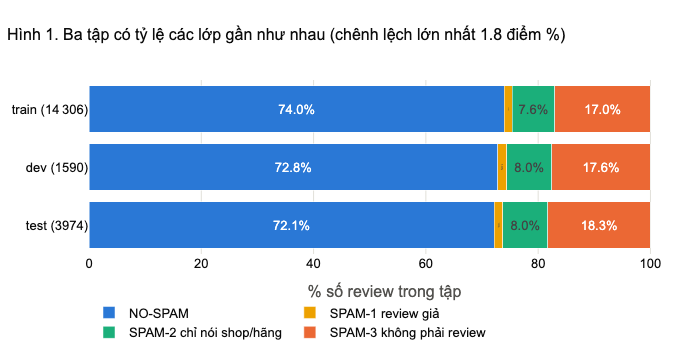

In [13]:
split_counts = pd.crosstab(df["split"], df["type_name"]).loc[list(SPLIT_FILES)]   # thứ tự train, dev, test
split_share = split_counts.div(split_counts.sum(axis=1), axis=0) * 100

fig = go.Figure()
for type_name in split_share.columns:
    fig.add_trace(go.Bar(
        y=[f"{s} ({format_number(split_counts.loc[s].sum())})" for s in split_share.index], x=split_share[type_name],
        name=type_name, orientation="h", marker_color=TYPE_COLORS[type_name],
        customdata=split_counts[type_name],
        text=[f"{v:.1f}%" for v in split_share[type_name]], textposition="inside", insidetextanchor="middle",
        hovertemplate="%{y}<br>" + type_name + ": %{customdata} review (%{x:.1f}%)<extra></extra>",
    ))
max_gap = (split_share.max() - split_share.min()).max()
show_fig(fig, f"Ba tập có tỷ lệ các lớp gần như nhau (chênh lệch lớn nhất {max_gap:.1f} điểm %)",
         barmode="stack", height=360, xaxis_title="% số review trong tập", yaxis_autorange="reversed",
         legend=BOTTOM_LEGEND)

**Nhận xét.** Tỷ lệ các lớp gần như giống nhau ở train, dev và test (chênh lệch lớn nhất 1.8 điểm %, của NO-SPAM giữa train và test). Cách chia của tác giả đại diện tốt cho dữ liệu, nên có thể dùng tập dev để chọn mô hình mà không sợ kết quả trên test khác biệt bất ngờ.

### 4.4 Trùng lặp, nhãn mâu thuẫn và rò rỉ giữa các tập

Review được so sánh sau khi bỏ khác biệt hoa thường và khoảng trắng, nên "Ok" và "ok " là cùng một nội dung. Ba câu hỏi:
1. Bao nhiêu review bị lặp lại?
2. Cùng một nội dung có bị gán **nhãn khác nhau** không? Đó là nhiễu nhãn mà không mô hình nào sửa được.
3. Cùng một nội dung có nằm ở **hai tập khác nhau** không? Khi đó mô hình được kiểm tra trên câu nó đã thấy lúc học (rò rỉ dữ liệu).

In [14]:
df["dup_key"] = df[TEXT_COL].str.lower().str.split().str.join(" ")   # chữ thường + gộp mọi khoảng trắng

labels_per_text = df.groupby("dup_key")[TYPE_COL].nunique()
splits_per_text = df.groupby("dup_key")["split"].nunique()
train_labels_per_text = df[df["split"] == "train"].groupby("dup_key")[TYPE_COL].nunique()

duplicates = pd.DataFrame({
    "kiểm tra": ["dòng trùng hoàn toàn trong cùng một tập (giống cả số sao, nội dung, hai nhãn)",
                 "nội dung lặp lại, so nguyên văn",
                 "nội dung lặp lại, sau khi bỏ hoa thường và khoảng trắng",
                 "nội dung bị gán nhãn mâu thuẫn (xét cả ba tập)",
                 "nội dung bị gán nhãn mâu thuẫn (chỉ xét trong tập train)",
                 "nội dung xuất hiện ở nhiều hơn một tập"],
    "số lượng": [int(df.duplicated(subset=[RATING_COL, TEXT_COL, LABEL_COL, TYPE_COL, "split"]).sum()),
                 int(df[TEXT_COL].duplicated().sum()),
                 int(df["dup_key"].duplicated().sum()),
                 int((labels_per_text > 1).sum()),
                 int((train_labels_per_text > 1).sum()),
                 int((splits_per_text > 1).sum())],
})
show_table(duplicates, "Tổng hợp trùng lặp", hide_index=True)

conflict_keys = labels_per_text[labels_per_text > 1].index
conflicts = (df.loc[df["dup_key"].isin(conflict_keys), ["dup_key", "type_name", "split"]]
               .sort_values(["dup_key", "split"]).set_axis(["nội dung", "nhãn", "tập"], axis=1))
show_table(conflicts, "Các review có cùng nội dung nhưng bị gán nhãn khác nhau", hide_index=True)

in_train = set(df.loc[df["split"] == "train", "dup_key"])
test_copied = df.loc[(df["split"] == "test") & df["dup_key"].isin(in_train)]
print(f"Review trong test có bản sao y hệt trong train: {len(test_copied)} "
      f"({len(test_copied) / (df['split'] == 'test').sum():.1%} tập test)")

kiểm tra,số lượng
"dòng trùng hoàn toàn trong cùng một tập (giống cả số sao, nội dung, hai nhãn)",0
"nội dung lặp lại, so nguyên văn",18
"nội dung lặp lại, sau khi bỏ hoa thường và khoảng trắng",121
nội dung bị gán nhãn mâu thuẫn (xét cả ba tập),7
nội dung bị gán nhãn mâu thuẫn (chỉ xét trong tập train),5
nội dung xuất hiện ở nhiều hơn một tập,52


nội dung,nhãn,tập
cực kỳ hài lòng,NO-SPAM,test
cực kỳ hài lòng,NO-SPAM,train
cực kỳ hài lòng,SPAM-3 không phải review,train
giá tốt,SPAM-2 chỉ nói shop/hãng,test
giá tốt,SPAM-3 không phải review,train
hài lòng,SPAM-3 không phải review,test
hài lòng,SPAM-3 không phải review,train
hài lòng,SPAM-2 chỉ nói shop/hãng,train
hài lòng,SPAM-3 không phải review,train
rất hài lòng,SPAM-3 không phải review,test


Review trong test có bản sao y hệt trong train: 41 (1.0% tập test)


**Nhận xét.**
- **Không có dòng nào trùng hoàn toàn** trong cùng một tập. Có **121 nội dung lặp lại** (0.6%) sau khi bỏ hoa thường. Gần như tất cả là review rất ngắn, chung chung ("ok", "tốt", "hài lòng").
- **7 nội dung bị gán nhãn mâu thuẫn** khi xét cả ba tập, đều là lời khen ngắn như "hài lòng", "rất hài lòng": nơi thì gán NO-SPAM, nơi thì SPAM-3. Nếu chỉ xét tập train thì còn **5 nội dung** (11 review).
- **41 review của tập test (1.0%) có bản sao y hệt trong train.**

**Quyết định.**
- Giữ nguyên cách chia của tác giả để kết quả so sánh được với bài báo; phần rò rỉ quá nhỏ để thay đổi kết luận và sẽ được ghi rõ trong báo cáo.
- Khi chuẩn bị dữ liệu, loại khỏi tập train **5 nội dung mâu thuẫn tìm được trong chính tập train**. Không dùng các mâu thuẫn giữa train và dev/test để sửa train, vì như vậy là dùng nhãn của dev/test (rò rỉ).

### 4.5 Chuẩn hóa văn bản và tách từ

Từ mỗi review gốc, notebook tạo ra **hai bản** dùng cho hai mục đích khác nhau:

| Cột | Hàm tạo ra | Đơn vị | Dùng ở |
|---|---|---|---|
| `clean` | `normalize_text` | tiếng, cách nhau một khoảng trắng | đếm độ dài, chính tả, viết tắt, chủ đề, văn mẫu (4.6 đến 5.7, 5.10) |
| `words` | `segment_words` | từ, các tiếng của một từ nối bằng `_` | bộ từ vựng và từ đặc trưng (5.8, 5.9) |

Hai hàm dùng chung **bước 1 đến 3**, chỉ khác nhau ở chỗ tách từ:

| Bước | Làm gì | Vì sao |
|---|---|---|
| 1 | Đưa Unicode về dạng **NFC** | Một chữ có dấu như "ế" có thể được lưu bằng 1 mã Unicode (dạng dựng sẵn, NFC) hoặc 3 mã (e + dấu mũ + dấu sắc, dạng tổ hợp NFD). Hai cách hiển thị giống hệt nhưng máy tính xem là hai chuỗi khác nhau, nên cùng một tiếng sẽ bị đếm thành hai. Bảng ngay dưới cho ví dụ. **Chọn NFC chứ không chọn NFD** vì: 98.5% review của train vốn đã ở dạng NFC (4.6.1); mỗi chữ có dấu là 1 ký tự nên đếm ký tự đúng như mắt thấy; và ở dạng NFD, dấu thanh là ký tự riêng không thuộc `\w`, nên bước 4 sẽ xóa mất dấu ("tiếng" thành "tie ng") |
| 2 | Chuyển về **chữ thường** | Để "Tốt" và "tốt" là một tiếng |
| 3 | Thay mỗi đường link bằng tiếng `urltoken` | Nếu chỉ bỏ dấu câu, một link như `https://shopee.vn/abc` vỡ thành nhiều tiếng vô nghĩa ("https", "shopee", "vn", "abc") làm bẩn bộ từ vựng. Thay bằng một tiếng chung giữ lại thông tin "review này có link" (một dấu hiệu của spam, xem 5.6) |
| 4 | Thay dấu câu, emoji, ký hiệu bằng khoảng trắng | Tiếng được đếm bằng cách cắt theo khoảng trắng. Nếu để nguyên, "nhanh,sáng" thành **một** tiếng và "đẹp", "đẹp." và "đẹp!!!" thành **ba** tiếng khác nhau. Ký hiệu `\w` giữ lại mọi chữ cái có dấu |
| 5 | Gộp các khoảng trắng liên tiếp | Để mỗi tiếng cách nhau đúng một khoảng trắng |

**`segment_words` chạy công cụ tách từ sau bước 3, khi văn bản còn dấu câu,** rồi mới bỏ dấu câu trên từng từ. Lý do: dấu câu cho công cụ biết chỗ ngắt. Ở review "Sản phẩm giá rẻ, shop đóng gói ...", nếu bỏ dấu phẩy trước thì công cụ ghép sai thành "rẻ_shop". Bảng thứ hai bên dưới so hai cách; hai cột trông gần giống nhau nên cột cuối chỉ ra đúng chỗ khác.

In [15]:
demo_word = "tiếng"
nfc_form, nfd_form = unicodedata.normalize("NFC", demo_word), unicodedata.normalize("NFD", demo_word)
show_table(pd.DataFrame({"dạng": ["NFC (dựng sẵn)", "NFD (tổ hợp)"], "hiển thị": [nfc_form, nfd_form],
                         "số mã Unicode": [len(nfc_form), len(nfd_form)]}),
           f'Bước 1: cùng chữ "{demo_word}" nhưng là hai chuỗi khác nhau với máy tính '
           f'(so sánh bằng nhau: {nfc_form == nfd_form})', hide_index=True)

dạng,hiển thị,số mã Unicode
NFC (dựng sẵn),tiếng,5
NFD (tổ hợp),tiếng,7


In [16]:
URL_RE = re.compile(r"https?://\S+|www\.\S+")
PUNCTUATION_RE = re.compile(r"[^\w\s]")      # mọi thứ không phải chữ, số, dấu gạch dưới hay khoảng trắng
SPACES_RE = re.compile(r"\s+")


def prepare_text(text):
    """Bước 1 đến 3, dùng chung cho hai hàm bên dưới."""
    text = unicodedata.normalize("NFC", str(text))   # bước 1
    text = text.lower()                              # bước 2
    return URL_RE.sub(" urltoken ", text)            # bước 3


def normalize_text(text):
    """Bản sạch của review: các tiếng cách nhau một khoảng trắng (cột clean)."""
    text = PUNCTUATION_RE.sub(" ", prepare_text(text))   # bước 4
    return SPACES_RE.sub(" ", text).strip()              # bước 5


def segment_words(text):
    """Bản đã tách từ của review: các tiếng của một từ nối bằng "_" (cột words)."""
    words = word_tokenize(prepare_text(text))                          # tách từ khi còn dấu câu
    words = [PUNCTUATION_RE.sub(" ", word).strip() for word in words]  # bước 4 trên từng từ
    return " ".join(word.replace(" ", "_") for word in words if word)


df["clean"] = df[TEXT_COL].map(normalize_text)
df["words"] = df[TEXT_COL].map(segment_words)
df["n_syllables"] = df["clean"].str.split().str.len()            # số tiếng
df["n_words"] = df["words"].str.split().str.len()                # số từ
df["n_chars"] = df[TEXT_COL].str.normalize("NFC").str.len()      # số ký tự

step_demo = [
    "Vô https://shopee.vn/kinhmat_legoo?smtt=0.0.9 mua kính đẹp nha các cậu ❤️",
    "Giao hàng nhanh,sáng đặt chiều giao,đóng gói kĩ,sản phẩm như hình.",
    "Sản phẩm giá rẻ, shop đóng gói và giao hàng nhanh. Cảm ơn shop.",
]
show_table(pd.DataFrame({
    "review gốc (tập train)": step_demo,
    "chỉ bỏ dấu câu (không có bước 3)": [SPACES_RE.sub(" ", PUNCTUATION_RE.sub(" ", t.lower())).strip() for t in step_demo],
    "chỉ cắt theo khoảng trắng (không có bước 4)": [" | ".join(t.lower().split()) for t in step_demo],
    "clean": [normalize_text(t) for t in step_demo],
}), "Bước 3 và 4 thay đổi gì (dấu | ngăn cách các tiếng ở cột thứ ba)",
    text_columns=["review gốc (tập train)", "chỉ bỏ dấu câu (không có bước 3)",
                  "chỉ cắt theo khoảng trắng (không có bước 4)", "clean"], hide_index=True)
segmented_first = [segment_words(t) for t in step_demo]
cleaned_first = [word_tokenize(normalize_text(t), format="text") for t in step_demo]
show_table(pd.DataFrame({
    "review gốc (tập train)": step_demo,
    "words: tách từ khi còn dấu câu": segmented_first,
    "tách từ sau khi đã bỏ dấu câu": cleaned_first,
    "từ bị ghép sai khi bỏ dấu câu trước": [", ".join(w for w in after.split() if w not in before.split()) or "(giống nhau)"
                                           for before, after in zip(segmented_first, cleaned_first)],
}), "Vì sao tách từ trước khi bỏ dấu câu", text_columns=["review gốc (tập train)",
    "words: tách từ khi còn dấu câu", "tách từ sau khi đã bỏ dấu câu"], hide_index=True)

review gốc (tập train),chỉ bỏ dấu câu (không có bước 3),chỉ cắt theo khoảng trắng (không có bước 4),clean
Vô https://shopee.vn/kinhmat_legoo?smtt=0.0.9 mua kính đẹp nha các cậu ❤️,vô https shopee vn kinhmat_legoo smtt 0 0 9 mua kính đẹp nha các cậu,vô | https://shopee.vn/kinhmat_legoo?smtt=0.0.9 | mua | kính | đẹp | nha | các | cậu | ❤️,vô urltoken mua kính đẹp nha các cậu
"Giao hàng nhanh,sáng đặt chiều giao,đóng gói kĩ,sản phẩm như hình.",giao hàng nhanh sáng đặt chiều giao đóng gói kĩ sản phẩm như hình,"giao | hàng | nhanh,sáng | đặt | chiều | giao,đóng | gói | kĩ,sản | phẩm | như | hình.",giao hàng nhanh sáng đặt chiều giao đóng gói kĩ sản phẩm như hình
"Sản phẩm giá rẻ, shop đóng gói và giao hàng nhanh. Cảm ơn shop.",sản phẩm giá rẻ shop đóng gói và giao hàng nhanh cảm ơn shop,"sản | phẩm | giá | rẻ, | shop | đóng | gói | và | giao | hàng | nhanh. | cảm | ơn | shop.",sản phẩm giá rẻ shop đóng gói và giao hàng nhanh cảm ơn shop


review gốc (tập train),words: tách từ khi còn dấu câu,tách từ sau khi đã bỏ dấu câu,từ bị ghép sai khi bỏ dấu câu trước
Vô https://shopee.vn/kinhmat_legoo?smtt=0.0.9 mua kính đẹp nha các cậu ❤️,vô urltoken mua kính đẹp_nha các cậu,vô urltoken mua kính đẹp_nha các cậu,(giống nhau)
"Giao hàng nhanh,sáng đặt chiều giao,đóng gói kĩ,sản phẩm như hình.",giao hàng nhanh sáng đặt chiều giao đóng_gói kĩ sản_phẩm như hình,giao hàng nhanh sáng đặt chiều giao đóng_gói kĩ_sản_phẩm như hình,kĩ_sản_phẩm
"Sản phẩm giá rẻ, shop đóng gói và giao hàng nhanh. Cảm ơn shop.",sản_phẩm giá rẻ shop đóng_gói và giao hàng nhanh cảm_ơn shop,sản_phẩm giá rẻ_shop đóng_gói và giao hàng nhanh cảm_ơn shop,rẻ_shop


**Từ đây trở đi chỉ dùng tập train** (lý do ở mục 2.2).

In [17]:
train = df.loc[df["split"] == "train"].copy()
print(f"Tập train: {format_number(len(train))} review, {format_number(train['n_syllables'].sum())} tiếng, {format_number(train['n_words'].sum())} từ")

Tập train: 14 306 review, 370 688 tiếng, 315 390 từ


**Review rỗng sau chuẩn hóa.** Bước 4 thay emoji và ký hiệu bằng khoảng trắng, nên review chỉ gồm emoji hoặc ký hiệu sẽ **trở thành rỗng**. Bước 1 đến 3 không làm review nào rỗng (kiểm tra ở dòng in đầu tiên bên dưới).

In [18]:
print("Số review rỗng sau bước 1 đến 3:", train[TEXT_COL].map(prepare_text).str.strip().eq("").sum())
train["is_empty_after_cleaning"] = train["clean"].eq("")
empty_reviews = train.loc[train["is_empty_after_cleaning"]]
print(f"Số review rỗng sau bước 4 (cũng là sau chuẩn hóa): {len(empty_reviews)}")
show_table(empty_reviews["type_name"].value_counts().rename("số review").rename_axis("nhãn"),
           "Nhãn của các review rỗng sau chuẩn hóa")
show_table(empty_reviews[[TEXT_COL]].head(5).rename(columns={TEXT_COL: "review gốc"}),
           "Ví dụ review rỗng sau chuẩn hóa (chỉ có emoji hoặc ký hiệu)", text_columns=["review gốc"], hide_index=True)

Số review rỗng sau bước 1 đến 3: 0
Số review rỗng sau bước 4 (cũng là sau chuẩn hóa): 50


,số review
nhãn,
SPAM-3 không phải review,50


review gốc
🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰🥰✌️✌️🎁🎁♥️✈️👸💐🎂♥️🎁✌️✌️🎂😜✈️☕⛱️💐⛱️👸☕🍨💋✈️⛱️💐☕☕✈️🤣🌹😘🎂🤣😁😜
@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@ @@@@@
❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️
....................................... ....................................... ....................................... .......................................
😄😀😄😀😊🙂😊🙂😊🙂😊🙃😇🙃😚🙃😚😗😚😚😗😇😗🥰😗🤭😗🤭🥰☺🤭😉😏😍😘😛😗😏🤭😗🤗😗🤭🤫😗🥰😝🤭😗🤭😗😙😝😙🤭☺🤫☺🤫


**Nhận xét.** Cả **50 review rỗng sau chuẩn hóa đều là SPAM-3**: chúng chỉ gồm emoji, dấu chấm hoặc ký hiệu lặp lại. Đây là một tín hiệu spam rất rõ, nhưng bước chuẩn hóa lại xóa mất nó. **Quyết định:** khi xây dựng mô hình phải giữ lại thông tin này, ví dụ thêm một cột "rỗng sau chuẩn hóa" hoặc dùng n-gram ký tự trên văn bản gốc.

### 4.6 Chính tả và cách viết

Review viết trên điện thoại thường gặp các vấn đề dưới đây. Tất cả đều làm **cùng một tiếng bị đếm thành nhiều tiếng khác nhau**. Mỗi mục đo xem vấn đề lớn đến đâu, rồi bảng cuối mục (4.6.4) ghi quyết định xử lý hay bỏ qua.

| Vấn đề | Ví dụ | Kiểm tra ở |
|---|---|---|
| Hai cách lưu Unicode | "ế" lưu thành 1 mã (NFC) hoặc 3 mã (NFD), xem bảng ở 4.5 | 4.6.1 |
| Chữ kiểu "font đặc biệt" | "𝐓𝐈𝐄̂́𝐓 𝐂𝐀𝐍𝐇 𝐂𝐔̉ 𝐃𝐄̂̀𝐍" (đầu một review SPAM-3 của tập train) trông như chữ in hoa nhưng là ký tự toán học khác hẳn | 4.6.1 |
| Viết tắt, teencode | "ko, k" (không), "đc" (được), "sp" (sản phẩm), "mn" (mọi người) | 4.6.2 |
| Viết không dấu | "san pham dep" | 4.6.3 |

#### 4.6.1 Dạng Unicode và chữ kiểu font đặc biệt

In [19]:
train["is_not_nfc"] = train[TEXT_COL] != train[TEXT_COL].str.normalize("NFC")
print(f"Review không ở dạng NFC: {train['is_not_nfc'].sum()} ({train['is_not_nfc'].mean():.1%}). Bước 1 của 4.5 đã xử lý.")

# Chữ "font đặc biệt" là các ký tự chữ cái toán học (khối Unicode U+1D400 đến U+1D7FF), hay gặp trong tin quảng cáo.
# Dạng chuẩn hóa NFKC đổi chúng về chữ thường, NFC thì không.
FANCY_FONT_PATTERN = "[\U0001D400-\U0001D7FF]"
train["has_fancy_font"] = train[TEXT_COL].str.contains(FANCY_FONT_PATTERN)
fancy_example = "𝐓𝐈𝐄̂́𝐓 𝐂𝐀𝐍𝐇 𝐂𝐔̉ 𝐃𝐄̂̀𝐍"      # lấy từ một review SPAM-3 của tập train
print("Ví dụ có trong tập train:", train[TEXT_COL].str.contains(fancy_example, regex=False).any())
print(f'Ví dụ: "{fancy_example}" -> NFC: "{unicodedata.normalize("NFC", fancy_example)}" | '
      f'NFKC: "{unicodedata.normalize("NFKC", fancy_example)}"')
show_table(train.loc[train["has_fancy_font"], "type_name"].value_counts().rename("số review").rename_axis("nhãn"),
           f"{train['has_fancy_font'].sum()} review dùng chữ kiểu font đặc biệt, theo nhãn")

Review không ở dạng NFC: 214 (1.5%). Bước 1 của 4.5 đã xử lý.
Ví dụ có trong tập train: True
Ví dụ: "𝐓𝐈𝐄̂́𝐓 𝐂𝐀𝐍𝐇 𝐂𝐔̉ 𝐃𝐄̂̀𝐍" -> NFC: "𝐓𝐈𝐄̂́𝐓 𝐂𝐀𝐍𝐇 𝐂𝐔̉ 𝐃𝐄̂̀𝐍" | NFKC: "TIẾT CANH CỦ DỀN"


,số review
nhãn,
SPAM-3 không phải review,12
SPAM-1 review giả,1


#### 4.6.2 Viết tắt và teencode

**Danh sách viết tắt dưới đây do nhóm tự lập**, gồm các cách viết tắt phổ biến trong bình luận mua hàng, sau đó kiểm tra lại trên dữ liệu (biểu đồ bên trái cho biết mỗi mục xuất hiện trong bao nhiêu review). Đây không phải từ điển chuẩn nên có thể thiếu một số cách viết. Một review được tính là "có viết tắt" nếu chứa ít nhất một tiếng trong danh sách. So khớp theo **nguyên tiếng**, nên chữ "k" trong "kem" không bị tính. Các tiếng quá mơ hồ như "r" hay "ng" không được đưa vào danh sách.

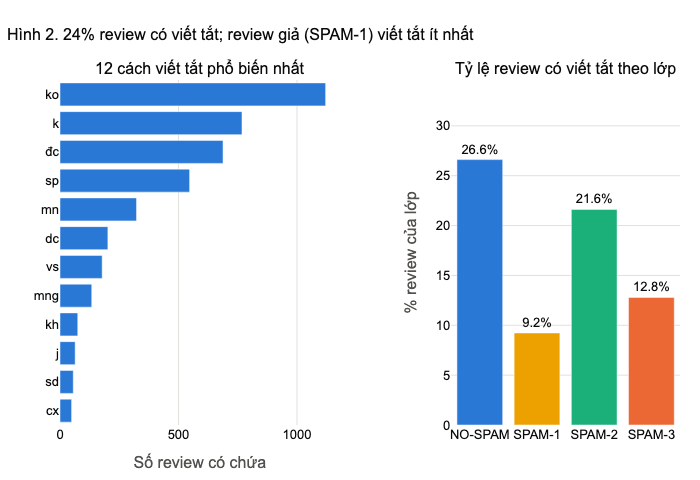

Các mục trong danh sách không xuất hiện lần nào: []


In [20]:
ABBREVIATIONS = {
    "ko": "không", "k": "không", "kh": "không", "khg": "không", "kg": "không", "hok": "không", "hk": "không",
    "đc": "được", "dc": "được", "đk": "được", "dk": "được",
    "sp": "sản phẩm", "sd": "sử dụng", "mn": "mọi người", "mng": "mọi người",
    "vs": "với", "cx": "cũng", "cg": "cũng", "j": "gì", "z": "vậy", "iu": "yêu",
    "thik": "thích", "bik": "biết", "nt": "nhắn tin", "ib": "nhắn tin",
}
ABBREVIATION_PATTERN = r"\b(?:" + "|".join(ABBREVIATIONS) + r")\b"     # khớp nguyên tiếng

train["has_abbreviation"] = train["clean"].str.contains(ABBREVIATION_PATTERN)
abbr_review_counts = pd.Series({abbr: train["clean"].str.contains(rf"\b{abbr}\b").sum() for abbr in ABBREVIATIONS})
abbr_rate = train.groupby("type_name")["has_abbreviation"].agg(["sum", "count", "mean"])

top_abbr = abbr_review_counts.nlargest(12).iloc[::-1]
fig = make_subplots(rows=1, cols=2, column_widths=[0.55, 0.45], horizontal_spacing=0.18,
                    subplot_titles=("12 cách viết tắt phổ biến nhất", "Tỷ lệ review có viết tắt theo lớp"))
fig.add_trace(go.Bar(
    x=top_abbr.values, y=top_abbr.index, orientation="h", marker_color=BLUE,
    customdata=np.stack([[ABBREVIATIONS[a] for a in top_abbr.index], top_abbr.values / len(train) * 100], axis=-1),
    hovertemplate='"%{y}" = %{customdata[0]}<br>có trong %{x} review (%{customdata[1]:.1f}% tập train)<extra></extra>'),
    row=1, col=1)
fig.add_trace(go.Bar(
    x=[name.split(" ")[0] for name in abbr_rate.index], y=abbr_rate["mean"] * 100,
    marker_color=[TYPE_COLORS[t] for t in abbr_rate.index],
    customdata=np.stack([abbr_rate.index, abbr_rate["sum"], abbr_rate["count"]], axis=-1),
    text=[f"{v:.1%}" for v in abbr_rate["mean"]], textposition="outside",
    hovertemplate="%{customdata[0]}<br>%{customdata[1]} / %{customdata[2]} review (%{y:.1f}%)<extra></extra>"),
    row=1, col=2)
fig.update_xaxes(title_text="Số review có chứa", row=1, col=1)
fig.update_yaxes(title_text="% review của lớp", range=[0, abbr_rate["mean"].max() * 130], row=1, col=2)
show_fig(fig, f"{train['has_abbreviation'].mean():.0%} review có viết tắt; review giả (SPAM-1) viết tắt ít nhất",
         height=480, showlegend=False)
print("Các mục trong danh sách không xuất hiện lần nào:", list(abbr_review_counts[abbr_review_counts == 0].index))

**Nhận xét.**
- **24% review có ít nhất một từ viết tắt.** Phổ biến nhất là "ko", "k" (không), "đc" (được), "sp" (sản phẩm), "mn" (mọi người).
- Review thường (26.6%) và SPAM-2 (21.6%) viết tắt nhiều nhất, vì đó là văn nói tự nhiên của người mua. **Review giả (SPAM-1) viết tắt ít nhất (9.2%)**, phù hợp với giả thuyết chúng là văn mẫu viết sẵn, câu cú "chuẩn" hơn (kiểm tra ở 5.10).
- Công cụ tách từ giữ nguyên các viết tắt này (mục 3.1), nên "ko" và "không" vẫn là hai từ khác nhau.

**Quyết định.** Viết tắt vừa là nhiễu ("ko" và "không" cùng nghĩa) vừa là tín hiệu (ít viết tắt gợi ý văn mẫu). Khi xây dựng mô hình có thể thử cả hai cách: giữ nguyên, hoặc thay bằng từ đầy đủ.

#### 4.6.3 Review không có dấu: tiếng Việt gõ không dấu hay thứ khác?

Một review **không chứa chữ cái có dấu nào** (à, á, ..., đ) có thể là tiếng Việt gõ không dấu ("san pham dep"), nhưng cũng có thể là chuỗi gõ bừa, tiếng Anh hay mã số. Để tách các trường hợp này mà không phải tự chọn từ khóa, ta lấy **bộ tiếng quen thuộc từ chính dữ liệu**:

1. Lấy mọi tiếng (chỉ gồm chữ cái, không có chữ số) xuất hiện ít nhất 20 lần trong các review **có dấu** của tập train, rồi bỏ dấu đi ("được" thành "duoc", "hàng" thành "hang").
2. Một review không dấu được xếp vào nhóm **tiếng Việt không dấu** nếu ít nhất một nửa số tiếng của nó thuộc bộ này; nhóm **rỗng sau chuẩn hóa** nếu không còn tiếng nào (đã thấy ở 4.5); còn lại là nhóm **khác** (gõ bừa, tiếng Anh, mã số).

Hai ngưỡng (ít nhất 20 lần, ít nhất một nửa số tiếng) **do nhóm tự đặt** sau khi đọc thử kết quả, không lấy từ tài liệu nào.

Bộ tiếng này cũng chứa các từ mượn hay dùng trong review như "ok", "shop", "size", nên một review chỉ có "ok" vẫn được xếp là tiếng Việt.

In [21]:
def remove_diacritics(text):
    """Bỏ mọi dấu: "được" -> "duoc"."""
    text = unicodedata.normalize("NFD", text.replace("đ", "d"))
    return "".join(ch for ch in text if not unicodedata.combining(ch))


train["no_diacritics"] = ~train["clean"].str.contains(f"[{VIETNAMESE_LETTERS}]")

syllables_with_diacritics = Counter(s for text in train.loc[~train["no_diacritics"], "clean"] for s in text.split())
KNOWN_SYLLABLES = {remove_diacritics(s) for s, n in syllables_with_diacritics.items() if n >= 20 and s.isalpha()}
print(f"Bộ tiếng quen thuộc (bỏ dấu): {len(KNOWN_SYLLABLES)} tiếng. 15 tiếng phổ biến nhất:",
      ", ".join(remove_diacritics(s) for s, _ in syllables_with_diacritics.most_common(15)))


def no_diacritic_group(clean_text):
    syllables = clean_text.split()
    if not syllables:
        return "rỗng sau chuẩn hóa"
    if sum(s in KNOWN_SYLLABLES for s in syllables) >= len(syllables) / 2:
        return "tiếng Việt không dấu"
    return "khác (gõ bừa, tiếng Anh, mã số)"


no_diacritic = train.loc[train["no_diacritics"]].copy()
no_diacritic["nhóm"] = no_diacritic["clean"].map(no_diacritic_group)
show_table(pd.crosstab(no_diacritic["nhóm"], no_diacritic["type_name"].rename("nhãn"), margins=True, margins_name="tổng"),
           f"{len(no_diacritic)} review không có chữ có dấu, chia theo nhóm (dòng) và nhãn (cột)")

# Tối đa 2 ví dụ cho mỗi ô (nhóm, nhãn) của bảng trên
cell_examples = (no_diacritic.sample(frac=1, random_state=SEED).groupby(["nhóm", "type_name"]).head(2)
                 .sort_values(["nhóm", "type_name"]))
cell_examples["nội dung review"] = cell_examples[TEXT_COL].str[:200]
show_table(cell_examples[["nhóm", "type_name", "nội dung review"]].rename(columns={"type_name": "nhãn"}),
           "Ví dụ cho mỗi ô của bảng (tối đa 2 review, cắt ở 200 ký tự)", text_columns=["nội dung review"], hide_index=True)

Bộ tiếng quen thuộc (bỏ dấu): 815 tiếng. 15 tiếng phổ biến nhất: hang, giao, rat, nhanh, minh, mua, co, shop, san, pham, chat, nen, gia, dep, va


nhãn,NO-SPAM,SPAM-1 review giả,SPAM-2 chỉ nói shop/hãng,SPAM-3 không phải review,tổng
nhóm,,,,,
"khác (gõ bừa, tiếng Anh, mã số)",3,1,0,378,382
rỗng sau chuẩn hóa,0,0,0,50,50
tiếng Việt không dấu,89,1,18,138,246
tổng,92,2,18,566,678


nhóm,nhãn,nội dung review
"khác (gõ bừa, tiếng Anh, mã số)",NO-SPAM,The Price is good. I am satisfied. If only they have a refill package. I transfer this shampoo into a small container. Dont need a big bottle like this.
"khác (gõ bừa, tiếng Anh, mã số)",NO-SPAM,"Good products, good quality and good price"
"khác (gõ bừa, tiếng Anh, mã số)",SPAM-1 review giả,𝘾𝙝𝙖̂𝙩 𝙡𝙪̛𝙤̛𝙣𝙜 𝙨𝙖𝙣 𝙥𝙝𝙖̂̉𝙢 𝙩𝙪𝙮𝙚̂𝙩 𝙫𝙤̛𝙞 𝙜𝙞𝙖́ 𝙘𝙖̉ 𝙝𝙤̛𝙥 𝙡𝙮́ 𝙨𝙝𝙤𝙥 𝙙̶𝙤𝙣𝙜 𝙜𝙤𝙞 𝙨𝙖𝙣 𝙥𝙝𝙖̂𝙢 𝙘𝙝𝙖̆𝙘 𝙘𝙝𝙖̆𝙣 𝙜𝙞𝙖𝙤 𝙝𝙖𝙣𝙜 𝙙̶𝙪́𝙣𝙜 𝙢𝙖̂𝙪 𝙙̶𝙖́𝙣𝙝 𝙜𝙞𝙖́ 𝙨𝙝𝙤𝙥 5 𝙨𝙖𝙤
"khác (gõ bừa, tiếng Anh, mã số)",SPAM-3 không phải review,kvjvvkvb
"khác (gõ bừa, tiếng Anh, mã số)",SPAM-3 không phải review,#ERROR!
rỗng sau chuẩn hóa,SPAM-3 không phải review,✌🤟😭🍆🛀🏼🥔😭🛀🏼🦁🥔🛀🏼😭🍆🖕🍆😘🖕🍆😘🖕🤟🖕🍆🤟😭🍆😘😭👌😘😭🥔😭🔔🥔😘😭🥔🛀🏼👌😘🛀🏼😘👌🖕😭🍆🛀🏼🥔😭🛀🏼😭🥔🛀🏼😭🥔🛀🏼😭🥔
rỗng sau chuẩn hóa,SPAM-3 không phải review,...................................................
tiếng Việt không dấu,NO-SPAM,"Tot, xai rat okie. Moi nguoi yen tam ve chat luong may nhe."
tiếng Việt không dấu,NO-SPAM,ok dien thoai su dung ngon
tiếng Việt không dấu,SPAM-1 review giả,"Chat luong san pham tuyet voi, giao hang trong ngay, dich vu tot"


**Nhận xét.** Trong 678 review không có chữ có dấu:
- **382 review thuộc nhóm "khác"** (gõ bừa, tiếng Anh, mã số), và 378 trong số đó là SPAM-3. Ba review thường trong nhóm này đều viết bằng tiếng Anh ("Good products, good quality and good price"). Review SPAM-1 duy nhất ở đây viết bằng chữ kiểu font đặc biệt (4.6.1): chữ có dấu nhưng không phải chữ cái thường nên không được nhận ra.
- **50 review rỗng sau chuẩn hóa**, tất cả là SPAM-3 (đã thấy ở 4.5).
- **246 review là tiếng Việt gõ không dấu**, gồm cả review thường (89), SPAM-2 (18) lẫn SPAM-3 (138). SPAM-3 ở nhóm này gồm tin nhắn quảng cáo của nhà mạng viết không dấu, review rất ngắn như "ok" và một số chuỗi lặp như "ok okokoko" mà quy tắc xếp nhầm: quy tắc chỉ là ước lượng.

Vậy **viết không dấu tự nó không phải là spam**; điều đáng chú ý là nhóm "khác" gần như toàn là SPAM-3. Công cụ tách từ cũng chỉ tách được một phần văn bản không dấu (mục 3.1). Khi xây dựng mô hình, n-gram ký tự sẽ phân biệt được chuỗi gõ bừa (tổ hợp ký tự lạ) với tiếng Việt không dấu (vẫn có các tổ hợp quen thuộc như "ng", "anh").

#### 4.6.4 Quyết định: xử lý hay bỏ qua?

"Xử lý" nghĩa là thêm một bước vào `normalize_text` để sửa văn bản. "Bỏ qua" nghĩa là **không sửa văn bản**. Các cột cờ như `has_fancy_font`, `has_abbreviation`, `no_diacritics` không làm thay đổi văn bản: chúng chỉ dùng để thống kê ở 5.6, và nếu tách được các lớp thì sẽ được thử làm đặc trưng phụ khi xây dựng mô hình (6.2 ghi cột nào được dùng và vì sao bỏ các cột còn lại).

| Vấn đề | Số review (train) | Quyết định | Lý do |
|---|---|---|---|
| Không ở dạng NFC (4.6.1) | 214 (1.5%) | **Xử lý:** bước 1 của `normalize_text` | Nếu không sửa, cùng một tiếng thành hai token khác nhau. Sửa không làm mất thông tin gì |
| Chữ kiểu font đặc biệt (4.6.1) | 13 (0.1%) | **Bỏ qua:** không dùng NFKC | Quá ít để ảnh hưởng bộ từ vựng. 12 trong 13 review là SPAM-3, nên chữ lạ còn là dấu hiệu spam |
| Viết tắt, teencode (4.6.2) | 3382 (23.6%) | **Bỏ qua** khi làm sạch; ở bước mô hình thử thêm phương án thay bằng từ đầy đủ rồi so sánh bằng kiểm định chéo (7.4) | Danh sách tự lập nên có thể thiếu hoặc thay sai; ít viết tắt lại là dấu hiệu của SPAM-1 (Hình 2) |
| Không có chữ có dấu (4.6.3) | 678 (4.7%) | **Bỏ qua:** không tự thêm dấu | Không có cách thêm dấu vừa đơn giản vừa đủ tin cậy; nhóm "khác" gần như toàn SPAM-3 nên đây là dấu hiệu cần giữ |

### 4.7 Các dấu hiệu văn bản tự định nghĩa

**Để làm gì?** Mô hình theo từ (TF-IDF ở bước sau) chỉ nhìn thấy văn bản **sau** chuẩn hóa, mà bước chuẩn hóa xóa mất emoji, link, ký tự xuống dòng và mọi dấu câu. Các dấu hiệu dưới đây đo đúng những thứ bị xóa hoặc không thấy được qua từ vựng (độ dài, chữ lặp, không dấu). Phần 5.6 so sánh tỷ lệ của chúng giữa các lớp để quyết định:
- dấu hiệu nào nên được giữ lại thành **đặc trưng phụ** bên cạnh TF-IDF;
- thông tin nào **không được xóa** khi làm sạch.

Các dấu hiệu và ngưỡng của chúng (tối đa 3 tiếng, lặp chữ từ 4 và từ 10 lần) **do nhóm tự đặt** từ những gì thấy được ở 4.5 và 4.6, nên chỉ là một cách đo, không phải định nghĩa chuẩn. Bảng dưới định nghĩa từng dấu hiệu, số review có dấu hiệu đó và **một ví dụ thật**, kèm phần văn bản làm review đó có dấu hiệu.

In [22]:
EMOJI_PATTERN = "[\U0001F300-\U0001FAFF\U00002600-\U000027BF]"   # các khối emoji chính trong Unicode
URL_PATTERN = r"https?://|www\.|\.com|\.vn\b"
REPEAT_PATTERN = r"(\w)\1{3,}"                                    # một chữ lặp liền nhau từ 4 lần: "shopppp"
LONG_REPEAT_PATTERN = r"(\w)\1{9,}"                                # một chữ lặp liền nhau từ 10 lần

text = train[TEXT_COL]
train["is_short"] = train["n_syllables"] <= 3
train["has_newline"] = text.str.contains("\n")
train["has_emoji"] = text.str.contains(EMOJI_PATTERN)
train["has_url"] = text.str.contains(URL_PATTERN, case=False)
train["has_repeat"] = text.str.contains(REPEAT_PATTERN)
train["has_long_repeat"] = text.str.contains(LONG_REPEAT_PATTERN)
train["has_digit"] = text.str.contains(r"\d")

SIGNALS = {   # tên cột: (tên hiển thị, quy tắc, mẫu để tìm phần khớp trong ví dụ)
    "is_short": ("tối đa 3 tiếng", "số tiếng sau chuẩn hóa <= 3", None),
    "has_newline": ("viết nhiều dòng", "có ký tự xuống dòng", "\n"),
    "no_diacritics": ("không có chữ có dấu", "không chứa chữ nào trong à, á, ạ, ..., đ (4.6.3)", None),
    "has_emoji": ("có emoji", "chứa ký tự thuộc các khối emoji của Unicode", EMOJI_PATTERN),
    "has_url": ("có đường link", "chứa http://, https://, www., .com hoặc .vn", URL_PATTERN),
    "has_repeat": ("lặp chữ từ 4 lần", "một chữ lặp liền nhau từ 4 lần, ví dụ shopppp", REPEAT_PATTERN),
    "has_long_repeat": ("lặp chữ từ 10 lần", "một chữ lặp liền nhau từ 10 lần", LONG_REPEAT_PATTERN),
    "has_digit": ("có chữ số", "chứa ít nhất một chữ số 0 đến 9", r"\d+"),
    "has_fancy_font": ("chữ kiểu font đặc biệt", "chứa ký tự chữ cái toán học U+1D400 đến U+1D7FF (4.6.1)", FANCY_FONT_PATTERN + "+"),
    "has_abbreviation": ("có viết tắt", "chứa một tiếng trong danh sách viết tắt (4.6.2)", ABBREVIATION_PATTERN),
}


def matched_part(example, pattern):
    """Phần văn bản khớp với mẫu; None nghĩa là cả review là bằng chứng (độ ngắn, không dấu)."""
    if pattern is None:
        return "(cả review)"
    match = re.search(pattern, example, flags=re.IGNORECASE)
    return "(ký tự xuống dòng)" if match.group() == "\n" else match.group()


signal_rows = []
for col, (label, rule, pattern) in SIGNALS.items():
    example = train.loc[train[col], TEXT_COL].sample(1, random_state=SEED).iloc[0]
    signal_rows.append({"dấu hiệu": label, "quy tắc": rule, "số review": int(train[col].sum()),
                        "% review": train[col].mean() * 100, "ví dụ": example[:300],
                        "phần khớp trong ví dụ": matched_part(example, pattern)})
show_table(pd.DataFrame(signal_rows), "Định nghĩa các dấu hiệu, số review có dấu hiệu và một ví dụ",
           text_columns=["ví dụ"], hide_index=True)

dấu hiệu,quy tắc,số review,% review,ví dụ,phần khớp trong ví dụ
tối đa 3 tiếng,số tiếng sau chuẩn hóa <= 3,928,6.5,Đáng iuuuuu nhắmmmmmmmmm 🐶🐶🐶🐶🐶🐶🐶🐶🐶🐶🐶❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️❤️,(cả review)
viết nhiều dòng,có ký tự xuống dòng,2413,16.9,"Vừa nhận hàng, mở ra thì đã thấy sản phẩm bị rách. Hơn nữa cũng k có logo ""aqua X"" như hình ảnh quảng cáo trong thông tin bán hàng. Vải mỏng, bị dãn nhiều chỉ sau vài lần mang. Không hề hài lòng với sản phẩm này!!!",(ký tự xuống dòng)
không có chữ có dấu,"không chứa chữ nào trong à, á, ạ, ..., đ (4.6.3)",678,4.7,kvjvvkvb,(cả review)
có emoji,chứa ký tự thuộc các khối emoji của Unicode,1559,10.9,Video và ảnh k liên quan.. 😁😁 nhưng ba lô phù hợp giá tiền. Móc khóa đẹp. Sẽ ủng hộ shop,😁
có đường link,"chứa http://, https://, www., .com hoặc .vn",123,0.9,"ONLINE THA GA chi 10.000d/ngay, QK co ngay 4GB DATA toc do cao. Soan DK D10 gui 345 hoac goi *345*2#. Tra cuu cac uu dai khac, QK vui long bam *092# hoac truy cap https://www.vietnamobile.com.vn/4gvnm. Tu choi QC, soan TCQC gui 123. Tran trong!",https://
lặp chữ từ 4 lần,"một chữ lặp liền nhau từ 4 lần, ví dụ shopppp",743,5.2,"Sách đẹp mê liiii shop gói hàng xinh xăn, shipper cũng giao hàng cẩn thận nữa, nhận hộp ít bị móp méo. Giấy in chất lượng cao. Hy vọng quyển sách đem lại cho mình những trải nghiệm thú vị 🌷 À của mình cũng không có tặng kèm bookmark như shop mô tả",iiii
lặp chữ từ 10 lần,một chữ lặp liền nhau từ 10 lần,350,2.4,Chất lượng sản phẩm okkkkkkkkkkkkkkkkkkkkkjvggftfffghhh,kkkkkkkkkkkkkkkkkkkkk
có chữ số,chứa ít nhất một chữ số 0 đến 9,4113,28.8,"Shop đóng gói hàng chắc chắn và giao hàng nhanh. Có kèm bảng hướng dẫn sử dụng và tặng kèm viên kẹo. Mình đọc nhầm tưởng 1 hộp ai dè mua 1 miếng. Không biết dùng xong có hiệu quả không, nhưng mà oke thì mình sẽ quay lại mua thêm",1
chữ kiểu font đặc biệt,chứa ký tự chữ cái toán học U+1D400 đến U+1D7FF (4.6.1),13,0.1,𝘾𝙝𝙖̂𝙩 𝙡𝙪̛𝙤̛𝙣𝙜 𝙨𝙖𝙣 𝙥𝙝𝙖̂̉𝙢 𝙩𝙪𝙮𝙚̂𝙩 𝙫𝙤̛𝙞 𝙜𝙞𝙖́ 𝙘𝙖̉ 𝙝𝙤̛𝙥 𝙡𝙮́ 𝙨𝙝𝙤𝙥 𝙙̶𝙤𝙣𝙜 𝙜𝙤𝙞 𝙨𝙖𝙣 𝙥𝙝𝙖̂𝙢 𝙘𝙝𝙖̆𝙘 𝙘𝙝𝙖̆𝙣 𝙜𝙞𝙖𝙤 𝙝𝙖𝙣𝙜 𝙙̶𝙪́𝙣𝙜 𝙢𝙖̂𝙪 𝙙̶𝙖́𝙣𝙝 𝙜𝙞𝙖́ 𝙨𝙝𝙤𝙥 5 𝙨𝙖𝙤,𝘾𝙝𝙖
có viết tắt,chứa một tiếng trong danh sách viết tắt (4.6.2),3382,23.6,Cho e hỏi ngu tí Giá web bên hàn là 199k H có 1 số b bán còn thấp hơn giá nhập là ntn ạ E muốn pass túi trắng ntn mà h nhiều bạn bán rẻ quá là do e bị mua đắt hay do các b ấy nhập đc giá rẻ ạ Cảm ơn ad đã duyệt bài cho e ạ 😭,đc


<a id="scrollTo=s5"></a>
## 5. Phân tích khám phá (EDA)

Toàn bộ phần này chỉ dùng **tập train** (mục 2.2). Phân tích đi từ tổng quát đến chi tiết:

| Bước | Câu hỏi |
|---|---|
| 5.1 đến 5.3 | **Từng biến riêng lẻ:** nhãn, số sao và độ dài review phân bố thế nào? |
| 5.4 đến 5.7 | **Từng biến so với nhãn:** số sao, độ dài, cách viết và nội dung có khác nhau giữa các loại spam không? |
| 5.8 đến 5.9 | **Từ ngữ:** bộ từ vựng lớn đến đâu, từ nào đặc trưng cho mỗi loại spam? |
| 5.10 | **Một câu hỏi cụ thể:** review giả có phải là văn mẫu copy-paste không? |
| 5.11 | **Tổng kết:** EDA gợi ý gì cho bước làm sạch và xây dựng mô hình. |

### 5.1 Các nhãn có cân bằng không?

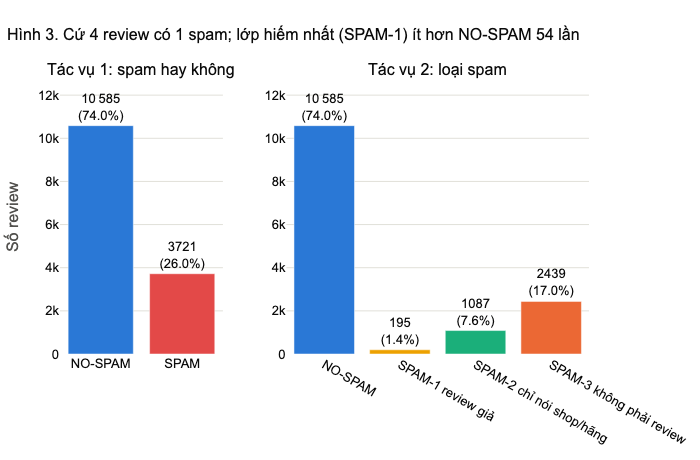

In [23]:
label_counts = train["label_name"].value_counts().sort_index()
type_counts = train["type_name"].value_counts().sort_index()

fig = make_subplots(rows=1, cols=2, column_widths=[0.35, 0.65], horizontal_spacing=0.12,
                    subplot_titles=("Tác vụ 1: spam hay không", "Tác vụ 2: loại spam"))
for col, counts, colors in [(1, label_counts, LABEL_COLORS), (2, type_counts, TYPE_COLORS)]:
    fig.add_trace(go.Bar(
        x=counts.index, y=counts.values, marker_color=[colors[name] for name in counts.index],
        customdata=counts.values / len(train) * 100,
        text=[f"{format_number(n)}<br>({n / len(train):.1%})" for n in counts], textposition="outside",
        hovertemplate="%{x}<br>%{y} review (%{customdata:.1f}% tập train)<extra></extra>"), row=1, col=col)
    fig.update_yaxes(range=[0, counts.max() * 1.2], row=1, col=col)
fig.update_yaxes(title_text="Số review", row=1, col=1)

ratio = type_counts.max() / type_counts.min()
show_fig(fig, f"Cứ 4 review có 1 spam; lớp hiếm nhất (SPAM-1) ít hơn NO-SPAM {ratio:.0f} lần",
         height=460, showlegend=False)

**Nhận xét.**
- **Tác vụ 1 mất cân bằng vừa phải:** 26.0% là spam, nên một mô hình luôn đoán NO-SPAM đã đạt độ chính xác 74%. Vì vậy độ chính xác (accuracy) không đủ; thước đo chính sẽ là **F1-macro** (mỗi lớp có trọng số như nhau), giống bài báo.
- **Tác vụ 2 mất cân bằng nặng:** SPAM-1 chỉ có 195 review trong train (1.4%), ít hơn NO-SPAM 54 lần. Học lớp này từ quá ít ví dụ là phần khó nhất của bộ dữ liệu, cần dùng trọng số lớp.

### 5.2 Số sao phân bố thế nào?

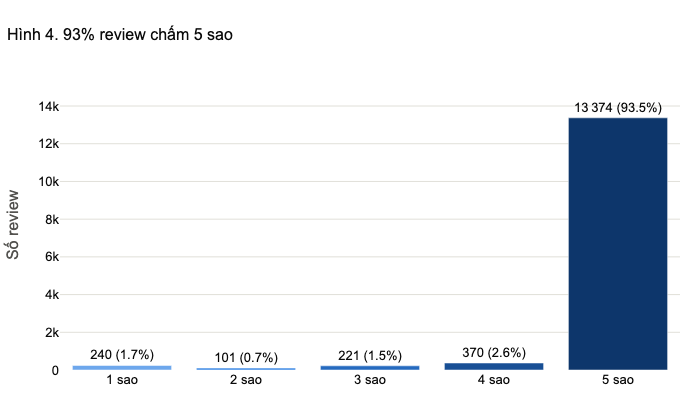

In [24]:
rating_counts = train[RATING_COL].value_counts().sort_index()
fig = go.Figure(go.Bar(
    x=[f"{r} sao" for r in rating_counts.index], y=rating_counts.values, marker_color=SEQ_BLUE[2:7],
    customdata=rating_counts.values / len(train) * 100,
    text=[f"{format_number(n)} ({n / len(train):.1%})" for n in rating_counts], textposition="outside",
    hovertemplate="%{x}<br>%{y} review (%{customdata:.1f}% tập train)<extra></extra>"))
show_fig(fig, f"{rating_counts[5] / len(train):.0%} review chấm 5 sao",
         yaxis_title="Số review", yaxis_range=[0, rating_counts.max() * 1.15], height=420)

**Nhận xét.** Số sao lệch rất mạnh: 93.5% review chấm 5 sao, chỉ 2.4% chấm 1 hoặc 2 sao. Khi gần như ai cũng chấm 5 sao thì riêng số sao mang rất ít thông tin; phần 5.4 sẽ kiểm tra điều này.

### 5.3 Review dài bao nhiêu?

Độ dài đo bằng **số tiếng** sau chuẩn hóa (xem 3.1). Review dài nhất chỉ có vài trăm tiếng nên biểu đồ vẽ toàn bộ khoảng giá trị.

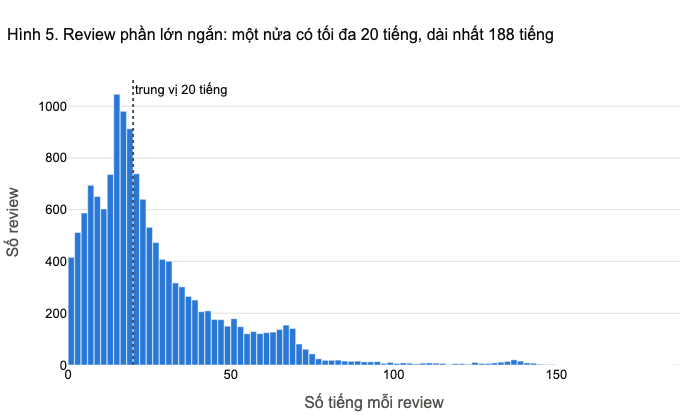

,count,mean,std,min,25%,50%,75%,99%,max,mode
số tiếng,14306.0,25.9,21.7,0.0,12.0,20.0,34.0,110.0,188.0,15
số từ (sau tách từ),14306.0,22.0,18.8,0.0,10.0,17.0,29.0,95.0,169.0,13
số ký tự,14306.0,121.5,94.8,1.0,63.0,92.0,155.0,498.0,1084.0,300


In [25]:
median_syllables = train["n_syllables"].median()
max_syllables = train["n_syllables"].max()
bin_edges = np.arange(0, max_syllables + 2, 2)                 # mỗi cột rộng 2 tiếng
bin_counts, _ = np.histogram(train["n_syllables"], bins=bin_edges)

fig = go.Figure(go.Bar(
    x=bin_edges[:-1] + 1, y=bin_counts, width=1.9, marker_color=BLUE,
    customdata=np.stack([bin_edges[:-1], bin_edges[1:] - 1, bin_counts / len(train) * 100], axis=-1),
    hovertemplate="%{customdata[0]:.0f} đến %{customdata[1]:.0f} tiếng<br>%{y} review (%{customdata[2]:.1f}%)<extra></extra>"))
fig.add_vline(x=median_syllables, line_dash="dot", line_color="#52514e",
              annotation_text=f"trung vị {median_syllables:.0f} tiếng", annotation_position="top right")
show_fig(fig, f"Review phần lớn ngắn: một nửa có tối đa {median_syllables:.0f} tiếng, dài nhất {max_syllables} tiếng",
         xaxis_title="Số tiếng mỗi review", yaxis_title="Số review", height=420)

length_summary = train[["n_syllables", "n_words", "n_chars"]].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T
length_summary["mode"] = train[["n_syllables", "n_words", "n_chars"]].mode().iloc[0].to_numpy()   # giá trị gặp nhiều nhất
length_summary.index = ["số tiếng", "số từ (sau tách từ)", "số ký tự"]
show_table(length_summary, "Thống kê độ dài review")

**Nhận xét.**
- Review ngắn: trung vị 20 tiếng (17 từ, 92 ký tự), 75% review có tối đa 34 tiếng, 99% có tối đa 110 tiếng, dài nhất 188 tiếng.
- Độ dài gặp nhiều nhất (mode) là 15 tiếng và 13 từ, thấp hơn trung vị, đúng với một phân bố lệch phải.
- **Riêng số ký tự có mode là 300**: 262 review dài đúng 300 ký tự, nhiều review bị cắt giữa chữ ("... kể từ ngày giải ngâ"). Nhiều khả năng dữ liệu gốc bị cắt ở 300 ký tự khi thu thập, dù vẫn có 455 review dài hơn nên giới hạn này không áp dụng cho mọi nguồn. 74% số review này là SPAM-3 (tin quảng cáo dài). Đây là đặc điểm của **cách thu thập**, không phải của spam: review mới sẽ không bị cắt như vậy, nên độ dài "đúng 300 ký tự" **không** được dùng làm đặc trưng.
- Đếm theo từ cho số nhỏ hơn khoảng 15% so với đếm theo tiếng, vì nhiều từ gồm hai tiếng ("sản_phẩm", "chất_lượng").
- Phân bố lệch phải, có một cái bướu nhỏ quanh 60 đến 72 tiếng. Ở khoảng này SPAM-3 chiếm 33% (so với 17% trên toàn tập train): đó là các tin quảng cáo và bài báo dài được dán vào. 185 trong 826 review của khoảng này là các review bị cắt ở 300 ký tự (trung vị 66 tiếng).
- 50 review có **0 tiếng** sau chuẩn hóa: chúng chỉ chứa emoji hoặc ký hiệu (4.5).

### 5.4 Số sao có giúp nhận ra spam không?

Bên trái: tỷ lệ spam ở mỗi mức sao. Bên phải: thành phần các lớp ở mỗi mức sao. Nếu số sao tách được spam với review thường, tỷ lệ spam sẽ thay đổi mạnh giữa các mức sao.

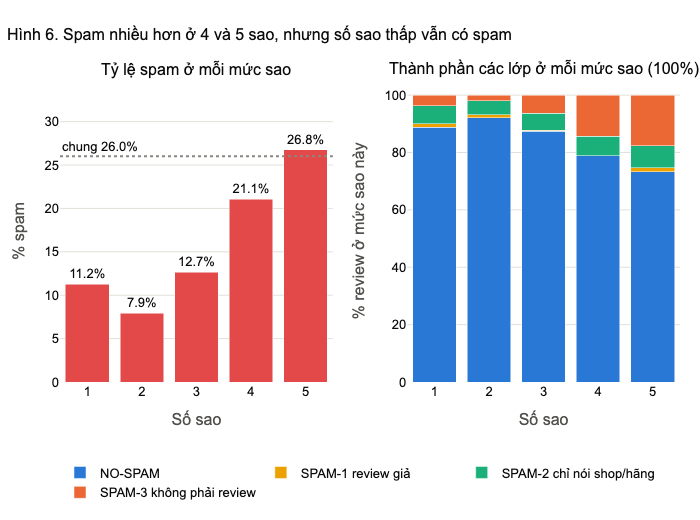

In [26]:
rating_by_type = pd.crosstab(train[RATING_COL], train["type_name"])
rating_total = rating_by_type.sum(axis=1)
spam_count = rating_by_type.drop(columns="NO-SPAM").sum(axis=1)
spam_rate = spam_count / rating_total * 100
overall_spam_rate = train[LABEL_COL].mean() * 100

fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.12,
                    subplot_titles=("Tỷ lệ spam ở mỗi mức sao", "Thành phần các lớp ở mỗi mức sao (100%)"))
fig.add_trace(go.Bar(
    x=spam_rate.index, y=spam_rate.values, marker_color=RED, showlegend=False,
    customdata=np.stack([spam_count, rating_total], axis=-1),
    text=[f"{v:.1f}%" for v in spam_rate], textposition="outside",
    hovertemplate="%{x} sao<br>%{customdata[0]} / %{customdata[1]} review là spam (%{y:.1f}%)<extra></extra>"),
    row=1, col=1)
fig.add_hline(y=overall_spam_rate, line_dash="dot", line_color=MUTED, row=1, col=1,
              annotation_text=f"chung {overall_spam_rate:.1f}%", annotation_position="top left")
for type_name in rating_by_type.columns:
    fig.add_trace(go.Bar(
        x=rating_by_type.index, y=rating_by_type[type_name] / rating_total * 100, name=type_name,
        marker_color=TYPE_COLORS[type_name], customdata=np.stack([rating_by_type[type_name], rating_total], axis=-1),
        hovertemplate="%{x} sao<br>" + type_name + ": %{customdata[0]} / %{customdata[1]} review (%{y:.1f}%)<extra></extra>"),
        row=1, col=2)
fig.update_xaxes(title_text="Số sao", dtick=1)
fig.update_yaxes(title_text="% spam", range=[0, spam_rate.max() * 1.3], row=1, col=1)
fig.update_yaxes(title_text="% review ở mức sao này", row=1, col=2)
show_fig(fig, "Spam nhiều hơn ở 4 và 5 sao, nhưng số sao thấp vẫn có spam",
         barmode="stack", height=520, legend=BOTTOM_LEGEND)

**Nhận xét.**
- Tỷ lệ spam tăng theo số sao: 8 đến 13% ở 1 đến 3 sao, 21% ở 4 sao, 27% ở 5 sao.
- Nhưng số sao không tách được các lớp: **96% review spam và 93% review thường đều chấm 5 sao**. Người viết spam cũng chấm điểm tối đa như mọi người, khớp với kết luận của bài báo rằng số sao không đáng tin.
- Phần tăng ở 4 và 5 sao chủ yếu đến từ SPAM-3 (màu cam ở biểu đồ phải): 18% review 5 sao là SPAM-3, so với 4% review 1 sao.

**Quyết định.** Có thể thử số sao như một đặc trưng phụ, nhưng phần lớn thông tin phải đến từ nội dung văn bản.

### 5.5 Độ dài review có khác nhau giữa các loại spam không?

Mỗi hộp thể hiện 50% review ở giữa của một lớp: từ phân vị 25% đến 75%, đường liền là trung vị, đường nét đứt là trung bình. Hai râu dừng ở độ dài xa nhất còn nằm trong khoảng 1.5 lần chiều cao hộp tính từ mép hộp (quy tắc Tukey). Các review dài hơn râu không được vẽ để hình gọn. Rê chuột để xem các giá trị này.

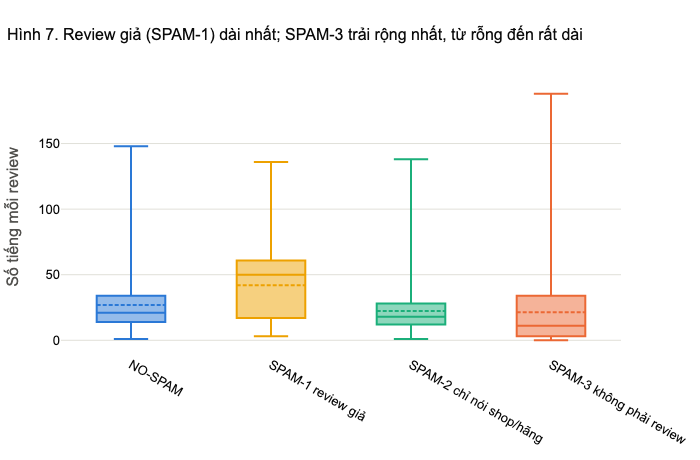

In [27]:
fig = go.Figure()
for type_name in TYPE_NAMES.values():
    fig.add_trace(go.Box(y=train.loc[train["type_name"] == type_name, "n_syllables"], name=type_name,
                         marker_color=TYPE_COLORS[type_name], boxmean=True, boxpoints=False))
show_fig(fig, "Review giả (SPAM-1) dài nhất; SPAM-3 trải rộng nhất, từ rỗng đến rất dài",
         yaxis_title="Số tiếng mỗi review", height=460, showlegend=False)

**Nhận xét.**
- **Review giả (SPAM-1) dài nhất:** trung vị 50 tiếng, gần gấp 2.5 lần review thường (21 tiếng). Lời khen phóng đại và các văn mẫu (5.10) thường dài dòng.
- **SPAM-2 ngắn hơn review thường một chút** (trung vị 18 tiếng): "giao nhanh, đóng gói cẩn thận" chỉ cần vài tiếng.
- **SPAM-3 trải rộng nhất** (từ 3 đến 34 tiếng ở hai mép hộp, trung vị chỉ 11): lớp này trộn cả review rỗng, vài tiếng vô nghĩa với tin quảng cáo và bài báo dài.
- Độ dài có ích nhưng các hộp chồng lên nhau nhiều: không có một ngưỡng độ dài nào tách được các lớp.

### 5.6 Dấu hiệu cách viết nào phân biệt các loại spam?

Với mỗi dấu hiệu định nghĩa ở 4.7, bản đồ nhiệt cho biết bao nhiêu % review của mỗi lớp có dấu hiệu đó. Một dòng có màu rất khác nhau giữa các cột là dấu hiệu hữu ích cho mô hình. Rê chuột để xem số review cụ thể.

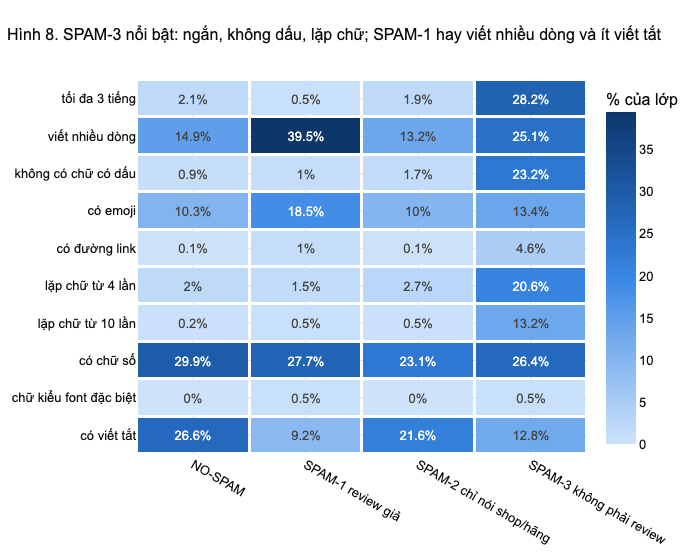

In [28]:
class_sizes = train["type_name"].value_counts().sort_index()
signal_counts = train.groupby("type_name")[list(SIGNALS)].sum().T
signal_rates = signal_counts / class_sizes.values * 100
signal_labels = [SIGNALS[col][0] for col in signal_rates.index]

fig = go.Figure(go.Heatmap(
    z=signal_rates.values, x=signal_rates.columns, y=signal_labels,
    colorscale=SEQ_BLUE, text=signal_rates.round(1).values, texttemplate="%{text}%",
    customdata=np.dstack([signal_counts.values, np.tile(class_sizes.values, (len(signal_labels), 1))]),
    colorbar=dict(title="% của lớp"), xgap=3, ygap=3,
    hovertemplate="%{y} | %{x}<br>%{customdata[0]} / %{customdata[1]} review (%{z:.1f}%)<extra></extra>"))
show_fig(fig, "SPAM-3 nổi bật: ngắn, không dấu, lặp chữ; SPAM-1 hay viết nhiều dòng và ít viết tắt",
         height=560, yaxis_autorange="reversed")

**Nhận xét.** Bản đồ nhiệt cho thấy các dấu hiệu đơn giản chỉ ra SPAM-3:
- **Tối đa 3 tiếng:** 28.2% SPAM-3 so với 2.1% NO-SPAM.
- **Không có chữ có dấu:** 23.2% so với 0.9%.
- **Lặp chữ từ 4 lần:** 20.6% so với 2.0%; **từ 10 lần:** 13.2% so với 0.2%. Bài báo cũng nhận xét người viết lặp ký tự ("shopppppp", "lýyyyyyy") để kéo dài review cho đủ độ dài, nhiều khả năng để đạt điều kiện nhận thưởng.
- **Có đường link:** 4.6% so với 0.1%; **chữ kiểu font đặc biệt:** 12 trong 13 review có dấu hiệu này là SPAM-3.

**SPAM-1 nổi bật theo cách khác:** 39.5% viết nhiều dòng (so với 14.9%), 18.5% có emoji (so với 10.3%) và chỉ 9.2% viết tắt (so với 26.6%), đúng với đặc điểm của văn mẫu dài, trình bày đẹp.

Chữ số xuất hiện đều ở mọi lớp nên không giúp phân biệt.

**Quyết định.** n-gram ký tự (bắt được chữ lặp và văn bản không dấu) cùng các dòng nổi bật của bản đồ nhiệt là các đặc trưng nên thử.

### 5.7 Review nói về điều gì? (theo định nghĩa nhãn của bài báo)

Bài báo định nghĩa SPAM-2 là review chỉ nói về **thương hiệu, shop hoặc giao hàng** mà không đánh giá sản phẩm. Để kiểm tra định nghĩa này trên dữ liệu, ta đánh dấu mỗi review theo các nhóm chủ đề, dựa trên danh sách từ khóa (so khớp nguyên cụm trong văn bản đã chuẩn hóa). Giống danh sách viết tắt ở 4.6.2, **các nhóm chủ đề và từ khóa do nhóm tự lập** từ định nghĩa nhãn của bài báo và từ việc đọc review, nên có thể thiếu một số cách nói.

,từ khóa (biểu thức chính quy)
"giao hàng, đóng gói",\b(giao hàng|giao nhanh|ship|shipper|đóng gói|gói hàng|vận chuyển|nhận hàng|nhận được hàng)\b
"shop, người bán",\b(shop|người bán|cửa hàng|chủ shop|nhà bán)\b
"sàn TMĐT (Tiki, Shopee, ...)",\b(tiki|shopee|lazada|sendo|sàn)\b
"thương hiệu, chính hãng",\b(thương hiệu|chính hãng|hãng)\b
"sản phẩm, chất lượng",\b(sản phẩm|chất lượng|sp)\b
"chưa dùng, chưa biết",\b(chưa dùng|chưa sử dụng|chưa xài|chưa biết|chưa thử|chưa sd)\b
"xu, mã giảm giá",\b(xu|nhận xu|mã giảm|voucher|freeship)\b


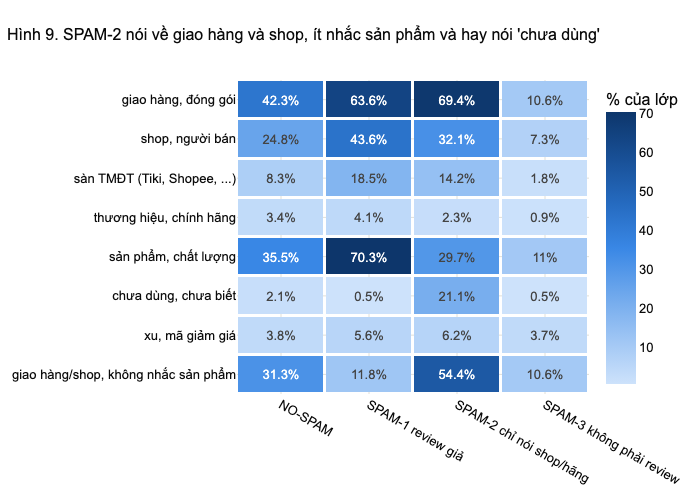

nội dung review
"Giao nhanh cực 😂🌟 Đặt lúc 12h50 mà 14h Tiki giao tới rồi 👍🌟👍🌟 Đóng gói cẩn thận, chưa test máy ntn nhưng hài lòng dịch vụ Tiki👍👍👍"
"Mình rất hài lòng khi nhận được hàng. Mua nhiều món linh tinh shop giao đầy đủ. Hộp màu hơi móp méo 1 chút do vận chuyển nhưng bên trong không bị hư hao gì. Lần sau sẽ ủng hộ tiếp,,,,,"
Giao hàng hơi lâu. Chắc do dịch. Hàng đóng gói đầy đủ chắc chắn. Chưa sd nên chưa biết mùi vị như nào


In [29]:
TOPICS = {
    "giao hàng, đóng gói": r"\b(giao hàng|giao nhanh|ship|shipper|đóng gói|gói hàng|vận chuyển|nhận hàng|nhận được hàng)\b",
    "shop, người bán": r"\b(shop|người bán|cửa hàng|chủ shop|nhà bán)\b",
    "sàn TMĐT (Tiki, Shopee, ...)": r"\b(tiki|shopee|lazada|sendo|sàn)\b",
    "thương hiệu, chính hãng": r"\b(thương hiệu|chính hãng|hãng)\b",
    "sản phẩm, chất lượng": r"\b(sản phẩm|chất lượng|sp)\b",
    "chưa dùng, chưa biết": r"\b(chưa dùng|chưa sử dụng|chưa xài|chưa biết|chưa thử|chưa sd)\b",
    "xu, mã giảm giá": r"\b(xu|nhận xu|mã giảm|voucher|freeship)\b",
}
show_table(pd.DataFrame({"từ khóa (biểu thức chính quy)": list(TOPICS.values())}, index=list(TOPICS)),
           "Từ khóa của từng nhóm chủ đề", text_columns=["từ khóa (biểu thức chính quy)"])

topic_flags = pd.DataFrame({name: train["clean"].str.contains(pattern) for name, pattern in TOPICS.items()})
# Nói về giao hàng hoặc shop nhưng không nhắc đến sản phẩm: đúng mô tả của SPAM-2
topic_flags["giao hàng/shop, không nhắc sản phẩm"] = (
    (topic_flags["giao hàng, đóng gói"] | topic_flags["shop, người bán"]) & ~topic_flags["sản phẩm, chất lượng"])

topic_counts = topic_flags.groupby(train["type_name"]).sum().T
topic_rates = topic_counts / class_sizes.values * 100
fig = go.Figure(go.Heatmap(
    z=topic_rates.values, x=topic_rates.columns, y=topic_rates.index,
    colorscale=SEQ_BLUE, text=topic_rates.round(1).values, texttemplate="%{text}%",
    customdata=np.dstack([topic_counts.values, np.tile(class_sizes.values, (len(topic_rates), 1))]),
    colorbar=dict(title="% của lớp"), xgap=3, ygap=3,
    hovertemplate="%{y} | %{x}<br>%{customdata[0]} / %{customdata[1]} review (%{z:.1f}%)<extra></extra>"))
show_fig(fig, "SPAM-2 nói về giao hàng và shop, ít nhắc sản phẩm và hay nói 'chưa dùng'",
         height=500, yaxis_autorange="reversed")

spam2_examples = train.loc[(train["type_name"] == "SPAM-2 chỉ nói shop/hãng")
                        & topic_flags["giao hàng/shop, không nhắc sản phẩm"], [TEXT_COL]].sample(3, random_state=SEED)
show_table(spam2_examples.set_axis(["nội dung review"], axis=1), "Ví dụ SPAM-2: nói về giao hàng hoặc shop, không nhắc sản phẩm",
           text_columns=["nội dung review"], hide_index=True)

**Nhận xét.** Dữ liệu xác nhận định nghĩa SPAM-2 của bài báo:
- **69% SPAM-2 nói về giao hàng hoặc đóng gói**, nhưng chỉ **30% nhắc đến sản phẩm hay chất lượng** (thấp hơn cả review thường, 36%).
- **54% SPAM-2 nói về giao hàng hoặc shop mà không hề nhắc sản phẩm**, so với 31% review thường.
- **21% SPAM-2 nói "chưa dùng", "chưa biết"**, trong khi các lớp khác chỉ 0 đến 2%: người viết chưa dùng sản phẩm nên chỉ có thể nói về việc giao hàng.

SPAM-1 có tỷ lệ cao ở **nhiều** chủ đề (sản phẩm 70%, giao hàng 64%, shop 44%, sàn TMĐT 19%), vì văn mẫu cảm ơn tất cả mọi người: nhà cung cấp, người bán, sàn thương mại điện tử, người vận chuyển (xem 5.10). SPAM-3 thấp ở mọi chủ đề vì nó không phải là review mua hàng.

**Lưu ý:** 31% review thường cũng chỉ nói giao hàng hoặc shop mà không nhắc sản phẩm (ví dụ "giao nhanh, đóng gói kỹ, sẽ ủng hộ tiếp"). Ranh giới SPAM-2 và NO-SPAM vì vậy rất mờ, đúng như bài báo ghi nhận, và đây sẽ là nguồn lỗi chính của mô hình.

### 5.8 Từ vựng: đếm theo tiếng và theo từ

`CountVectorizer` tạo bộ từ vựng và đếm số lần mỗi phần tử xuất hiện trong mỗi review. Ta chạy hai lần: một lần trên văn bản chuẩn hóa (đơn vị là **tiếng**) và một lần trên văn bản đã tách từ (đơn vị là **từ**, xem 3.1).

- Bên trái: 20 từ phổ biến nhất (dấu `_` nối các tiếng của cùng một từ).
- Bên phải: N phần tử phổ biến nhất chiếm bao nhiêu % tổng số lần xuất hiện, cho biết mô hình thực sự cần bao nhiêu tiếng hay bao nhiêu từ.

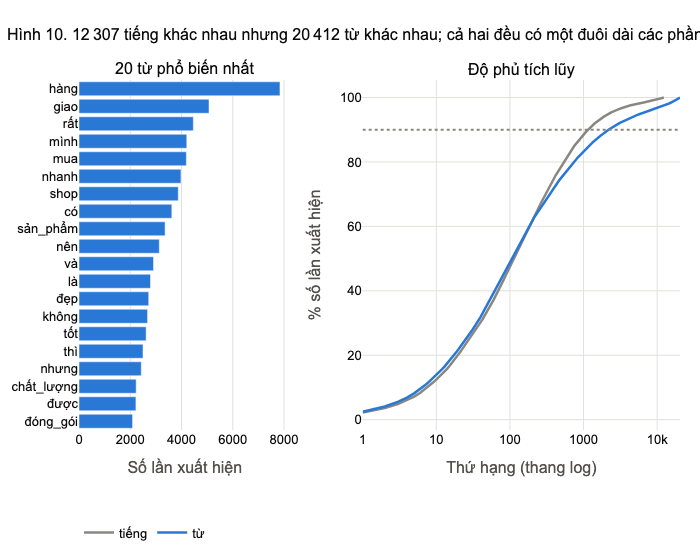

,số phần tử khác nhau,số phần tử phổ biến nhất chiếm 90%,% phần tử chỉ xuất hiện 1 lần,% phần tử gồm nhiều tiếng
đơn vị,,,,
tiếng,12 307,1148,56.0,0.4
từ,20 412,2196,64.3,50.2


Ví dụ các từ chỉ xuất hiện 1 lần: tổng_tiến_công, xám_nha, trung_đoàn, mmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmnmmnmmmmnnnnnnnnnnnnnnnnnnnnnnnnmmmmmmmmmmmmmm, cjks, tự_xoay, lời_lẽ, nhảy_số, thể, mịn_popular, vui_phết, 你也快来表态吧, shinamo, đieu, thuôca


In [30]:
def count_units(texts):
    """Đếm số lần xuất hiện và số review chứa mỗi phần tử (tiếng hoặc từ), sắp giảm dần."""
    vectorizer = CountVectorizer(token_pattern=TOKEN_PATTERN)
    matrix = vectorizer.fit_transform(texts)
    names = vectorizer.get_feature_names_out()
    totals = pd.Series(np.asarray(matrix.sum(axis=0)).ravel(), index=names)
    reviews = pd.Series(np.asarray((matrix > 0).sum(axis=0)).ravel(), index=names)
    return pd.DataFrame({"số lần": totals, "số review": reviews}).sort_values("số lần", ascending=False)


units = {"tiếng": count_units(train["clean"]), "từ": count_units(train["words"])}

vocab_rows, coverage = [], {}
for unit_name, counts in units.items():
    coverage[unit_name] = counts["số lần"].cumsum() / counts["số lần"].sum() * 100
    vocab_rows.append({"đơn vị": unit_name,
                       "số phần tử khác nhau": len(counts),
                       "số phần tử phổ biến nhất chiếm 90%": int((coverage[unit_name] < 90).sum()) + 1,
                       "% phần tử chỉ xuất hiện 1 lần": (counts["số lần"] == 1).mean() * 100,
                       "% phần tử gồm nhiều tiếng": counts.index.str.contains("_").mean() * 100})
vocab_summary = pd.DataFrame(vocab_rows).set_index("đơn vị")

top_words = units["từ"].head(20).iloc[::-1]
fig = make_subplots(rows=1, cols=2, column_widths=[0.4, 0.6], horizontal_spacing=0.12,
                    subplot_titles=("20 từ phổ biến nhất", "Độ phủ tích lũy"))
fig.add_trace(go.Bar(
    x=top_words["số lần"], y=top_words.index, orientation="h", marker_color=BLUE, showlegend=False,
    customdata=np.stack([top_words["số review"], top_words["số review"] / len(train) * 100], axis=-1),
    hovertemplate='"%{y}": %{x} lần<br>có trong %{customdata[0]} review (%{customdata[1]:.1f}%)<extra></extra>'),
    row=1, col=1)
for unit_name, color in [("tiếng", MUTED), ("từ", BLUE)]:
    curve = coverage[unit_name]
    fig.add_trace(go.Scatter(x=np.arange(1, len(curve) + 1), y=curve.values, mode="lines", name=unit_name,
                             line=dict(color=color, width=2.5),
                             hovertemplate="%{x} " + unit_name + " phổ biến nhất chiếm %{y:.1f}% số lần xuất hiện<extra></extra>"),
                  row=1, col=2)
fig.add_hline(y=90, line_dash="dot", line_color=MUTED, row=1, col=2)
fig.update_xaxes(title_text="Số lần xuất hiện", row=1, col=1)
fig.update_xaxes(title_text="Thứ hạng (thang log)", type="log", row=1, col=2)
fig.update_yaxes(title_text="% số lần xuất hiện", row=1, col=2)
show_fig(fig, f"{format_number(len(units['tiếng']))} tiếng khác nhau nhưng {format_number(len(units['từ']))} từ khác nhau; "
              f"cả hai đều có một đuôi dài các phần tử hiếm", height=560, legend=BOTTOM_LEGEND)

show_table(vocab_summary, "So sánh bộ từ vựng khi đếm theo tiếng và theo từ")
rare_words = units["từ"].loc[units["từ"]["số lần"] == 1].sample(15, random_state=SEED)
print("Ví dụ các từ chỉ xuất hiện 1 lần:", ", ".join(rare_words.index))

**Nhận xét.**
- Đếm theo tiếng, tập train có **12 307 tiếng khác nhau**; đếm theo từ có **20 412 từ khác nhau**. Bộ từ lớn hơn vì cùng một tiếng nằm trong nhiều từ ("hàng" có trong "hàng", "cửa_hàng", "mặt_hàng", ...), và một nửa số từ gồm từ hai tiếng trở lên.
- Cả hai đều có đuôi dài: **1148 tiếng** hay **2196 từ** phổ biến nhất đã chiếm 90% số lần xuất hiện, trong khi **56% số tiếng và 64% số từ chỉ xuất hiện 1 lần**. Các phần tử hiếm là chuỗi gõ bừa, chữ lặp, số kèm đơn vị, và cả các lỗi ghép sai của công cụ tách từ ("nhỏ_nha", "chuẩn_tefal", "bàn_mng").
- Các từ phổ biến nhất mô tả trải nghiệm mua hàng ("hàng", "giao", "nhanh", "shop", "sản_phẩm", "chất_lượng", "đóng_gói") và có mặt ở mọi lớp, nên đếm thô không phân biệt được spam.

**Quyết định.** Dùng TF-IDF (giảm trọng số các phần tử có ở khắp nơi) với tần suất tài liệu tối thiểu `min_df` từ 2 đến 5 để bỏ các phần tử chỉ xuất hiện một lần: cách này loại hơn một nửa bộ từ vựng mà mất rất ít văn bản. Có thể so sánh mô hình dùng tiếng và dùng từ ở bước xây dựng mô hình.

### 5.9 Từ nào đặc trưng cho mỗi loại spam?

**Lấy ra các "term" như thế nào?** Mỗi review đã tách từ được cắt thành:
- **1-gram:** từng từ riêng lẻ, ví dụ `chưa`, `sử_dụng`;
- **2-gram:** từng cặp hai từ đứng liền nhau, ví dụ `chưa sử_dụng`.

Mỗi 1-gram hay 2-gram gọi chung là một **term**. 2-gram giữ được ý nghĩa mà một từ đứng riêng không có: "chưa" và "sử_dụng" đều phổ biến, nhưng "chưa sử_dụng" mới cho biết người viết chưa dùng sản phẩm. Ta chỉ giữ các term xuất hiện trong **ít nhất 10 review** để loại lỗi gõ và tên riêng.

In [31]:
demo_sentence = "Chưa sử dụng nên chưa biết chất lượng"
demo_terms = list(CountVectorizer(token_pattern=TOKEN_PATTERN, ngram_range=(1, 2))
                  .fit([segment_words(demo_sentence)]).get_feature_names_out())
show_table(pd.DataFrame({
    "bước": ["sau khi tách từ", "1-gram (1 từ)", "2-gram (2 từ liền nhau)"],
    "kết quả": [segment_words(demo_sentence),
                ", ".join(t for t in demo_terms if " " not in t), ", ".join(t for t in demo_terms if " " in t)],
}), f'Ví dụ: các term của câu "{demo_sentence}"', text_columns=["kết quả"], hide_index=True)

bước,kết quả
sau khi tách từ,chưa sử_dụng nên chưa biết chất_lượng
1-gram (1 từ),"biết, chưa, chất_lượng, nên, sử_dụng"
2-gram (2 từ liền nhau),"biết chất_lượng, chưa biết, chưa sử_dụng, nên chưa, sử_dụng nên"


**Vì sao không dùng số lần xuất hiện trực tiếp?** Các term phổ biến như "hàng", "shop" xuất hiện ở mọi lớp nên không nói lên gì. Ta dùng **tỷ số log-odds**, so sánh tần suất của một term **trong** một lớp với tần suất của nó **ở các lớp còn lại**:

$$\text{điểm}(t, c) = \log\frac{(n_{t,c} + 1) / (N_c + V)}{(n_{t,\bar c} + 1) / (N_{\bar c} + V)}$$

- $n_{t,c}$: số lần term $t$ xuất hiện trong lớp $c$; $n_{t,\bar c}$: số lần ở các lớp còn lại;
- $N_c$, $N_{\bar c}$: tổng số lần xuất hiện của mọi term trong lớp $c$ và trong các lớp còn lại;
- $V$: số term trong bộ từ vựng; cộng 1 để không chia cho 0 khi một term không xuất hiện ở một bên.

Điểm **lớn hơn 0** nghĩa là term xuất hiện trong lớp $c$ thường hơn ở nơi khác; điểm 2 nghĩa là thường hơn khoảng $e^2 \approx 7$ lần. Bảng dưới tính từng bước cho hai term của lớp SPAM-2:

In [32]:
term_vectorizer = CountVectorizer(token_pattern=TOKEN_PATTERN, ngram_range=(1, 2), min_df=10)
term_matrix = term_vectorizer.fit_transform(train["words"])
terms = term_vectorizer.get_feature_names_out()
vocab_size = len(terms)
print(f"Số term (1-gram và 2-gram) có trong ít nhất 10 review: V = {format_number(vocab_size)}")


def log_odds_table(type_name):
    """Số lần xuất hiện trong lớp, ngoài lớp và điểm log-odds của mọi term cho một lớp."""
    in_class = (train["type_name"] == type_name).to_numpy()
    count_in = np.asarray(term_matrix[in_class].sum(axis=0)).ravel()
    count_out = np.asarray(term_matrix[~in_class].sum(axis=0)).ravel()
    score = (np.log((count_in + 1) / (count_in.sum() + vocab_size))
             - np.log((count_out + 1) / (count_out.sum() + vocab_size)))
    return pd.DataFrame({"trong lớp": count_in, "ngoài lớp": count_out, "điểm": score,
                         "N lớp": count_in.sum(), "N ngoài": count_out.sum()}, index=terms)


spam2_scores = log_odds_table("SPAM-2 chỉ nói shop/hãng")
worked = spam2_scores.loc[["chưa sử_dụng", "giao hàng"]].copy()
worked["tần suất trong lớp"] = (worked["trong lớp"] + 1) / (worked["N lớp"] + vocab_size)
worked["tần suất ngoài lớp"] = (worked["ngoài lớp"] + 1) / (worked["N ngoài"] + vocab_size)
worked = worked[["trong lớp", "N lớp", "tần suất trong lớp", "ngoài lớp", "N ngoài", "tần suất ngoài lớp", "điểm"]]
show_table(worked, "Tính điểm log-odds cho lớp SPAM-2 với hai term", precision=4)

Số term (1-gram và 2-gram) có trong ít nhất 10 review: V = 5412


,trong lớp,N lớp,tần suất trong lớp,ngoài lớp,N ngoài,tần suất ngoài lớp,điểm
chưa sử_dụng,62,28 461,0.0019,27,364 255,0.0001,3.2009
giao hàng,497,28 461,0.0147,3101,364 255,0.0084,0.5608


**Cách đọc bảng.** "chưa sử_dụng" xuất hiện 62 lần trong SPAM-2 nhưng chỉ 27 lần ở toàn bộ các lớp còn lại, dù SPAM-2 chỉ chiếm khoảng 7% văn bản (28 461 trên gần 393 000 term). Tần suất trong lớp lớn hơn ngoài lớp khoảng 25 lần, nên điểm là log(25) ≈ 3.20. Ngược lại, "giao hàng" xuất hiện nhiều nhưng ở mọi lớp, chỉ thường hơn khoảng 1.75 lần trong SPAM-2, nên điểm chỉ 0.56. Log-odds vì vậy làm nổi bật những term **riêng** của một lớp, không phải những term **nhiều** nhất.

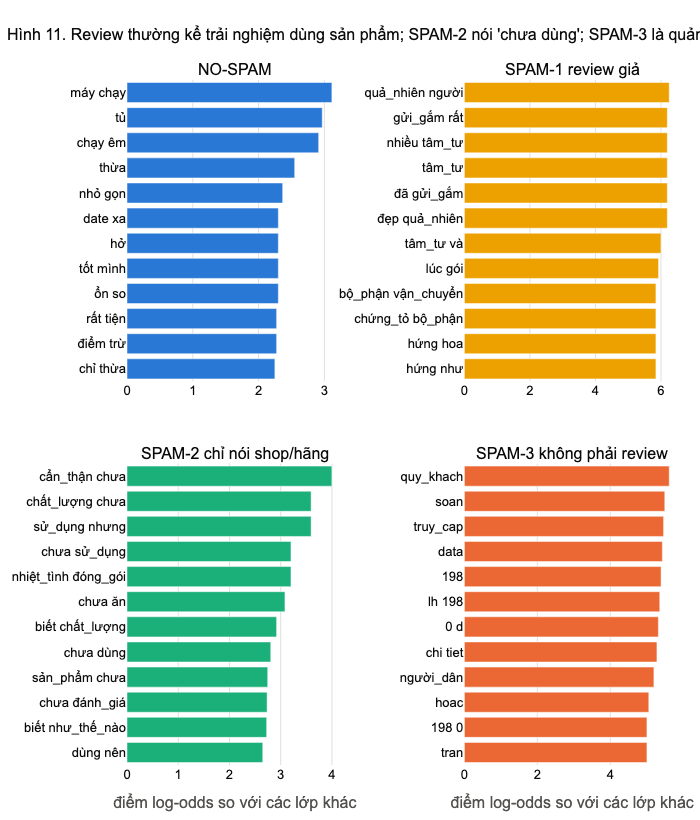

,NO-SPAM,SPAM-1 review giả,SPAM-2 chỉ nói shop/hãng,SPAM-3 không phải review
1-gram (1 từ),3,1,0,8
2-gram (2 từ),9,11,12,4


In [33]:
top_terms_by_type = {name: log_odds_table(name).nlargest(12, "điểm") for name in TYPE_NAMES.values()}

fig = make_subplots(rows=2, cols=2, subplot_titles=list(TYPE_NAMES.values()),
                    horizontal_spacing=0.22, vertical_spacing=0.12)
for i, type_name in enumerate(TYPE_NAMES.values()):
    top_terms = top_terms_by_type[type_name].iloc[::-1]
    n_gram = np.where(top_terms.index.str.contains(" "), "2 từ", "1 từ")
    fig.add_trace(go.Bar(
        x=top_terms["điểm"], y=top_terms.index, orientation="h", marker_color=TYPE_COLORS[type_name],
        customdata=np.stack([top_terms["trong lớp"], top_terms["ngoài lớp"], n_gram], axis=-1),
        hovertemplate=('"%{y}" (%{customdata[2]})<br>điểm %{x:.2f}<br>'
                       "%{customdata[0]} lần trong lớp, %{customdata[1]} lần ở lớp khác<extra></extra>")),
        row=i // 2 + 1, col=i % 2 + 1)
fig.update_xaxes(title_text="điểm log-odds so với các lớp khác", row=2)
show_fig(fig, "Review thường kể trải nghiệm dùng sản phẩm; SPAM-2 nói 'chưa dùng'; SPAM-3 là quảng cáo, tin tức",
         height=820, showlegend=False)

n_gram_mix = pd.DataFrame({name: pd.Series(np.where(t.index.str.contains(" "), "2-gram (2 từ)", "1-gram (1 từ)"))
                           .value_counts() for name, t in top_terms_by_type.items()}).fillna(0).astype(int)
show_table(n_gram_mix, "Trong 12 term điểm cao nhất của mỗi lớp: số 1-gram và 2-gram")

**Nhận xét.** Các term đặc trưng của mỗi lớp khớp với định nghĩa trong bài báo:
- **NO-SPAM:** trải nghiệm cụ thể khi dùng sản phẩm ("máy chạy", "chạy êm", "nhỏ gọn", "date xa" là hạn sử dụng còn xa, "điểm trừ").
- **SPAM-1:** các mảnh của cùng một văn mẫu phóng đại ("quả_nhiên người", "gửi_gắm rất", "nhiều tâm_tư", "bộ_phận vận_chuyển", "hứng như"), dấu hiệu đầu tiên của copy-paste (kiểm tra ở 5.10).
- **SPAM-2:** người mua **chưa dùng sản phẩm** ("chưa sử_dụng", "chưa dùng", "chưa ăn", "chưa đánh_giá", "biết chất_lượng"), khớp với Hình 9.
- **SPAM-3:** tin nhắn quảng cáo và tin tức viết không dấu ("quy_khach", "soan", "truy_cap", "data", "lh 198", "người_dân"). Công cụ tách từ ghép được cả "quy_khach", "truy_cap" dù không dấu, nhưng cũng tách lẻ "chi tiet", "tran trong".

**Vì sao phần lớn là cặp hai từ?** Bảng cuối cho thấy 9 đến 12 trong 12 term điểm cao nhất của NO-SPAM, SPAM-1 và SPAM-2 là 2-gram. Một từ riêng lẻ như "chưa" hay "chạy" xuất hiện trong rất nhiều ngữ cảnh, còn một cặp như "chưa sử_dụng" hay "máy chạy" cụ thể hơn nhiều nên đặc trưng hơn. Riêng SPAM-3 có 8 term 1-gram vì các từ như "soan", "data", "quy_khach" vốn đã gần như chỉ có trong tin quảng cáo. Điều này cho thấy **mô hình nên dùng cả 1-gram và 2-gram**.

### 5.10 Câu hỏi: review giả (SPAM-1) có phải là văn mẫu copy-paste?

Các term của SPAM-1 ở hình trước trông như những mảnh của cùng một câu dài. Để kiểm tra, ta tìm các **chuỗi 6 tiếng liền nhau xuất hiện trong ít nhất 10 review khác nhau**: một review thật hiếm khi trùng 6 tiếng liên tiếp với review khác một cách ngẫu nhiên. Hai ngưỡng (6 tiếng, 10 review) **do nhóm tự đặt**: chuỗi ngắn hơn thì gặp cả các cụm phổ biến như "giao hàng nhanh đóng gói", còn ngưỡng 10 review loại các lần trùng tình cờ.

- Bên trái: tỷ lệ review của mỗi lớp có chứa ít nhất một chuỗi như vậy.
- Bên phải: 6 chuỗi được SPAM-1 dùng nhiều nhất, tô màu theo nhãn của mọi review chứa chuỗi đó. Một chuỗi trùng từ 3 tiếng trở lên với chuỗi đã hiện thì bị bỏ qua, để các thanh không chỉ là cùng một đoạn bị dịch đi một tiếng.

Số chuỗi 6 tiếng có trong ít nhất 10 review: 226


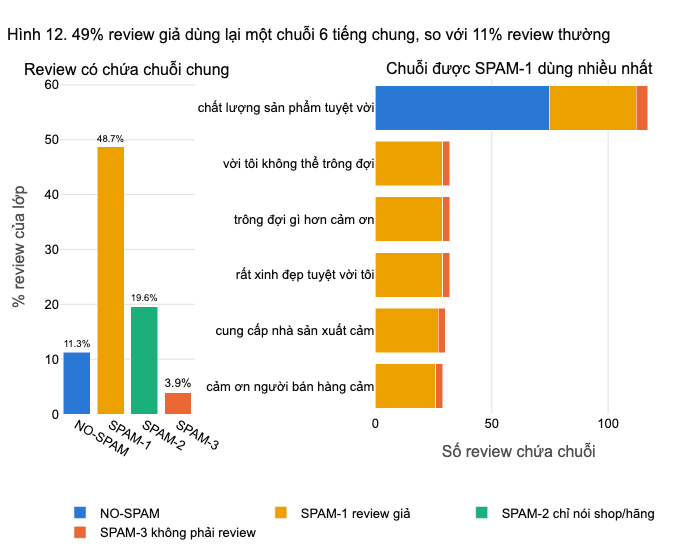

văn mẫu,cụm nhận diện,số review,trong đó SPAM-1,% SPAM-1 có văn mẫu,ví dụ
văn mẫu 1,tôi không thể trông đợi gì hơn,32,29,14.9,"Sản phẩm rất xinh đẹp tuyệt vời, tôi không thể trông đợi gì hơn. Cảm ơn nhà cung cấp, nhà sản xuất, cảm ơn người bán hàng, cảm ơn sàn thương mại điện tử, cảm ơn người vận chuyển để tôi có cơ hội dùng sản phẩm tốt như thế này."
văn mẫu 2,gửi gắm rất nhiều tâm tư,15,15,7.7,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hàng không có dấu hiệu bị thủng, chứng tỏ bộ phận vận chuyển đã nâng như nâng trứng, hứng như hứng hoa. Chất lượng quần thì quá xịn rồi nên mình mới mua theo. Xin nghiêng mình cảm ơn vì tất cả 🧡"


Review giả chứa ít nhất một trong hai văn mẫu: 41 / 195 (21.0%)


In [34]:
phrase_vectorizer = CountVectorizer(token_pattern=TOKEN_PATTERN, ngram_range=(6, 6), min_df=10, binary=True)
phrase_matrix = phrase_vectorizer.fit_transform(train["clean"])        # 1 nếu review chứa chuỗi đó
phrases = phrase_vectorizer.get_feature_names_out()
print(f"Số chuỗi 6 tiếng có trong ít nhất 10 review: {format_number(len(phrases))}")

# Bên trái: tỷ lệ review mỗi lớp có ít nhất một chuỗi chung
train["has_shared_phrase"] = np.asarray(phrase_matrix.sum(axis=1)).ravel() > 0
shared = train.groupby("type_name")["has_shared_phrase"].agg(["sum", "count", "mean"])

# Bên phải: với mỗi chuỗi, số review chứa nó theo từng lớp
phrase_by_type = pd.DataFrame({
    type_name: np.asarray(phrase_matrix[(train["type_name"] == type_name).to_numpy()].sum(axis=0)).ravel()
    for type_name in TYPE_NAMES.values()}, index=phrases)

kept = []    # các chuỗi SPAM-1 dùng nhiều nhất, bỏ chuỗi trùng nhiều tiếng với chuỗi đã chọn
for phrase in phrase_by_type["SPAM-1 review giả"].sort_values(ascending=False).index:
    if all(len(set(phrase.split()) & set(other.split())) < 3 for other in kept):
        kept.append(phrase)
    if len(kept) == 6:
        break
top_phrases = phrase_by_type.loc[kept]
phrase_totals = top_phrases.sum(axis=1)

fig = make_subplots(rows=1, cols=2, column_widths=[0.32, 0.68], horizontal_spacing=0.3,
                    subplot_titles=("Review có chứa chuỗi chung", "Chuỗi được SPAM-1 dùng nhiều nhất"))
fig.add_trace(go.Bar(
    x=[name.split(" ")[0] for name in shared.index], y=shared["mean"] * 100,
    marker_color=[TYPE_COLORS[t] for t in shared.index], showlegend=False,
    customdata=np.stack([shared.index, shared["sum"], shared["count"]], axis=-1),
    text=[f"{v:.1%}" for v in shared["mean"]], textposition="outside",
    hovertemplate="%{customdata[0]}<br>%{customdata[1]} / %{customdata[2]} review (%{y:.1f}%)<extra></extra>"),
    row=1, col=1)
for type_name in TYPE_NAMES.values():
    fig.add_trace(go.Bar(
        y=top_phrases.index[::-1], x=top_phrases[type_name][::-1], orientation="h",
        name=type_name, marker_color=TYPE_COLORS[type_name],
        customdata=(top_phrases[type_name] / phrase_totals * 100)[::-1],
        hovertemplate='"%{y}"<br>' + type_name + ": %{x} review (%{customdata:.0f}% số review chứa chuỗi)<extra></extra>"),
        row=1, col=2)
fig.update_yaxes(title_text="% review của lớp", range=[0, shared["mean"].max() * 125], row=1, col=1)
fig.update_xaxes(title_text="Số review chứa chuỗi", row=1, col=2)
show_fig(fig, f"{shared.loc['SPAM-1 review giả', 'mean']:.0%} review giả dùng lại một chuỗi 6 tiếng chung, "
              f"so với {shared.loc['NO-SPAM', 'mean']:.0%} review thường", barmode="stack", height=560,
         legend=BOTTOM_LEGEND)

# Hai văn mẫu dài nhất tìm được khi đọc các chuỗi ở trên
TEMPLATES = {
    "văn mẫu 1": "tôi không thể trông đợi gì hơn",
    "văn mẫu 2": "gửi gắm rất nhiều tâm tư",
}
template_rows = []
for name, phrase in TEMPLATES.items():
    contains = train["clean"].str.contains(phrase)
    template_rows.append({"văn mẫu": name, "cụm nhận diện": phrase, "số review": int(contains.sum()),
                          "trong đó SPAM-1": int((contains & (train[TYPE_COL] == 1)).sum()),
                          "% SPAM-1 có văn mẫu": (contains & (train[TYPE_COL] == 1)).sum() / (train[TYPE_COL] == 1).sum() * 100,
                          # ví dụ ưu tiên review chỉ chứa văn mẫu này (không chứa văn mẫu còn lại)
                          "ví dụ": train.loc[contains & ~train["clean"].str.contains("|".join(p for p in TEMPLATES.values() if p != phrase)),
                                          TEXT_COL].iloc[0]})
show_table(pd.DataFrame(template_rows), "Hai văn mẫu copy-paste của review giả", text_columns=["ví dụ"], hide_index=True)
any_template = train["clean"].str.contains("|".join(TEMPLATES.values()))
print(f"Review giả chứa ít nhất một trong hai văn mẫu: {(any_template & (train[TYPE_COL] == 1)).sum()} "
      f"/ {(train[TYPE_COL] == 1).sum()} ({(any_template & (train[TYPE_COL] == 1)).sum() / (train[TYPE_COL] == 1).sum():.1%})")

**Kết luận.** Đúng, review giả phần lớn là văn mẫu copy-paste.
- **49% review SPAM-1 có chứa một chuỗi 6 tiếng xuất hiện trong ít nhất 10 review**, so với 11% review thường, 20% SPAM-2 và 4% SPAM-3.
- Ở biểu đồ bên phải, trừ cụm chung chung ở dòng đầu, các chuỗi SPAM-1 dùng nhiều nhất đều là các đoạn liên tiếp của cùng một văn mẫu. Đọc tiếp danh sách chuỗi tìm được **hai văn mẫu**. Văn mẫu 1 ("... tôi không thể trông đợi gì hơn. Cảm ơn nhà cung cấp, nhà sản xuất, ...") có trong 32 review, 29 là SPAM-1. Văn mẫu 2 ("... người bán đã gửi gắm rất nhiều tâm tư ...") có trong 15 review, tất cả là SPAM-1. Gộp lại, **41 trên 195 review giả (21.0%) dán nguyên một trong hai văn mẫu này**.
- Cụm chung chung "chất lượng sản phẩm tuyệt vời" thì khác: phần lớn review chứa nó (75 trên 117) là review thường. Một chuỗi lặp lại là manh mối mạnh nhưng chưa phải bằng chứng.

**Hệ quả.** n-gram sẽ bắt được các văn mẫu dễ dàng. Phần khó thật sự của SPAM-1 là khoảng một nửa số review giả không dùng chuỗi chung nào.

### 5.11 Tổng kết EDA và hệ quả cho các bước sau

Các số liệu dưới đây tính trên tập train, trừ dòng 1 và dòng 11 (kiểm tra trên cả ba tập).

| # | Phát hiện (kèm bằng chứng) | Hệ quả cho chuẩn bị dữ liệu và mô hình |
|---|---|---|
| 1 | Cấu trúc sạch: không thiếu dữ liệu, hai cột nhãn khớp, ba tập có cùng tỷ lệ lớp (Hình 1) | Giữ nguyên train / dev / test của tác giả để so sánh được với bài báo |
| 2 | Mất cân bằng: 26% spam; SPAM-1 chỉ 1.4% (Hình 3) | Thước đo chính **F1-macro**; dùng `class_weight="balanced"`; tác vụ 1 là bài chính, tác vụ 2 là phần mở rộng |
| 3 | 93.5% review 5 sao; 96% spam và 93% review thường là 5 sao (Hình 4, 6) | Số sao là đặc trưng yếu; nội dung văn bản phải gánh dự đoán |
| 4 | Độ dài khác nhau giữa các lớp: SPAM-1 dài nhất (trung vị 50 tiếng), SPAM-3 từ rỗng đến rất dài (Hình 7) | Độ dài là đặc trưng phụ hữu ích nhưng không đủ một mình |
| 5 | SPAM-3 ngắn, không dấu, lặp chữ, có link, chữ kiểu font đặc biệt; 50 review chỉ có emoji hay ký hiệu đều là SPAM-3 (Hình 8, mục 4.5 đến 4.7) | Không được xóa mất các tín hiệu này khi làm sạch: dùng thêm **n-gram ký tự** trên văn bản gốc và các cột cờ đơn giản (rỗng sau chuẩn hóa, không dấu, lặp chữ) |
| 6 | Chính tả: 1.5% review không ở dạng NFC, 24% có viết tắt, 4.7% không có chữ có dấu (mục 4.6) | Chuẩn hóa NFC; giữ nguyên viết tắt và văn bản không dấu khi làm sạch (4.6.4); thử thay viết tắt bằng từ đầy đủ ở bước mô hình (7.4) |
| 7 | Tách từ bằng `underthesea` đúng với câu viết chuẩn, nhưng chỉ tách được một phần văn bản không dấu và ghép sai khi người viết không ngắt câu (mục 3.1, 4.5, Hình 10) | Thử cả đặc trưng theo tiếng và theo từ: so trên dev rồi chọn lại bằng kiểm định chéo (7.2, 7.3) |
| 8 | SPAM-2 nói về giao hàng, shop và "chưa dùng", ít nhắc sản phẩm (Hình 9, 11) | Các cặp từ như "chưa sử_dụng", "chưa dùng" là đặc trưng quan trọng; ranh giới SPAM-2 / NO-SPAM mờ nên đây sẽ là nguồn lỗi chính |
| 9 | 20 412 từ (12 307 tiếng), 64% từ chỉ xuất hiện 1 lần (Hình 10) | TF-IDF với `min_df` từ 2 đến 5; dùng cả 1-gram và 2-gram |
| 10 | 49% SPAM-1 dùng lại chuỗi chung; 21% dán nguyên một trong hai văn mẫu (Hình 12) | n-gram bắt được văn mẫu; lỗi sẽ tập trung ở SPAM-1 không có văn mẫu |
| 11 | 7 nội dung mâu thuẫn nhãn (5 trong chính tập train) và 41 review test có bản sao trong train, đều ngắn và chung chung (mục 4.4) | Nhiễu nhãn nhỏ; loại 5 nội dung mâu thuẫn trong train (chỉ dựa trên nhãn của train), báo cáo phần trùng |

**Bước tiếp theo:** các phần 6 đến 8 dùng bảng này làm căn cứ cho từng lựa chọn: cách làm sạch (dòng 5, 6, 11), đặc trưng (dòng 5, 7, 8, 9, 10), thước đo và trọng số lớp (dòng 2).

<a id="scrollTo=s6"></a>
## 6. Chuẩn bị dữ liệu

### 6.1 Làm sạch: chỉ sửa tập train, giữ nguyên dev và test

Mỗi quyết định dưới đây dựa trên một phát hiện của phần 4 và 5:

| Quyết định | Áp dụng cho | Căn cứ |
|---|---|---|
| Chuẩn hóa văn bản và tách từ (`normalize_text`, `segment_words`) | cả ba tập | Xử lý từng review độc lập nên không rò rỉ (2.2, 4.5) |
| Loại 5 nội dung bị gán nhãn mâu thuẫn (11 review) | chỉ train | Nhiễu nhãn: cùng một câu không thể vừa là NO-SPAM vừa là SPAM-3 (4.4). Chỉ dùng nhãn của train |
| **Giữ** 50 review rỗng sau chuẩn hóa | cả ba tập | Cả 50 đều là SPAM-3 (4.5): xóa đi là mất một tín hiệu spam rõ ràng. Đặc trưng ký tự và cột `is_empty` vẫn "nhìn thấy" chúng |
| **Giữ** các review lặp lại trong train | train | Chỉ 0.6% (4.4) và là tần suất thật của các câu ngắn như "ok", "tốt" |
| **Giữ nguyên** dev và test, kể cả 41 review test có bản sao trong train | dev, test | Để kết quả so sánh được với bài báo; ảnh hưởng của 41 review này được đo riêng ở 8.4 |

In [35]:
conflict_texts = train_labels_per_text[train_labels_per_text > 1].index    # tính ở 4.4, chỉ trên tập train
train_set = train.loc[~train["dup_key"].isin(conflict_texts)]
dev_set = df.loc[df["split"] == "dev"]
test_set = df.loc[df["split"] == "test"]

show_table(pd.DataFrame({
    "trước làm sạch": [len(train), len(dev_set), len(test_set)],
    "sau làm sạch": [len(train_set), len(dev_set), len(test_set)],
    "% spam": [train_set[LABEL_COL].mean() * 100, dev_set[LABEL_COL].mean() * 100, test_set[LABEL_COL].mean() * 100],
    "% SPAM-1": [(s[TYPE_COL] == 1).mean() * 100 for s in (train_set, dev_set, test_set)],
}, index=["train", "dev", "test"]), "Số review mỗi tập trước và sau làm sạch")

,trước làm sạch,sau làm sạch,% spam,% SPAM-1
train,14 306,14 295,26.0,1.4
dev,1590,1590,27.2,1.6
test,3974,3974,27.9,1.5


### 6.2 Các cột đầu vào của mô hình

Hàm `model_inputs` tạo **mọi cột mô hình cần** từ review gốc và số sao. Cùng một hàm được dùng cho train, dev, test và cho review mới ở phần 9, nên review mới luôn đi qua đúng các bước như dữ liệu huấn luyện.

| Cột | Nội dung | Căn cứ từ EDA |
|---|---|---|
| `clean` | văn bản sạch, đơn vị tiếng | 4.5 |
| `words` | văn bản đã tách từ | 3.1, 5.9: các cặp từ như "chưa sử_dụng" đặc trưng nhất cho SPAM-2 |
| `prepared` | văn bản sau bước 1 đến 3 (**còn** emoji, dấu câu, chữ lặp) | 4.5, 5.6: bước 4 xóa mất emoji, ký hiệu và làm 50 review SPAM-3 thành rỗng |
| 9 cột dấu hiệu (0 hoặc 1) và `log_length` | các dấu hiệu của 4.7 | 5.6: ngắn, không dấu, lặp chữ, có link nổi bật ở SPAM-3; viết nhiều dòng, có emoji, ít viết tắt nổi bật ở SPAM-1. 5.5: độ dài khác nhau giữa các lớp |
| `Rating` | số sao | 5.4: tỷ lệ spam tăng theo số sao nhưng 93% review là 5 sao, nên là đặc trưng yếu, cần kiểm tra |

Hai cột cờ của phần 4 không được dùng:
- **có chữ số:** 5.6 cho thấy nó xuất hiện đều ở mọi lớp;
- **chữ kiểu font đặc biệt** (`has_fancy_font`): chỉ có 13 review trong train (0.1%), quá ít để mô hình học được một trọng số đáng tin. Các ký tự này cũng không bị đổi khi làm sạch (4.6.4 không dùng NFKC), nên TF-IDF đã thấy chúng như những tiếng và chuỗi ký tự riêng.

 Độ dài dùng `log(1 + số tiếng)` vì phân bố độ dài lệch phải (5.3): lấy log để vài review rất dài không lấn át.

In [36]:
SIGNAL_FEATURES = ["is_short", "is_empty", "has_newline", "no_diacritics", "has_emoji", "has_url",
                   "has_repeat", "has_long_repeat", "has_abbreviation", "log_length"]


def model_inputs(raw_texts, ratings):
    """Mọi cột mô hình cần, tính từ review gốc và số sao."""
    raw = pd.Series(list(raw_texts), dtype=str)
    out = pd.DataFrame({"clean": raw.map(normalize_text), "words": raw.map(segment_words),
                        "prepared": raw.map(prepare_text), RATING_COL: list(ratings)})
    n_syllables = out["clean"].str.split().str.len()
    out["is_short"] = n_syllables <= 3
    out["is_empty"] = n_syllables == 0
    out["has_newline"] = raw.str.contains("\n")
    out["no_diacritics"] = ~out["clean"].str.contains(f"[{VIETNAMESE_LETTERS}]")
    out["has_emoji"] = raw.str.contains(EMOJI_PATTERN)
    out["has_url"] = raw.str.contains(URL_PATTERN, case=False)
    out["has_repeat"] = raw.str.contains(REPEAT_PATTERN)
    out["has_long_repeat"] = raw.str.contains(LONG_REPEAT_PATTERN)
    out["has_abbreviation"] = out["clean"].str.contains(ABBREVIATION_PATTERN)
    out["log_length"] = np.log1p(n_syllables)
    out[SIGNAL_FEATURES] = out[SIGNAL_FEATURES].astype(float)
    return out


X_train = model_inputs(train_set[TEXT_COL], train_set[RATING_COL])
X_dev = model_inputs(dev_set[TEXT_COL], dev_set[RATING_COL])
X_test = model_inputs(test_set[TEXT_COL], test_set[RATING_COL])

TASKS = {"tác vụ 1": LABEL_COL, "tác vụ 2": TYPE_COL}
y_train = {task: train_set[col].to_numpy() for task, col in TASKS.items()}
y_dev = {task: dev_set[col].to_numpy() for task, col in TASKS.items()}
y_test = {task: test_set[col].to_numpy() for task, col in TASKS.items()}

print(f"X_train {X_train.shape} | X_dev {X_dev.shape} | X_test {X_test.shape}")
show_table(X_train.head(3), "3 dòng đầu của X_train", text_columns=["clean", "words", "prepared"])

X_train (14295, 14) | X_dev (1590, 14) | X_test (3974, 14)


,clean,words,prepared,Rating,is_short,is_empty,has_newline,no_diacritics,has_emoji,has_url,has_repeat,has_long_repeat,has_abbreviation,log_length
0,chất lượng sản phẩm tuyệt vời má,chất_lượng sản_phẩm tuyệt_vời má,"chất lượng sản phẩm tuyệt vời, má",5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.1
1,jdjd is a waste of my time and place to ask questions about assignments and i will be rewarded one way or another culprit that effectuates negative thoughts of those studying,jdjd is a_waste of_my time_and place to ask questions about_assignments and i will be rewarded one way or another culprit that effectuates negative thoughts of_those studying,jdjd is a waste of my time and place to ask questions about assignments and i will be rewarded one way or another culprit that effectuates negative thoughts of those studying,5,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,3.5
2,dhnxncbcncncncncnncncncnncncncncncncncnncncncjjnjn,dhnxncbcncncncncnncncncnncncncncncncncnncncncjjnjn,dhnxncbcncncncncnncncncnncncncncncncncnncncncjjnjn,5,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.7


### 6.3 Từ văn bản thành số: TF-IDF

Mô hình chỉ nhận số. `TfidfVectorizer` biến mỗi review thành một vector, mỗi cột là một **term** (tiếng, từ, cặp từ hoặc chuỗi ký tự):

$$\text{tfidf}(t, d) = \text{tf}(t, d) \times \text{idf}(t), \qquad \text{idf}(t) = \ln\frac{1 + n}{1 + \text{df}(t)} + 1$$

- $\text{tf}(t, d)$: số lần term $t$ có trong review $d$; $\text{df}(t)$: số review chứa $t$; $n$: số review.
- $\text{idf}$ nhỏ với các term có ở khắp nơi. **Căn cứ:** 5.8 cho thấy các từ phổ biến nhất ("hàng", "giao", "shop") có mặt ở mọi lớp, nên đếm thô không phân biệt được spam.
- `sublinear_tf=True` dùng $1 + \ln(\text{tf})$ thay cho tf. **Căn cứ:** 5.6 và 5.10 cho thấy spam hay lặp chữ và lặp cả đoạn; một từ lặp 10 lần không nên nặng gấp 10 lần.
- `min_df=2` bỏ các term chỉ có trong 1 review. **Căn cứ:** 5.8: 64% số từ chỉ xuất hiện 1 lần (lỗi gõ, chữ lặp, ghép sai).

**Bốn cách biểu diễn được so sánh**, mỗi cách trả lời một câu hỏi của EDA:

| Biểu diễn | Cột | Câu hỏi cần trả lời |
|---|---|---|
| tiếng 1-2 gram | `clean` | Cách đơn giản nhất, không phụ thuộc công cụ tách từ (3.1). Đây là mốc để so |
| từ 1-2 gram | `words` | Tách từ có tốt hơn đếm tiếng không? (3.1, 5.8, 5.9) |
| ký tự 1-5 gram | `prepared` | Giữ emoji, chữ lặp, gõ bừa, không dấu (4.6, 5.6) có giúp không? `char_wb` cắt chuỗi ký tự **trong** từng từ, ví dụ "nhanhhh" cho "nha", "anh", "hhh" |
| từ + ký tự | `words` và `prepared` | Hai loại thông tin có bổ sung cho nhau không? |

Vectorizer luôn nằm **trong** `Pipeline`, nên nó chỉ học bộ từ vựng và idf từ dữ liệu đang huấn luyện; dev và test chỉ được `transform`. Bảng dưới cho biết kích thước bộ đặc trưng khi học trên train:

In [37]:
TOKEN_ARGS = dict(token_pattern=TOKEN_PATTERN, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
CHAR_ARGS = dict(analyzer="char_wb", ngram_range=(1, 5), min_df=2, sublinear_tf=True)
REPRESENTATIONS = {   # tên: danh sách (tên bước, vectorizer, cột đầu vào)
    "tiếng 1-2 gram": [("syllables", TfidfVectorizer(**TOKEN_ARGS), "clean")],
    "từ 1-2 gram": [("words", TfidfVectorizer(**TOKEN_ARGS), "words")],
    "ký tự 1-5 gram": [("chars", TfidfVectorizer(**CHAR_ARGS), "prepared")],
    "từ + ký tự": [("words", TfidfVectorizer(**TOKEN_ARGS), "words"), ("chars", TfidfVectorizer(**CHAR_ARGS), "prepared")],
}

size_rows = []
for name, steps in REPRESENTATIONS.items():
    matrix = ColumnTransformer([(step, clone(vec), col) for step, vec, col in steps]).fit_transform(X_train)
    size_rows.append({"biểu diễn": name, "số cột (term)": matrix.shape[1],
                      "% ô khác 0": matrix.nnz / (matrix.shape[0] * matrix.shape[1]) * 100})
show_table(pd.DataFrame(size_rows), "Kích thước ma trận TF-IDF trên tập train", hide_index=True, precision=3)

biểu diễn,số cột (term),% ô khác 0
tiếng 1-2 gram,39 111,0.102
từ 1-2 gram,36 159,0.088
ký tự 1-5 gram,62 027,0.433
từ + ký tự,98 186,0.306


Ma trận rất **thưa**: hơn 99.9% ô bằng 0, vì mỗi review chỉ chứa vài chục trong hàng chục nghìn term. scikit-learn chỉ lưu các ô khác 0 nên vẫn chạy nhanh.

<a id="scrollTo=s7"></a>
## 7. Xây dựng mô hình

### 7.1 Chọn thước đo và mô hình

**Thước đo chính: F1-macro.** 5.1 cho thấy 74% review là NO-SPAM, nên một mô hình luôn đoán NO-SPAM đã đạt độ chính xác (accuracy) 74% mà không phát hiện được spam nào. F1-macro tính F1 riêng cho từng lớp rồi lấy trung bình, nên lớp hiếm (SPAM-1 chỉ 1.4%) có trọng số ngang lớp đông. Bài báo gốc cũng dùng F1-macro, nên kết quả so sánh được.

| Mô hình | Vì sao thử |
|---|---|
| `DummyClassifier` | **Mốc cơ sở**: luôn đoán lớp đông nhất. Mọi mô hình phải vượt xa mốc này |
| `ComplementNB` | Naive Bayes cho dữ liệu đếm từ, rất nhanh. Bản "Complement" được thiết kế cho dữ liệu **lệch lớp** (5.1) |
| `LogisticRegression` | Mô hình tuyến tính, cho xác suất, trọng số mỗi term dễ giải thích (8.5) |
| `LinearSVC` | SVM tuyến tính, thường mạnh nhất với TF-IDF thưa và nhiều cột |

`class_weight="balanced"` cho mỗi lỗi ở lớp hiếm trọng số lớn hơn, tỷ lệ nghịch với số review của lớp. **Căn cứ:** 5.1, SPAM-1 ít hơn NO-SPAM 54 lần. Không dùng mô hình học sâu (PhoBERT) vì cần GPU và thời gian huấn luyện lâu; kết quả của chúng được lấy từ bài báo để so sánh ở 8.1.

### 7.2 So sánh biểu diễn và mô hình trên tập dev

Mỗi tổ hợp (biểu diễn, mô hình) được huấn luyện trên train và chấm điểm trên dev, cho cả hai tác vụ.

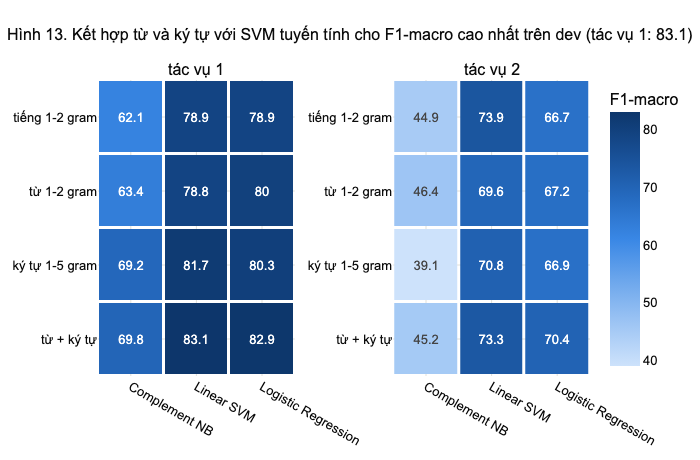

Tổ hợp tốt nhất mỗi tác vụ: {'tác vụ 2': {'biểu diễn': 'tiếng 1-2 gram', 'mô hình': 'Linear SVM', 'F1-macro dev': 73.94180339083721}, 'tác vụ 1': {'biểu diễn': 'từ + ký tự', 'mô hình': 'Linear SVM', 'F1-macro dev': 83.08065749926214}}


In [38]:
CLASSIFIERS = {
    "Complement NB": ComplementNB(),
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced"),
    "Linear SVM": LinearSVC(class_weight="balanced", max_iter=5000, random_state=SEED),
}


def make_pipeline(representation, classifier, extra_steps=()):
    """Pipeline: các vectorizer của biểu diễn (+ các bước phụ) rồi đến mô hình."""
    steps = [(step, clone(vec), col) for step, vec, col in REPRESENTATIONS[representation]]
    return Pipeline([("features", ColumnTransformer(steps + list(extra_steps))), ("model", clone(classifier))])


def f1_macro(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro") * 100


rows = []
for task in TASKS:
    baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train[task])
    rows.append({"tác vụ": task, "biểu diễn": "mốc cơ sở", "mô hình": "luôn đoán lớp đông nhất",
                 "F1-macro dev": f1_macro(y_dev[task], baseline.predict(X_dev)), "giây": 0.0})
    for representation, (clf_name, classifier) in itertools.product(REPRESENTATIONS, CLASSIFIERS.items()):
        start = time.perf_counter()
        model = make_pipeline(representation, classifier).fit(X_train, y_train[task])
        rows.append({"tác vụ": task, "biểu diễn": representation, "mô hình": clf_name,
                     "F1-macro dev": f1_macro(y_dev[task], model.predict(X_dev)), "giây": time.perf_counter() - start})
comparison = pd.DataFrame(rows)

fig = make_subplots(rows=1, cols=2, subplot_titles=list(TASKS), horizontal_spacing=0.2)
for i, task in enumerate(TASKS):
    grid = (comparison[(comparison["tác vụ"] == task) & (comparison["biểu diễn"] != "mốc cơ sở")]
            .pivot(index="biểu diễn", columns="mô hình", values="F1-macro dev").loc[list(REPRESENTATIONS)])
    fig.add_trace(go.Heatmap(z=grid.values, x=grid.columns, y=grid.index, colorscale=SEQ_BLUE, coloraxis="coloraxis",
                             text=grid.round(1).values, texttemplate="%{text}", xgap=3, ygap=3,
                             hovertemplate="%{y} + %{x}: F1-macro %{z:.1f}<extra></extra>"), row=1, col=i + 1)
best = comparison[comparison["biểu diễn"] != "mốc cơ sở"].sort_values("F1-macro dev").groupby("tác vụ").tail(1).set_index("tác vụ")
show_fig(fig, f"Kết hợp từ và ký tự với SVM tuyến tính cho F1-macro cao nhất trên dev "
              f"(tác vụ 1: {best.loc['tác vụ 1', 'F1-macro dev']:.1f})",
         height=460, yaxis_autorange="reversed", yaxis2_autorange="reversed",
         coloraxis=dict(colorscale=SEQ_BLUE, colorbar=dict(title="F1-macro")))
show_table(comparison.pivot_table(index=["biểu diễn", "mô hình"], columns="tác vụ", values="F1-macro dev", sort=False),
           "F1-macro (%) trên dev của mọi tổ hợp")
print("Tổ hợp tốt nhất mỗi tác vụ:", best[["biểu diễn", "mô hình", "F1-macro dev"]].to_dict("index"))

**Nhận xét.**
- **Mọi tổ hợp đều vượt xa mốc cơ sở** (42.1 ở tác vụ 1 và 21.1 ở tác vụ 2). Complement NB kém hơn hẳn hai mô hình tuyến tính (62 đến 70 ở tác vụ 1), nên không được xét tiếp.
- **Tác vụ 1: biểu diễn quan trọng hơn mô hình.** Với Linear SVM: tiếng 78.9, từ 78.8, ký tự 81.7, từ + ký tự 83.1.
- **Tiếng hay từ?** Tách từ giúp Logistic Regression thêm 1.1 điểm (78.9 lên 80.0) nhưng không giúp Linear SVM (78.9 và 78.8). Một lý do: 2-gram tiếng đã ghép lại được phần lớn từ ghép ("sản phẩm" là một 2-gram tiếng), nên tách từ trước không thêm nhiều thông tin.
- **Đặc trưng ký tự giúp nhiều nhất** (thêm 2.8 điểm so với tiếng khi dùng SVM), đúng như EDA dự đoán (4.5, 5.6): chúng giữ lại emoji, chữ lặp, chuỗi gõ bừa và văn bản không dấu mà bước làm sạch xóa mất. Kết hợp từ và ký tự cho kết quả tốt nhất, nên hai loại thông tin bổ sung cho nhau.
- **Tác vụ 2:** Linear SVM tốt nhất với cả bốn biểu diễn. Tiếng 1-2 gram (73.9) và từ + ký tự (73.3) gần như bằng nhau: dev chỉ có 25 review SPAM-1, nên chênh 0.6 điểm nằm trong mức may rủi.

**Quyết định.** Chọn Linear SVM, mô hình tốt nhất ở cả hai tác vụ. Biểu diễn thì chưa chốt ở đây: dev quá nhỏ để phân định các mức chênh dưới 1.5 điểm, nên 3 biểu diễn đứng đầu của Linear SVM ở mỗi tác vụ được so lại bằng kiểm định chéo ở 7.3.

### 7.3 Thêm dấu hiệu tự định nghĩa, số sao và chọn tham số bằng kiểm định chéo

Tập dev chỉ có 1590 review (25 review SPAM-1), nên chênh lệch dưới 1 điểm trên dev có thể chỉ là may rủi. Vì vậy các lựa chọn tiếp theo được quyết định bằng **kiểm định chéo 3 phần (3-fold cross-validation) trên tập train**: chia train thành 3 phần giữ nguyên tỷ lệ lớp, lần lượt học trên 2 phần và chấm trên phần còn lại, rồi lấy trung bình.

`GridSearchCV` thử mọi tổ hợp của:
- **có hay không** 10 cột dấu hiệu (6.2), được đưa về thang 0 đến 1 bằng `MaxAbsScaler` (chia cho giá trị lớn nhất) để cùng thang với các cột TF-IDF;
- **có hay không** số sao, mã hóa one-hot (5 cột 0/1, mỗi mức sao một cột) vì số sao là nhãn thứ bậc, không phải đại lượng liên tục;
- tham số điều chuẩn `C`: `C` nhỏ thì mô hình đơn giản hơn, ít học thuộc train hơn.

- **biểu diễn:** 3 biểu diễn đứng đầu của Linear SVM trên dev ở 7.2 (tác vụ 1: từ + ký tự, ký tự, tiếng; tác vụ 2: tiếng, từ + ký tự, ký tự).

Mỗi tác vụ có 3 × 2 × 2 × 4 = 48 tổ hợp, mỗi tổ hợp học 3 lần. Mọi tổ hợp dùng cùng 3 phần chia nên điểm so sánh được với nhau. Tổ hợp có F1-macro trung bình cao nhất được chọn.

In [39]:
EXTRA_STEPS = [("signals", MaxAbsScaler(), SIGNAL_FEATURES), ("rating", OneHotEncoder(handle_unknown="ignore"), [RATING_COL])]
C_GRID = {"Linear SVM": [0.1, 0.3, 1, 3], "Logistic Regression": [1, 3, 10, 30]}
N_CANDIDATES = 3      # số biểu diễn đứng đầu ở 7.2 được so lại bằng kiểm định chéo
cv_folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)   # mọi lần so sánh dùng cùng 3 phần

searches, final_representation, cv_summary = {}, {}, []
for task in TASKS:
    clf_name = best.loc[task, "mô hình"]
    candidates = (comparison[(comparison["tác vụ"] == task) & (comparison["mô hình"] == clf_name)]
                  .nlargest(N_CANDIDATES, "F1-macro dev")["biểu diễn"])
    param_grid = {"features__signals": [MaxAbsScaler(), "drop"],
                  "features__rating": [OneHotEncoder(handle_unknown="ignore"), "drop"],
                  "model__C": C_GRID[clf_name]}
    task_searches, task_tables = {}, []
    for representation in candidates:
        search = GridSearchCV(make_pipeline(representation, CLASSIFIERS[clf_name], EXTRA_STEPS), param_grid,
                              scoring="f1_macro", cv=cv_folds, n_jobs=-1)
        task_searches[representation] = search.fit(X_train, y_train[task])
        cv = pd.DataFrame(search.cv_results_)
        cv["biểu diễn"] = representation
        cv["dấu hiệu"] = np.where(cv["param_features__signals"].astype(str) == "drop", "không", "có")
        cv["số sao"] = np.where(cv["param_features__rating"].astype(str) == "drop", "không", "có")
        task_tables.append(cv)
        cv_summary.append({"tác vụ": task, "biểu diễn": representation,
                           "F1-macro dev (7.2)": comparison.loc[(comparison["tác vụ"] == task)
                                                                & (comparison["biểu diễn"] == representation)
                                                                & (comparison["mô hình"] == clf_name), "F1-macro dev"].iloc[0],
                           "F1-macro CV tốt nhất": search.best_score_ * 100,
                           "tham số tốt nhất": f"dấu hiệu: {cv.loc[search.best_index_, 'dấu hiệu']}, "
                                               f"số sao: {cv.loc[search.best_index_, 'số sao']}, C = {search.best_params_['model__C']}"})
    final_representation[task] = max(task_searches, key=lambda r: task_searches[r].best_score_)
    searches[task] = task_searches[final_representation[task]]
    show_table(pd.concat(task_tables).pivot_table(index=["biểu diễn", "dấu hiệu", "số sao"], columns="param_model__C",
                                                  values="mean_test_score", sort=False) * 100,
               f"{task} ({clf_name}): F1-macro (%) kiểm định chéo trên train theo C (cột)")

show_table(pd.DataFrame(cv_summary).set_index(["tác vụ", "biểu diễn"]),
           "Mỗi biểu diễn: điểm trên dev (7.2) và điểm kiểm định chéo tốt nhất", text_columns=["tham số tốt nhất"])
for task in TASKS:
    print(f"{task}: chọn {final_representation[task]}, tham số {searches[task].best_params_}, "
          f"F1-macro CV = {searches[task].best_score_ * 100:.1f}")

tác vụ 1: chọn từ + ký tự, tham số {'features__rating': OneHotEncoder(handle_unknown='ignore'), 'features__signals': MaxAbsScaler(), 'model__C': 0.3}, F1-macro CV = 84.4
tác vụ 2: chọn từ + ký tự, tham số {'features__rating': OneHotEncoder(handle_unknown='ignore'), 'features__signals': MaxAbsScaler(), 'model__C': 0.3}, F1-macro CV = 71.5


**Nhận xét.**
- **Kiểm định chéo đổi lựa chọn biểu diễn của tác vụ 2.** Ở tác vụ 1, thứ tự giống dev: từ + ký tự (84.4) hơn ký tự (83.5) và tiếng (81.0). Ở tác vụ 2, thứ tự đảo ngược: tiếng 1-2 gram đứng đầu trên dev (73.9) nhưng thấp nhất khi kiểm định chéo (68.7), còn từ + ký tự đạt 71.5. Kiểm định chéo chấm cả 14 295 review của train (195 review SPAM-1) thay vì 1590 review của dev (25 review SPAM-1), nên đáng tin hơn: mức hơn 0.6 điểm của tiếng trên dev chỉ là may rủi. **Cả hai tác vụ dùng từ + ký tự.**
- **Các dấu hiệu tự định nghĩa giúp nhiều nhất khi không có đặc trưng ký tự:** với tiếng 1-2 gram ở tác vụ 2, chúng thêm 2.6 điểm (66.1 lên 68.7 với `C = 0.3`), vì chúng bù lại những gì bước làm sạch đã xóa (ngắn, lặp chữ, có link, rỗng). Khi đã có đặc trưng ký tự, chúng chỉ thêm 0.3 đến 0.5 điểm ở tác vụ 1 và 0.3 điểm ở tác vụ 2, vì n-gram ký tự đã bắt được phần lớn thông tin này.
- **Số sao gần như không thay đổi gì** (chênh dưới 0.1 điểm khi đã có dấu hiệu), đúng với kết luận ở 5.4. `GridSearchCV` giữ số sao vì cao hơn rất ít; giữ lại cũng không làm mô hình kém đi.
- **`C = 0.3` tốt nhất ở mọi biểu diễn của cả hai tác vụ**: điều chuẩn mạnh hơn mặc định (`C = 1`) một chút, còn `C = 3` kém nhất. Mô hình đơn giản hơn thì tổng quát tốt hơn, có lẽ vì dữ liệu có nhiễu nhãn (4.4).

### 7.4 Có nên thay viết tắt bằng từ đầy đủ không?

4.6.4 đã hẹn thử phương án này ở bước mô hình. Ta thay mỗi tiếng viết tắt trong danh sách của 4.6.2 bằng từ đầy đủ ("ko" thành "không", "sp" thành "sản phẩm") trong cột `clean` và `words`, rồi so sánh hai phương án bằng cùng kiểm định chéo 3 phần, với mô hình tốt nhất của 7.3. Cột `prepared` (đặc trưng ký tự) giữ nguyên.

In [40]:
def expand_abbreviations(text):
    """Thay từng tiếng viết tắt bằng từ đầy đủ: "sp ok ko" -> "sản phẩm ok không"."""
    return re.sub(ABBREVIATION_PATTERN, lambda match: ABBREVIATIONS[match.group()], text)


print("Ví dụ:", expand_abbreviations("mũ đẹp lắm mn ơi size hơi nhỏ nhưng ko sao"))
X_train_expanded = X_train.assign(clean=X_train["clean"].map(expand_abbreviations),
                                  words=X_train["prepared"].map(expand_abbreviations).map(segment_words))
show_table(pd.DataFrame({task: {
    "giữ nguyên viết tắt": cross_val_score(clone(searches[task].best_estimator_), X_train, y_train[task],
                                           scoring="f1_macro", cv=cv_folds, n_jobs=-1).mean() * 100,
    "thay bằng từ đầy đủ": cross_val_score(clone(searches[task].best_estimator_), X_train_expanded, y_train[task],
                                           scoring="f1_macro", cv=cv_folds, n_jobs=-1).mean() * 100,
} for task in TASKS}), "F1-macro (%) kiểm định chéo trên train: giữ hay thay viết tắt", precision=2)

Ví dụ: mũ đẹp lắm mọi người ơi size hơi nhỏ nhưng không sao


,tác vụ 1,tác vụ 2
giữ nguyên viết tắt,84.39,71.52
thay bằng từ đầy đủ,84.38,71.43


**Nhận xét.** Hai phương án gần như bằng nhau: 84.39 và 84.38 ở tác vụ 1, 71.52 và 71.43 ở tác vụ 2. Chênh lệch tối đa 0.1 điểm, nhỏ hơn mức dao động giữa các giá trị `C` ở 7.3. Một lý do là mô hình đã tự học được "ko" và "không" mang cùng tín hiệu, vì cả hai đều xuất hiện nhiều trong train. **Quyết định: giữ nguyên viết tắt**, vì thay thế không mang lại lợi ích rõ ràng mà thêm một bước phụ thuộc vào danh sách tự lập.

### 7.5 Mô hình cuối cùng

Với mỗi tác vụ, mô hình cuối là tổ hợp tốt nhất của 7.3 (biểu diễn và tham số giữ cố định), giữ nguyên viết tắt theo 7.4. Bảng dưới kiểm tra lại trên dev, sau đó mô hình được **huấn luyện lại trên train + dev** để dùng thêm 1590 review cho bước đánh giá cuối trên test. Tập test chưa được dùng ở bất kỳ bước nào trước đây.

In [41]:
dev_rows, final_models = [], {}
for task in TASKS:
    tuned = searches[task].best_estimator_
    dev_rows.append({"tác vụ": task, "tổ hợp tốt nhất ở 7.2": best.loc[task, "F1-macro dev"],
                     "mô hình chọn ở 7.3": f1_macro(y_dev[task], tuned.predict(X_dev))})
    final_models[task] = clone(tuned).fit(pd.concat([X_train, X_dev], ignore_index=True),
                                          np.concatenate([y_train[task], y_dev[task]]))
dev_scores = pd.DataFrame(dev_rows).set_index("tác vụ")
show_table(dev_scores, "F1-macro (%) trên dev trước và sau 7.3")

,tổ hợp tốt nhất ở 7.2,mô hình chọn ở 7.3
tác vụ,,
tác vụ 1,83.1,84.0
tác vụ 2,73.9,74.7


**Nhận xét.** F1-macro trên dev tăng ở cả hai tác vụ, cùng chiều với kiểm định chéo: từ 83.1 lên 84.0 ở tác vụ 1, và từ 73.9 lên 74.7 ở tác vụ 2. Ở tác vụ 2, mô hình chọn ở 7.3 (từ + ký tự) cao hơn cả tổ hợp đứng đầu dev ở 7.2 (tiếng 1-2 gram), dù đã được chọn mà không nhìn vào dev. Tập test chỉ dùng để báo cáo kết quả của lựa chọn đã chốt ở đây (8.1), không dùng để chọn lại mô hình.

<a id="scrollTo=s8"></a>
## 8. Đánh giá trên tập test

### 8.1 Kết quả trên test và so sánh với bài báo

Đây là lần **duy nhất** tập test được dùng. Số liệu của bài báo (Van Dinh và cộng sự, 2022) lấy từ Bảng 8 của bài báo: accuracy và F1-macro trên cùng tập test của 3 mạng học sâu (TextCNN, LSTM, GRU) và 2 mô hình Transformer cho tiếng Việt (PhoBERT, BERT4News). Cột F1-macro dev là điểm của mô hình cuối trên dev khi mới học trên train (7.5), đặt cạnh điểm test để so sánh.

In [42]:
# Bảng 8 của bài báo (arXiv 2207.14636, trang 9): (accuracy tác vụ 1, tác vụ 2, F1-macro tác vụ 1, tác vụ 2)
PAPER_SCORES = {"TextCNN": (84.18, 83.42, 77.89, 64.74), "LSTM": (82.97, 83.35, 77.24, 66.58),
                "GRU": (83.50, 82.84, 77.67, 66.51), "PhoBERT": (90.01, 88.93, 86.89, 72.17),
                "BERT4News": (86.39, 86.20, 86.16, 62.62)}

test_pred = {task: final_models[task].predict(X_test) for task in TASKS}
score_rows = []
for i, task in enumerate(TASKS):
    majority = DummyClassifier(strategy="most_frequent").fit(X_train, y_train[task]).predict(X_test)
    score_rows.append({"mô hình": "mốc cơ sở (luôn đoán lớp đông nhất)", "tác vụ": task,
                       "accuracy test": accuracy_score(y_test[task], majority) * 100,
                       "F1-macro test": f1_macro(y_test[task], majority)})
    score_rows.append({"mô hình": "của nhóm: mô hình cuối (7.5)", "tác vụ": task,
                       "F1-macro dev": dev_scores.loc[task, "mô hình chọn ở 7.3"],
                       "accuracy test": accuracy_score(y_test[task], test_pred[task]) * 100,
                       "F1-macro test": f1_macro(y_test[task], test_pred[task])})
    for paper_model, scores in PAPER_SCORES.items():
        score_rows.append({"mô hình": f"bài báo: {paper_model}", "tác vụ": task,
                           "accuracy test": scores[i], "F1-macro test": scores[2 + i]})
test_scores = pd.DataFrame(score_rows).pivot_table(index="mô hình", columns="tác vụ", sort=False,
                                                   values=["F1-macro dev", "accuracy test", "F1-macro test"])
show_table(test_scores, "Kết quả (%); F1-macro dev chỉ có cho mô hình của nhóm (huấn luyện trên train, trước khi học lại trên train + dev)")
for task in TASKS:
    print(f"Mô hình cuối {task}: {final_representation[task]} + {best.loc[task, 'mô hình']}, tham số {searches[task].best_params_}")

Mô hình cuối tác vụ 1: từ + ký tự + Linear SVM, tham số {'features__rating': OneHotEncoder(handle_unknown='ignore'), 'features__signals': MaxAbsScaler(), 'model__C': 0.3}
Mô hình cuối tác vụ 2: từ + ký tự + Linear SVM, tham số {'features__rating': OneHotEncoder(handle_unknown='ignore'), 'features__signals': MaxAbsScaler(), 'model__C': 0.3}


**Nhận xét.**
- **Tác vụ 1: F1-macro 85.4** (accuracy 88.1%), gấp đôi mốc cơ sở (41.9) và cao hơn TextCNN, LSTM, GRU của bài báo 7.5 đến 8.2 điểm. Mô hình vẫn thấp hơn hai mô hình Transformer: khoảng 0.8 điểm so với BERT4News (86.2) và 1.5 điểm so với PhoBERT (86.9).
- **Tác vụ 2: F1-macro 76.3** (accuracy 88.1%), cao nhất bảng: hơn PhoBERT (72.2) khoảng 4 điểm, hơn TextCNN, LSTM, GRU 9.7 đến 11.6 điểm và hơn BERT4News (62.6) gần 14 điểm. Accuracy thì thấp hơn PhoBERT (88.9) một chút: `class_weight="balanced"` đổi một ít độ chính xác ở lớp đông NO-SPAM lấy khả năng nhận ra các lớp hiếm, đúng điều F1-macro đo.
- **Test cao hơn dev ở cả hai tác vụ** (84.0 lên 85.4 và 74.7 lên 76.3). Có hai lý do: mô hình chấm trên test đã được học lại trên train + dev, tức thêm 1590 review (khoảng 11% dữ liệu); và dev nhỏ, chỉ 25 review SPAM-1, nên điểm dev dao động nhiều hơn điểm test (gấp 2.5 lần dev). Test không được dùng cho lựa chọn nào trước đó, nên mức cao hơn này không phải do chọn mô hình theo test.
- Mô hình của nhóm là TF-IDF + SVM tuyến tính, huấn luyện vài giây trên CPU, trong khi PhoBERT và BERT4News cần GPU. Kết quả cho thấy các đặc trưng chọn từ EDA (ký tự, dấu hiệu tự định nghĩa) bù được phần lớn khoảng cách. **Lưu ý:** số liệu học sâu là do bài báo tự báo cáo, nhóm không chạy lại.
- Accuracy luôn cao hơn F1-macro vì NO-SPAM chiếm 72% tập test và là lớp dễ nhất: accuracy che mất lỗi ở các lớp hiếm, đúng như lý do chọn F1-macro ở 7.1.

### 8.2 Mỗi lớp được nhận ra tốt đến đâu?

- **Precision** của một lớp: trong các review mô hình gán vào lớp đó, bao nhiêu % là đúng.
- **Recall**: trong các review thật sự thuộc lớp đó, mô hình tìm ra bao nhiêu %.
- **Ma trận nhầm lẫn**: dòng là nhãn thật, cột là nhãn dự đoán; mỗi ô ghi số review và % của dòng.

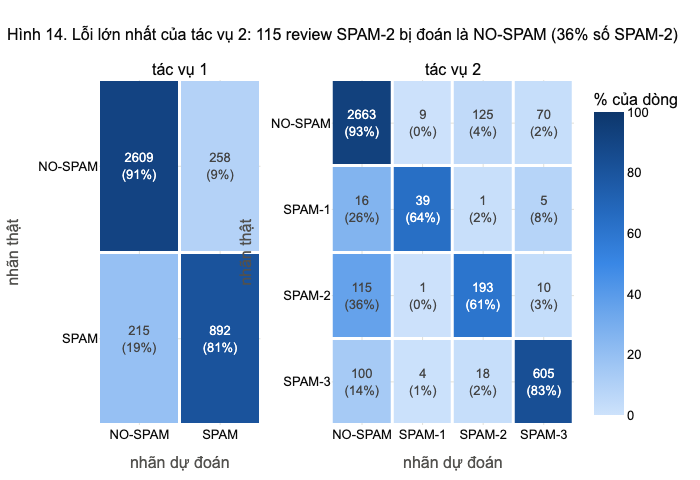

In [43]:
CLASS_LABELS = {"tác vụ 1": list(LABEL_NAMES.values()), "tác vụ 2": [name.split(" ")[0] for name in TYPE_NAMES.values()]}

report_rows = []
for task in TASKS:
    report = classification_report(y_test[task], test_pred[task], target_names=CLASS_LABELS[task], output_dict=True)
    for class_name in CLASS_LABELS[task]:
        report_rows.append({"tác vụ": task, "lớp": class_name, "số review": int(report[class_name]["support"]),
                            **{k: report[class_name][k] * 100 for k in ["precision", "recall", "f1-score"]}})
show_table(pd.DataFrame(report_rows).set_index(["tác vụ", "lớp"]), "Precision, recall và F1 (%) của từng lớp trên test")

fig = make_subplots(rows=1, cols=2, subplot_titles=list(TASKS), horizontal_spacing=0.15, column_widths=[0.4, 0.6])
for i, task in enumerate(TASKS):
    cm = confusion_matrix(y_test[task], test_pred[task])
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    names = CLASS_LABELS[task]
    fig.add_trace(go.Heatmap(z=cm_pct, x=names, y=names, coloraxis="coloraxis", xgap=3, ygap=3,
                             text=[[f"{format_number(n)}<br>({p:.0f}%)" for n, p in zip(row_n, row_p)] for row_n, row_p in zip(cm, cm_pct)],
                             texttemplate="%{text}", hovertemplate="thật %{y}, đoán %{x}: %{z:.1f}% của dòng<extra></extra>"),
                  row=1, col=i + 1)
    fig.update_xaxes(title_text="nhãn dự đoán", row=1, col=i + 1)
    fig.update_yaxes(title_text="nhãn thật", autorange="reversed", row=1, col=i + 1)
cm2 = confusion_matrix(y_test["tác vụ 2"], test_pred["tác vụ 2"])
show_fig(fig, f"Lỗi lớn nhất của tác vụ 2: {format_number(cm2[2, 0])} review SPAM-2 bị đoán là NO-SPAM "
              f"({cm2[2, 0] / cm2[2].sum():.0%} số SPAM-2)",
         height=480, coloraxis=dict(colorscale=SEQ_BLUE, cmin=0, cmax=100, colorbar=dict(title="% của dòng")))

**Nhận xét.**
- **Tác vụ 1:** NO-SPAM đạt F1 91.7, SPAM đạt 79.0. Recall của SPAM là 80.6%: cứ 5 review spam thì mô hình bỏ sót khoảng 1.
- **Tác vụ 2: SPAM-2 khó nhất** (F1 58.8, recall 60.5%). 115 review SPAM-2 (36%) bị đoán là NO-SPAM: đúng như EDA dự báo ở 5.7 (31% review thường cũng chỉ nói về giao hàng hay shop), và cũng là lỗi chính của PhoBERT trong bài báo (177 review SPAM-2 bị đoán là NO-SPAM).
- **SPAM-1** chỉ có 61 review trong test nhưng vẫn đạt F1 68.4, nhờ các văn mẫu copy-paste dễ nhận ra (5.10).
- **SPAM-3** đạt F1 85.4 (precision 87.7, recall 83.2): đặc trưng ký tự nhận ra tốt chuỗi gõ bừa và tin quảng cáo. Phần bị bỏ sót được phân tích ở 8.3.

### 8.3 Mô hình sai ở đâu và vì sao?

Với tác vụ 1, bảng đầu cho biết mỗi **loại** spam (theo nhãn của tác vụ 2) bị bỏ sót bao nhiêu, và bao nhiêu review thường bị báo nhầm là spam. Bảng sau là các review đoán sai, lấy ngẫu nhiên.

In [44]:
errors = test_set[[TEXT_COL, "type_name", "n_syllables"]].assign(
    true=y_test["tác vụ 1"], predicted=test_pred["tác vụ 1"])
errors["đúng?"] = errors["true"] == errors["predicted"]
by_type = errors.groupby("type_name").agg(**{"số review": ("đúng?", "size"), "% đoán đúng": ("đúng?", "mean"),
                                            "trung vị số tiếng": ("n_syllables", "median")})
by_type["% đoán đúng"] *= 100
show_table(by_type, "Tác vụ 1 trên test: tỷ lệ đoán đúng (spam hay không) theo loại review")

wrong = errors.loc[~errors["đúng?"]]
print(f"Đoán sai {format_number(len(wrong))} / {format_number(len(errors))} review ({len(wrong) / len(errors):.1%})")
wrong_examples = wrong.sample(frac=1, random_state=SEED).groupby("type_name").head(3).sort_values("type_name")
show_table(wrong_examples.assign(**{"dự đoán": wrong_examples["predicted"].map(LABEL_NAMES)})
           [["type_name", "dự đoán", TEXT_COL]].set_axis(["nhãn thật", "dự đoán", "review"], axis=1),
           "Ví dụ review bị đoán sai (3 review cho mỗi loại)", text_columns=["review"], hide_index=True)

,số review,% đoán đúng,trung vị số tiếng
type_name,,,
NO-SPAM,2867,91.0,21.0
SPAM-1 review giả,61,70.5,39.0
SPAM-2 chỉ nói shop/hãng,319,65.5,19.0
SPAM-3 không phải review,727,88.0,12.0


Đoán sai 473 / 3974 review (11.9%)


nhãn thật,dự đoán,review
NO-SPAM,SPAM,"Váy đỉnh, hong nói nhiều Video mang tc minh họa thui ạ Nma nên mua nha mn ơiiiiii Mình may mắn hay sao đó có hàng siu nhanh Mình m65 62kg cơ ạ, vẫn vừa xinh nhoaaaaa"
NO-SPAM,SPAM,"Hình ảnh lấy xu thui, mua lần thứ 2 r. Dùng okela lắm nhaaaaaaaa"
NO-SPAM,SPAM,Lúc cần sẽ đến thôi Đánh giá cho shop 5 sao vì sự nhiệt tình của shop
SPAM-1 review giả,NO-SPAM,"Hàng đẹp, giá cả phải chăng. Vote cho mọi người cùng mua dùng nhé"
SPAM-1 review giả,NO-SPAM,Trời ưi rấc nà xịn xò luôn nhaa!! Được tặng kèm quà xinh xinh rấc nà iu luôn ý 😍 mọi người nên mua ủng hộ shop nha ❤❤
SPAM-1 review giả,NO-SPAM,Chất lượng sản phẩm tuyệt vời 5* cho shop Chất lượng sản phẩm tuyệt vời 5* cho shop
SPAM-2 chỉ nói shop/hãng,NO-SPAM,"mình đặt hàng lúc sáng, nghĩ chắc mai mới giao tới, không ngờ 2 giờ chiều là nhận đc rồi. Hàng gói kỉ,shipper thân thiệt. chất lượng thì đợi sài vài hôm mới biết. sẽ ủng hộ tiếp nếu hàng ok."
SPAM-2 chỉ nói shop/hãng,NO-SPAM,"SÁNG ĐẶT HÀNG MUA NESCAFE, GIỜ ĐÃ NHẬN ĐƯỢC HÀNG RỒI, HÀNG DATE MỚI, GIÁ KHUYẾN MẠI, THẬT TUYỆT, LIKE CHO TIKI. MÌNH ĐÃ MUA HÀNG NHIỀU LẦN TẠI TIKI, CHẤT LƯỢNG LUÔN ĐÚNG NHƯ THÔNG BÁO, HY VỌNG TIKI LUÔN DUY TRÌ CẠNH TRANH VỀ GIÁ, VỀ CHẤT LƯỢNG VÀ THỜI HẠN GIAO HÀNG NHÉ, CÓ KM NHIỀU NHỚ TB ĐỂ TIẾP TỤC MUA HÀNG TẠI TIKI"
SPAM-2 chỉ nói shop/hãng,NO-SPAM,"đóng gói chắc chắn hộp ngoài có hơi méo do vận chuyển nhưng sản phẩm bên trong nguyên vẹn, có dùng vài loại khác của vasaline thấy cắp ẩm tốt da mềm mịn thử loại này xem có trắng hơn không"
SPAM-3 không phải review,NO-SPAM,"Ngôi nhà dù sang trọng đến đâu, bạn vẫn chỉ ngủ trên một chiếc giường. Ô tô dù có tốt đến đâu, vượt quá tốc độ vẫn bị phạt tiền. Túi xách dù đắt tiền đến đâu, cũng chỉ nhiều công dụng hơn một cái túi bóng bình thường Đừng vì mù quáng theo đuổi những thứ không thuộc về mình , mà quên đi hạnh phúc hi"


**Nhận xét.** Tỷ lệ đoán đúng theo loại: NO-SPAM 91.0%, SPAM-3 88.0%, SPAM-1 70.5%, SPAM-2 65.5%. Đọc các review bị đoán sai thấy bốn nguyên nhân:
1. **SPAM-2 giống review thường:** review kể chi tiết chuyện giao hàng rồi nhắc qua sản phẩm ("chất lượng thì đợi sài vài hôm mới biết", "sản phẩm bên trong nguyên vẹn"). Đây là ranh giới mờ đã thấy ở 5.7.
2. **SPAM-1 không dùng văn mẫu:** "Hàng đẹp, giá cả phải chăng. Vote cho mọi người cùng mua dùng nhé" đọc như một lời khen bình thường. 5.10 đã dự báo khoảng một nửa số review giả không dùng chuỗi chung nào.
3. **Nhãn đáng ngờ:** một số review SPAM-3 bị bỏ sót trông như review thường ("Hàng đóng gói sản phẩm cẩn thận, không móp méo, chất lượng sản phẩm khá ..."). Ngược lại, "Đánh giá cho shop 5 sao vì sự nhiệt tình của shop" bị gán NO-SPAM dù chỉ nói về shop, đúng định nghĩa SPAM-2. Đây là nhiễu nhãn, phù hợp với độ đồng thuận kappa 0.68 đến 0.72 của người gán nhãn (mục 3).
4. **Review thường viết kiểu "teen":** chữ lặp ("nhoaaaaa", "nhaaaaaaaa") và nhắc "lấy xu" là những dấu hiệu mô hình học được từ spam (5.6), nên các review thật viết theo kiểu này bị báo nhầm.

### 8.4 41 review test có bản sao trong train làm điểm cao lên bao nhiêu?

4.4 tìm thấy 41 review test có nội dung y hệt một review trong train. Nếu mô hình chỉ "nhớ" các câu này, điểm trên test sẽ bị thổi phồng. Ta tính lại điểm sau khi bỏ chúng ra.

In [45]:
not_copied = ~test_set.index.isin(test_copied.index)
show_table(pd.DataFrame({task: {"toàn bộ test": f1_macro(y_test[task], test_pred[task]),
                                f"bỏ {(~not_copied).sum()} review có bản sao": f1_macro(y_test[task][not_copied], test_pred[task][not_copied])}
                         for task in TASKS}), "F1-macro (%) trên test, có và không có các review trùng với train")

,tác vụ 1,tác vụ 2
toàn bộ test,85.4,76.3
bỏ 41 review có bản sao,85.3,76.3


**Nhận xét.** Bỏ 41 review trùng với train, F1-macro chỉ đổi 0.1 điểm (85.4 thành 85.3 ở tác vụ 1, 76.3 giữ nguyên ở tác vụ 2). Phần rò rỉ này không thổi phồng kết quả, nên quyết định giữ nguyên tập test ở 4.4 và 6.1 là hợp lý.

### 8.5 Mô hình dựa vào những đặc trưng nào?

Mô hình tuyến tính gán cho mỗi cột một **trọng số**: trọng số dương đẩy review về phía SPAM, trọng số âm đẩy về phía NO-SPAM. Hình dưới là 15 **từ hoặc cặp từ** có trọng số lớn nhất mỗi phía của mô hình tác vụ 1. Đặc trưng ký tự khó đọc hơn nên được liệt kê riêng trong bảng; dấu cách ở đầu hoặc cuối một chuỗi ký tự cho biết chuỗi đó nằm ở đầu hoặc cuối một từ.

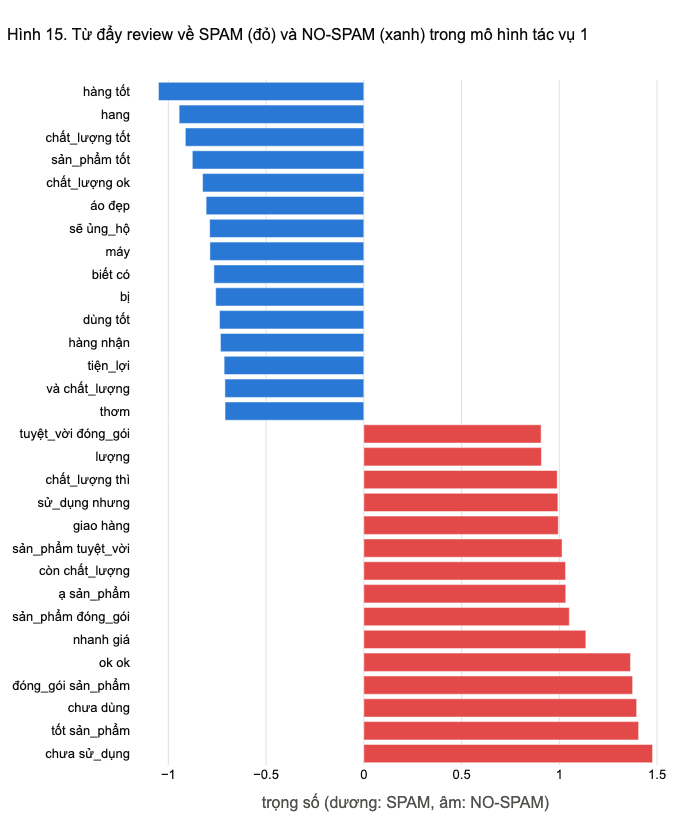

đẩy về NO-SPAM,đẩy về SPAM
"','",'j'
"', '",' '
'c',': '
'm','aaaaa'
' s','ưa'
'.','hưa'
'm ','hưa '
'ng','chưa'
' c','chưa '
't ','ưa '


,chứa 'j',chứa ': '
type_name,,
NO-SPAM,1.4,1.1
SPAM-1 review giả,0.0,10.8
SPAM-2 chỉ nói shop/hãng,2.1,0.2
SPAM-3 không phải review,31.2,7.5


,trọng số
rating__Rating_2,-0.143
signals__has_abbreviation,-0.101
rating__Rating_1,-0.098
rating__Rating_3,-0.034
signals__has_emoji,0.036
signals__no_diacritics,0.112
signals__has_repeat,0.131
rating__Rating_4,0.159
signals__has_newline,0.178
rating__Rating_5,0.275


In [46]:
task1_model = final_models["tác vụ 1"]
feature_names = task1_model.named_steps["features"].get_feature_names_out()
weights = pd.Series(task1_model.named_steps["model"].coef_[0], index=feature_names)
word_weights = weights[weights.index.str.startswith("words__")]
top_words = pd.concat([word_weights.nsmallest(15), word_weights.nlargest(15).iloc[::-1]])
fig = go.Figure(go.Bar(x=top_words.values, y=[name.split("__", 1)[1] for name in top_words.index], orientation="h",
                       marker_color=[RED if w > 0 else BLUE for w in top_words],
                       hovertemplate="%{y}: trọng số %{x:.2f}<extra></extra>"))
show_fig(fig, "Từ đẩy review về SPAM (đỏ) và NO-SPAM (xanh) trong mô hình tác vụ 1",
         height=820, xaxis_title="trọng số (dương: SPAM, âm: NO-SPAM)", yaxis_autorange="reversed")

char_weights = weights[weights.index.str.startswith("chars__")]
show_table(pd.DataFrame({"đẩy về NO-SPAM": [repr(n.split("__", 1)[1]) for n in char_weights.nsmallest(10).index],
                         "đẩy về SPAM": [repr(n.split("__", 1)[1]) for n in char_weights.nlargest(10).index]}),
           "10 chuỗi ký tự có trọng số lớn nhất mỗi phía", hide_index=True)
# Hai chuỗi ký tự đẩy về SPAM mạnh nhất: chúng có trong bao nhiêu % review của mỗi lớp (tập train)?
char_check = pd.DataFrame({f"chứa {s!r}": train[TEXT_COL].str.lower().str.contains(s, regex=False)
                           .groupby(train["type_name"]).mean() * 100 for s in ["j", ": "]})
show_table(char_check, "% review của mỗi lớp (tập train) chứa hai chuỗi ký tự đẩy về SPAM mạnh nhất")
signal_weights = weights[[name for name in weights.index if name.startswith(("signals__", "rating__"))]]
if len(signal_weights):
    show_table(signal_weights.sort_values().rename("trọng số").to_frame(), "Trọng số của các dấu hiệu và số sao", precision=3)

**Nhận xét.** Trọng số của mô hình khớp với các phát hiện của EDA:
- **Đẩy về SPAM:** "chưa sử_dụng" (trọng số lớn nhất), "chưa dùng", "còn chất_lượng", "chất_lượng thì": đúng nhóm "chưa dùng nên chưa biết" của SPAM-2 (5.7, 5.9). Các cặp từ chung chung như "đóng_gói sản_phẩm", "sản_phẩm tuyệt_vời", "ok ok" là các mảnh của review khen chung chung và văn mẫu (5.10).
- **Đẩy về NO-SPAM:** các nhận xét cụ thể về sản phẩm ("hàng tốt", "chất_lượng tốt", "áo đẹp", "máy", "thơm", "tiện_lợi") và cả "bị" (người mua kể lỗi thật của sản phẩm).
- **Ký tự:** dấu phẩy và dấu chấm đẩy về NO-SPAM (review thật thường viết thành câu có ngắt), còn "aaaaa" (chữ lặp) và các mảnh của "chưa" đẩy về SPAM. Ba chuỗi đẩy về SPAM mạnh nhất cần giải thích thêm:
  - `'j'`: tiếng Việt không có chữ j, nên chữ này gần như chỉ gặp trong chuỗi gõ bừa ("hdjdjfkfjfj", phím j nằm giữa bàn phím) và chữ nước ngoài. Bảng thứ hai: 31.2% review SPAM-3 có chữ j, so với 1.4% review thường.
  - `': '` (dấu hai chấm rồi dấu cách): văn bản trình bày dạng danh sách hay thông số, như "Dung tích: 300ml" hay "Bước 1: Truy cập ..." trong tin quảng cáo và hướng dẫn nhận voucher. Có trong 10.8% SPAM-1 và 7.5% SPAM-3, so với 1.1% review thường.
  - `' '` (một dấu cách): `char_wb` thêm dấu cách vào hai đầu mỗi từ nên review nào cũng có chuỗi này. Vector TF-IDF của mỗi review được chuẩn hóa về độ dài 1, nên review càng ít chuỗi ký tự khác (review ngắn) thì cột này càng lớn. Trọng số dương của nó vì vậy là một tín hiệu "review ngắn", cùng chiều với dấu hiệu tối đa 3 tiếng.
- **Dấu hiệu:** độ dài, lặp chữ từ 10 lần, tối đa 3 tiếng, có link và rỗng sau chuẩn hóa đều đẩy về SPAM, đúng như bản đồ nhiệt ở 5.6. Có viết tắt đẩy về NO-SPAM, khớp với 4.6.2. Số sao 5 đẩy nhẹ về SPAM, 1 và 2 sao đẩy về NO-SPAM, khớp với 5.4, nhưng các trọng số này nhỏ.

<a id="scrollTo=s9"></a>
## 9. Dự đoán review mới

Review mới đi qua **đúng** các bước của dữ liệu huấn luyện: `model_inputs` (chuẩn hóa, tách từ, tính dấu hiệu) rồi đến mô hình cuối. Các review dưới đây do nhóm **tự viết** để thử mô hình (không có trong dữ liệu), gồm cả trường hợp khó: review thật nhưng ngắn, và review chỉ khen giao hàng.

In [47]:
NEW_REVIEWS = [
    ("Áo mặc vừa, vải dày dặn, giặt máy không bị phai màu. Đường may hơi lỗi ở tay áo nhưng chấp nhận được.", 4),
    ("Giao hàng nhanh, đóng gói cẩn thận, shipper thân thiện. Chưa dùng nên chưa biết chất lượng.", 5),
    ("Sản phẩm rất xinh đẹp tuyệt vời, tôi không thể trông đợi gì hơn. Cảm ơn nhà cung cấp, cảm ơn người vận chuyển.", 5),
    ("Truy cap ngay www.khuyenmai-hot.vn de nhan qua tang 500k, soan DK gui 9029", 5),
    ("tốt", 5),
]
new_inputs = model_inputs([text for text, _ in NEW_REVIEWS], [stars for _, stars in NEW_REVIEWS])
show_table(pd.DataFrame({
    "review": [text for text, _ in NEW_REVIEWS],
    "số sao": [stars for _, stars in NEW_REVIEWS],
    "tác vụ 1": pd.Series(final_models["tác vụ 1"].predict(new_inputs)).map(LABEL_NAMES),
    "tác vụ 2": pd.Series(final_models["tác vụ 2"].predict(new_inputs)).map(TYPE_NAMES),
}), "Dự đoán cho các review do nhóm tự viết", text_columns=["review"], hide_index=True)

review,số sao,tác vụ 1,tác vụ 2
"Áo mặc vừa, vải dày dặn, giặt máy không bị phai màu. Đường may hơi lỗi ở tay áo nhưng chấp nhận được.",4,NO-SPAM,NO-SPAM
"Giao hàng nhanh, đóng gói cẩn thận, shipper thân thiện. Chưa dùng nên chưa biết chất lượng.",5,SPAM,SPAM-2 chỉ nói shop/hãng
"Sản phẩm rất xinh đẹp tuyệt vời, tôi không thể trông đợi gì hơn. Cảm ơn nhà cung cấp, cảm ơn người vận chuyển.",5,SPAM,SPAM-1 review giả
"Truy cap ngay www.khuyenmai-hot.vn de nhan qua tang 500k, soan DK gui 9029",5,SPAM,SPAM-3 không phải review
tốt,5,SPAM,SPAM-3 không phải review


**Nhận xét.** Bốn review đầu được đoán đúng như mong đợi: review mô tả sản phẩm cụ thể là NO-SPAM; review chỉ khen giao hàng và "chưa dùng nên chưa biết chất lượng" là SPAM-2; review chép văn mẫu là SPAM-1; tin quảng cáo không dấu có link là SPAM-3. Review chỉ có một chữ "tốt" bị đoán là SPAM-3. Theo định nghĩa của bài báo, một chữ "tốt" không đánh giá gì cụ thể, và tập train có nhiều câu ngắn tương tự bị gán SPAM-3 (4.4: "hài lòng", "rất hài lòng"). Mô hình đã học đúng quy ước của người gán nhãn, dù người dùng thật có thể thấy kết quả này khắt khe.

<a id="scrollTo=s10"></a>
## 10. Kết luận

### 10.1 Tóm tắt kết quả trên tập test (F1-macro %)

| Mô hình | Tác vụ 1 (spam hay không) | Tác vụ 2 (4 lớp) |
|---|---|---|
| Mốc cơ sở (luôn đoán NO-SPAM) | 41.9 | 21.0 |
| TextCNN / LSTM / GRU (bài báo) | 77.2 đến 77.9 | 64.7 đến 66.6 |
| BERT4News (bài báo) | 86.2 | 62.6 |
| PhoBERT (bài báo) | **86.9** | 72.2 |
| **Của nhóm:** TF-IDF + dấu hiệu + Linear SVM | 85.4 (accuracy 88.1%) | **76.3** (accuracy 88.1%) |

Mô hình của cả hai tác vụ dùng từ 1-2 gram và ký tự 1-5 gram, thêm 10 dấu hiệu tự định nghĩa và số sao, `C = 0.3`. Ở tác vụ 1, mô hình kém PhoBERT 1.5 điểm và BERT4News khoảng 0.8 điểm; ở tác vụ 2, mô hình cao nhất bảng.

### 10.2 Các câu hỏi đã được trả lời

1. **Review giả có phải văn mẫu không?** Một phần: 49% SPAM-1 dùng lại một chuỗi 6 tiếng chung và 21% dán nguyên một trong hai văn mẫu (Hình 12). Nhờ vậy SPAM-1 vẫn đạt F1 68.4 dù chỉ có 195 review để học; phần còn bỏ sót là các review giả không dùng văn mẫu (8.3).
2. **Tiếng hay từ?** Khi đứng một mình, tách từ chỉ hơn đếm tiếng tối đa 1.1 điểm (Hình 13), vì 2-gram tiếng đã ghép lại được phần lớn từ ghép. Thông tin bị bước làm sạch xóa mất quan trọng hơn nhiều: đặc trưng ký tự thêm 2.8 điểm trên dev ở tác vụ 1 (7.2); ở tác vụ 2, kiểm định chéo cho từ + ký tự 71.5 so với 68.7 của tiếng 1-2 gram, dù cả hai đã có dấu hiệu tự định nghĩa (7.3).
3. **Số sao có giúp không?** Gần như không: 96% spam và 93% review thường đều 5 sao (Hình 6), và thêm số sao vào mô hình thay đổi dưới 0.1 điểm khi đã có dấu hiệu (7.3).
4. **Lỗi nằm ở đâu?** Chủ yếu ở SPAM-2: 36% bị đoán là review thường (Hình 14), đúng ranh giới mờ mà EDA đã chỉ ra ở 5.7 và cũng là lỗi chính của PhoBERT.
5. **Rò rỉ giữa train và test có làm sai kết quả không?** Không: bỏ 41 review trùng chỉ làm F1-macro đổi tối đa 0.1 điểm (8.4).
6. **Chọn mô hình trên dev có đủ không?** Không: ở tác vụ 2, biểu diễn đứng đầu dev (tiếng 1-2 gram) lại thấp nhất khi kiểm định chéo. Dev chỉ có 25 review SPAM-1, nên các lựa chọn cuối cùng dựa vào kiểm định chéo trên train (7.3).

### 10.3 Hạn chế

- **Dữ liệu:** nhiễu nhãn (kappa 0.68 đến 0.72, có 7 nội dung bị gán nhãn mâu thuẫn); SPAM-1 rất ít (195 review train, 61 review test) nên F1 của lớp này dao động mạnh; một phần review bị cắt ở 300 ký tự khi thu thập.
- **Phương pháp:** danh sách viết tắt, các nhóm chủ đề, các dấu hiệu và ngưỡng của chúng do nhóm tự định nghĩa; công cụ tách từ sai với văn bản không dấu và khi thiếu dấu câu; mô hình theo túi từ không hiểu ngữ cảnh dài hay giọng mỉa mai.
- **Đánh giá:** chỉ một cách chia train / dev / test của tác giả; tập dev nhỏ nên các lựa chọn được quyết định bằng kiểm định chéo; số liệu học sâu lấy từ bài báo, không chạy lại trong cùng điều kiện; các review ở phần 9 chỉ là vài ví dụ tự viết.

### 10.4 Hướng mở rộng

- Fine-tune PhoBERT trên cùng dữ liệu đã làm sạch (6.1) để so sánh công bằng, và thử ghép xác suất của PhoBERT với các dấu hiệu tự định nghĩa.
- Chỉnh ngưỡng quyết định của tác vụ 1 trên dev để đổi precision lấy recall khi sàn muốn bắt được nhiều spam hơn.
- Gán nhãn lại các review ngắn bị mâu thuẫn (4.4, 8.3) để giảm nhiễu nhãn.